<h1 style="color:#008080; font-weight:bold;">
Progetto di Data Mining
</h1>
<h3 style="color:#008080;">Premier League Event Data 2020-2021</h3> 

L'obiettivo di questo progetto è analizzare un dataset non documentato contenente gli eventi delle partite della Premier League 2020-2021.

Il lavoro è stato organizzato in quattro fasi principali:

<ol>
  <li>interpretazione e descrizione del dataset;</li>
  <li>ricostruzione delle partite e feature extraction;</li>
  <li>analisi esplorativa dei dati (EDA);</li>
  <li>classificazione del risultato della partita.</li>
</ol>

<style>
ol li::marker {
  color: #008080;
}
</style> 

Il dataset originale è strutturato a livello di evento, pertanto è stato necessario trasformarlo in un dataset aggregato a livello di squadra-partita, al fine di rendere possibile l’analisi statistica e l’applicazione di modelli di machine learning.

<h4 style="color:#007FFF;">Preparazione dell'ambiente di lavoro</h4>

Come prima operazione, sono state importate tutte le librerie necessarie per l'intero ciclo del progetto:

<ul>
  <li><i>Pandas e NumPy</i> per la manipolazione dei dataframe, l'aggregazione e il calcolo vettoriale/matriciale;</li>
  <li><i>Matplotlib e Seaborn</i> per la visualizzazione dei grafici e l'Exploratory Data Analysis (EDA);</li>
  <li><i>Tabulate</i> per stampare le tabelle finali in un formato elegante e leggibile;</li>
  <li><i>Scikit-learn (Model Selection & Preprocessing)</i> per la suddivisione dei dati (train/test), la cross-validazione (StratifiedKFold), la normalizzazione (StandardScaler) e la ricerca degli iperparametri (RandomizedSearchCV);</li>
  <li><i>Scikit-learn (Classifiers)</i> per l'implementazione di modelli di riferimento come Decision Tree, Random Forest, SVM (SVC) e Naive Bayes;</li>
  <li><i>Scikit-learn (Metrics & Exceptions)</i> per la valutazione dei modelli tramite metriche complete (Accuracy, Balanced Accuracy, Precision, Recall, F1-Score, Confusion Matrix) e la gestione dei warning metrici;</li>
  <li><i>XGBoost</i> per l'implementazione di algoritmi avanzati di Gradient Boosting ad alte prestazioni.</li>
</ul>

<style>
ul li::marker {
  color: #007FFF;
}
</style>

Infine, è stato impostato il tema grafico standard (whitegrid) e sono stati filtrati i warning di sistema non critici per garantire un output del notebook pulito e professionale.

In [75]:
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)  

<h4 style="color:#007FFF;">Caricamento e pulizia iniziale del dataset</h4>

In questa fase viene letto il dataset originale degli eventi della Premier League 2020-2021 a partire da un file CSV salvandone le occorrenze all'interno di un DataFrame Pandas. 

Successivamente viene effettuata una prima operazione di pulizia dei dati, verificando la presenza di eventuali colonne puramente tecniche (<code>Unnamed: 0</code>), generate automaticamente da salvataggi precedenti del file CSV. Qualora sia presente viene eliminata, dato che non aggiunge alcuna informazione sull'evento sportivo ai fini dell'analisi. 

Infine, viene effettuata una prima esplorazione del dataset per verificarne la struttura, analizzando:
<ul>
  <li>la dimensione (numero di righe e colonne);</li>
  <li>le prime osservazioni;</li>
  <li>l’elenco delle variabili presenti.</li>
</ul>

<style>
ul li::marker {
  color: #007FFF;
}
</style>

In [76]:
df = pd.read_csv("20-21_plEventsData.csv", low_memory=False)

if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

df.shape 

(607656, 34)

Il dataset contiene oltre 600.000 eventi e 34 variabili, confermando la granularità dei dati.

In [77]:
pd.set_option('display.max_columns', None)

df.head().style.set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#003399'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('padding', '6px'),
        ('white-space', 'nowrap')
    ]},
    {'selector': 'td', 'props': [
        ('background-color', '#007FFF'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('padding', '6px'),
        ('white-space', 'nowrap')
    ]},
    {'selector': 'th.row_heading', 'props': [
        ('background-color', '#003399'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('white-space', 'nowrap')
    ]},
    {'selector': 'table', 'props': [
        ('border-collapse', 'collapse')
    ]}
])

,id,eventId,minute,second,teamId,x,y,expandedMinute,qualifiers,satisfiedEventsTypes,isTouch,period_value,period_displayName,type_value,type_displayName,outcomeType_value,outcomeType_displayName,playerId,endX,endY,relatedEventId,relatedPlayerId,goalMouthZ,goalMouthY,isShot,blockedX,blockedY,cardType_value,cardType_displayName,isGoal,name,position,shirtNo,isOwnGoal
0,2253487473.000000,2,0,0.000000,32,0.000000,0.000000,0,[],[],False,1,FirstHalf,32,Start,1,Successful,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
1,2253487469.000000,1000003,0,0.000000,184,0.000000,0.000000,0,[],[],False,1,FirstHalf,32,Start,1,Successful,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
2,2253487625.000000,1000004,0,0.000000,184,50.300000,50.300000,0,"[{'type': {'value': 213, 'displayName': 'Angle'}, 'value': '3.1'}, {'type': {'value': 178, 'displayName': 'StandingSave'}}, {'type': {'value': 141, 'displayName': 'PassEndY'}, 'value': '50.3'}, {'type': {'value': 212, 'displayName': 'Length'}, 'value': '20.8'}, {'type': {'value': 140, 'displayName': 'PassEndX'}, 'value': '30.5'}, {'type': {'value': 56, 'displayName': 'Zone'}, 'value': 'Back'}]","[90, 116, 29, 34, 214, 217]",True,1,FirstHalf,1,Pass,1,Successful,79050.000000,30.500000,50.300000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,Ashley Westwood,MC,18.000000,nan
3,2253487639.000000,1000005,0,2.000000,184,29.600000,53.400000,0,"[{'type': {'value': 178, 'displayName': 'StandingSave'}}, {'type': {'value': 213, 'displayName': 'Angle'}, 'value': '5.0'}, {'type': {'value': 212, 'displayName': 'Length'}, 'value': '21.7'}, {'type': {'value': 141, 'displayName': 'PassEndY'}, 'value': '23.3'}, {'type': {'value': 140, 'displayName': 'PassEndX'}, 'value': '36.4'}, {'type': {'value': 56, 'displayName': 'Zone'}, 'value': 'Back'}]","[90, 116, 29, 35, 37, 215, 217]",True,1,FirstHalf,1,Pass,1,Successful,131464.000000,36.400000,23.300000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,James Tarkowski,DC,5.000000,nan
4,2253487685.000000,1000006,0,7.000000,184,41.300000,18.400000,0,"[{'type': {'value': 1, 'displayName': 'Longball'}}, {'type': {'value': 213, 'displayName': 'Angle'}, 'value': '0.7'}, {'type': {'value': 56, 'displayName': 'Zone'}, 'value': 'Center'}, {'type': {'value': 178, 'displayName': 'StandingSave'}}, {'type': {'value': 141, 'displayName': 'PassEndY'}, 'value': '73.1'}, {'type': {'value': 210, 'displayName': 'ShotAssist'}}, {'type': {'value': 155, 'displayName': 'Chipped'}}, {'type': {'value': 140, 'displayName': 'PassEndX'}, 'value': '86.0'}, {'type': {'value': 212, 'displayName': 'Length'}, 'value': '59.9'}, {'type': {'value': 11113, 'displayName': 'KeyPass'}}]","[90, 118, 116, 122, 123, 126, 204, 38, 45, 35, 36, 216, 217]",True,1,FirstHalf,1,Pass,1,Successful,80067.000000,86.000000,73.100000,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,Matthew Lowton,DR,2.000000,nan


In [78]:
df_cols = pd.DataFrame(df.columns, columns=["Colonne"])

df_cols.style.set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#007FFF'),
        ('color', 'white'),
        ('border', '1px solid white')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
]).set_properties(**{
    'background-color': '#003399',
    'color': 'white'
})

,Colonne
0,id
1,eventId
2,minute
3,second
4,teamId
5,x
6,y
7,expandedMinute
8,qualifiers
9,satisfiedEventsTypes


<h4 style="color:#007FFF;">Struttura del dataset</h4>

Il dataset è di tipo event-based e descrive in modo dettagliato tutte le azioni di gioco avvenute durante le partite.  
Ogni riga rappresenta un singolo evento ed è caratterizzata da un insieme di variabili che descrivono il contesto temporale, spaziale e tecnico dell’azione.

Di seguito vengono descritte tutte le variabili presenti nel dataset:

<ul>
  <li><code>id</code>: identificatore univoco globale del record all'interno dell'intero database;</li>
  <li><code>eventId</code>: identificatore numerico progressivo dell'evento per quella specifica squadra in quella partita;</li>
  <li><code>minute</code>: minuto di gioco ufficiale in cui si è verificato l'evento;</li>
  <li><code>second</code>: secondo esatto all'interno del minuto in cui si è verificato l'evento;</li>
  <li><code>teamId</code>: codice numerico identificativo della squadra che ha compiuto l'azione;</li>
  <li><code>x</code>: coordinata spaziale orizzontale (%) di partenza dell'evento;</li>
  <li><code>y</code>: coordinata spaziale verticale (%) di partenza dell'evento;</li>
  <li><code>expandedMinute</code>: minuto cronologico continuo effettivo, fondamentale per conteggiare linearmente i minuti di recupero oltre il 45' e il 90';</li>
  <li><code>qualifiers</code>: lista in formato dizionario di parametri tecnici aggiuntivi (es. tipo di passaggio, condizioni particolari);</li>
  <li><code>satisfiedEventsTypes</code>: lista di sotto-eventi soddisfatti associati all’azione;</li>
  <li><code>isTouch</code>: valore booleano che indica se l'evento è scaturito da un tocco fisico del pallone;</li>
  <li><code>period_value</code>: indice numerico della frazione di gioco;</li>
  <li><code>period_displayName</code>: stringa esplicativa del periodo di gioco in corso (<i>FirstHalf</i>, <i>SecondHalf</i>, <i>PostGame</i>, <i>PreMatch</i>);</li>
  <li><code>type_value</code>: codice numerico identificativo della tipologia dell'azione;</li>
  <li><code>type_displayName</code>: descrizione del tipo di evento svolto (eventi relativi alla gestione del pallone, alla fase offensiva, alla fase difensiva, alle infrazioni e palle inattive, alle azioni specifiche del portiere, agli errori gravi e palle perse o agli eventi di controllo tattico e amministrativo);</li>
  <li><code>outcomeType_value</code>: codice numerico sull'esito dell'azione intrapresa;</li>
  <li><code>outcomeType_displayName</code>: descrizione dell’esito (<i>Successful</i>, <i>Unsuccessful</i>);</li>
  <li><code>playerId</code>: codice numerico identificativo univoco del singolo giocatore coinvolto nell'evento;</li>
  <li><code>endX</code>: coordinata spaziale orizzontale (%) esatta in cui è terminato l'evento o il passaggio;</li>
  <li><code>endY</code>: coordinata spaziale verticale (%) di termine stimato dell'evento;</li>
  <li><code>relatedEventId</code>: identificativo di un pre-evento strettamente concatenato all'azione documentata in riga;</li>
  <li><code>relatedPlayerId</code>: identificativo di un giocatore correlato all’evento;</li>
  <li><code>goalMouthZ</code>: altezza millimetrica della coordinata della palla rispetto alla linea e ai montanti della porta;</li>
  <li><code>goalMouthY</code>: coordinata sull'asse destro o sinistro che descrive in che esatto punto dello specchio della porta finisce il pallone;</li>
  <li><code>isShot</code>: segnalino booleano in caso l'azione corrisponda ufficialmente a un tiro in porta;</li>
  <li><code>blockedX</code>: precisa X spaziale dove un difensore immolatosi è riuscito a bloccare/deviare con un tocco un potenziale tiro in porta;</li>
  <li><code>blockedY</code>: relativa Y dove è avvenuto il muro o la respinta in area;</li>
  <li><code>cardType_value</code>: ID identificativo in caso di estrazione di penalità disciplinare;</li>
  <li><code>cardType_displayName</code>: stringa esplicita del colore del cartellino (<i>Yellow</i>, <i>Red</i>, <i>SecondYellow</i>);</li>
  <li><code>isGoal</code>: valore booleano che certifica che una determinata dinamica si è infine tramutata in rete;</li>
  <li><code>name</code>: stringa con il vero nome e cognome decodificato del relativo protagonista in playerId;</li>
  <li><code>position</code>: sigla del ruolo in campo vestito tatticamente dal giocatore al momento dell'evento (difesa: <i>GK</i>, <i>DC</i>, <i>DR</i>, <i>DL</i>; centrocampo: <i>MC</i>, <i>DMC</i>, <i>ML</i>, <i>MR</i>, <i>AMC</i>, <i>AML</i>, <i>AMR</i>, <i>DML</i>, <i>DMR</i>; attacco: <i>FW</i>, <i>FWL</i>, <i>FWR</i>; panchina: <i>Sub</i>);</li>
  <li><code>shirtNo</code>: numero formale di maglia sfoggiato dal calciatore in quella giornata;</li>
  <li><code>isOwnGoal</code>: variabile booleana per separare analiticamente i casi di autorete da una segnatura a favore canonica.</li>
</ul>

<style>
ul li::marker {
  color: #007FFF;
}
</style>

Questa struttura consente una rappresentazione estremamente dettagliata delle azioni di gioco, ma non è direttamente adatta ad analisi a livello di partita.

Per questo motivo, nelle fasi successive, il dataset viene trasformato aggregando gli eventi a livello di squadra-partita, costruendo feature sintetiche utili per l’analisi e per i modelli di classificazione.

<h4 style="color:#007FFF;">Mappatura delle squadre</h4>

Nel dataset originale ogni squadra della Premier League è codificata tramite un identificativo numerico primario (`teamId`), mentre il nome della squadra non è esplicitamente presente.

Poiché ai fini operativi e dell'estrazione di feature non è utile né leggibile mantenere dei semplici codici, è stato creato un dizionario di mappatura fisso.
Questa operazione traduce in massa tutti i `teamId` nel reale valore di stringa e crea la nuova colonna `team_name`, ossia il nome della squadra.
  

Questa associazione è stata ricavata analizzando i giocatori, tramite la variabile `name`, presenti negli eventi e riconducendoli alle rispettive squadre.
Per ciascun `teamId` vengono mostrati alcuni nomi di giocatori associati, così da controllare che l’associazione sia coerente con le squadre reali.

La sostituzione della variabile `teamId` con `team_name` consente di migliorare la leggibilità del dataset e facilita le successive operazioni di aggregazione e analisi.

In [79]:
teamid_players = (
    df[["teamId", "name"]]
    .dropna()
    .drop_duplicates()
    .groupby("teamId")["name"]
    .apply(lambda x: ", ".join(x.head(3)))
    .reset_index()
    .rename(columns={"name": "players_sample"})
    .sort_values("teamId")
)

teamid_players["squadra"] = [
    "Arsenal", 
    "Leicester City", 
    "Chelsea", 
    "Southampton", 
    "Leeds United", 
    "Newcastle United", 
    "Aston Villa", 
    "Liverpool", 
    "West Ham United", 
    "Tottenham Hotspur", 
    "Everton", 
    "Manchester United", 
    "Wolverhampton Wanderers", 
    "Crystal Palace", 
    "Sheffield United", 
    "Manchester City", 
    "Fulham", 
    "West Bromwich Albion", 
    "Burnley", 
    "Brighton & Hove Albion"
]

teamid_players = teamid_players[["teamId", "squadra", "players_sample"]]

teamid_players.style.set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#ADD8E6'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('padding', '6px')
    ]},
    {'selector': 'td', 'props': [
        ('background-color', '#007FFF'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('padding', '6px')
    ]},
    {'selector': 'th.row_heading', 'props': [
        ('background-color', '#ADD8E6'),
        ('color', 'white'),
        ('border', '1px solid white')
    ]},
    {'selector': 'table', 'props': [
        ('border-collapse', 'collapse')
    ]}
])

,teamId,squadra,players_sample
0,13,Arsenal,"Kieran Tierney, Granit Xhaka, Alexandre Lacazette"
1,14,Leicester City,"Timothy Castagne, Wilfred Ndidi, Çaglar Söyüncü"
2,15,Chelsea,"Marcos Alonso, Ruben Loftus-Cheek, Kurt Zouma"
3,18,Southampton,"James Ward-Prowse, Jack Stephens, Oriol Romeu"
4,19,Leeds United,"Luke Ayling, Pablo Hernández, Stuart Dallas"
5,23,Newcastle United,"Isaac Hayden, Jonjo Shelvey, Andy Carroll"
6,24,Aston Villa,"Matthew Cash, Ezri Konsa Ngoyo, Emiliano Martínez"
7,26,Liverpool,"Naby Keita, Joseph Gomez, Jordan Henderson"
8,29,West Ham United,"Tomas Soucek, Lukasz Fabianski, Jarrod Bowen"
9,30,Tottenham Hotspur,"Dele Alli, Eric Dier, Ben Davies"


In [80]:
team_map = {
    13: "Arsenal",
    14: "Leicester City",
    15: "Chelsea",
    18: "Southampton",
    19: "Leeds United",
    23: "Newcastle United",
    24: "Aston Villa",
    26: "Liverpool",
    29: "West Ham United",
    30: "Tottenham Hotspur",
    31: "Everton",
    32: "Manchester United",
    161: "Wolverhampton Wanderers",
    162: "Crystal Palace",
    163: "Sheffield United",
    167: "Manchester City",
    170: "Fulham",
    175: "West Bromwich Albion",
    184: "Burnley",
    211: "Brighton & Hove Albion"
}

df["team_name"] = df["teamId"].map(team_map)

df = df.drop(columns=["teamId"])

Dall’analisi dei giocatori associati a ciascun identificativo emerge una corrispondenza coerente tra `teamId` e squadre.

Questo conferma la correttezza della mappatura adottata, permettendo di sostituire definitivamente l’identificativo numerico con il nome della squadra e migliorare l’interpretabilità del dataset nelle successive fasi di analisi.

<h4 style="color:#007FFF;">Verifica del numero di partite</h4>

Il dataset originale non contiene una colonna col numero o l'ID della partita, pertanto va dedotto quante partite sono state effettivamente giocate partendo dagli eventi grezzi.

Ogni singolo match genera esattamente due eventi di tipo *Start* (fischio d'inizio) durante il primo tempo (*FirstHalf*), uno per ciascuna delle due squadre in campo. 
Pertanto, il numero totale di partite dell'intero campionato può essere calcolato dividendo per 2 il numero totale di eventi *Start* del primo tempo.

In [81]:
start_events = df[df["type_displayName"] == "Start"].copy()
first_half_start = start_events[start_events["period_displayName"] == "FirstHalf"].copy()

start_events["period_displayName"].value_counts()  

period_displayName
FirstHalf     760
SecondHalf    760
Name: count, dtype: int64

In [82]:
numero_partite = int(len(first_half_start) / 2)
numero_partite

380

L’analisi degli eventi di inizio del primo tempo mostra la presenza di 760 eventi *Start* nel *FirstHalf*.

Poiché ogni partita coinvolge due squadre, il numero totale di partite è pari a: 760 / 2 = 380

Questo valore è perfettamente coerente con la struttura reale della Premier League 2020-2021, composta da 20 squadre e 380 partite complessive.

<h4 style="color:#99CBFF;">Ricostruzione delle partite</h4>

Viene affrontato il problema della mancanza di un identificativo condiviso per singola gara. 

Dal momento che i fischi d'inizio del primo tempo sono sempre a coppie può essere ricostruito l'intero calendario del campionato in questa specifica stagione.

Creando un ciclo for iterativo a salti di due, vengono accoppiate le squadre e costruita una tabella che assegni dinamicamente una nuova chiave **`match_id`** (es. da 1 a 380) per le successive fasi analitiche del dataset.

In [83]:
start_first_half = df[
    (df["type_displayName"] == "Start") &
    (df["period_displayName"] == "FirstHalf")
].copy().reset_index(drop=True)

matches = []

for i in range(0, len(start_first_half), 2):
    team1 = start_first_half.loc[i, "team_name"]
    team2 = start_first_half.loc[i + 1, "team_name"]

    matches.append({
        "match_id": i // 2 + 1,
        "team1": team1,
        "team2": team2
    })

matches_df = pd.DataFrame(matches)

matches_df_20 = matches_df.head(20)

styled_table = matches_df_20.style.set_properties(**{
    'background-color': '#99CBFF',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#4682B4'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
])

styled_table

,match_id,team1,team2
0,1,Manchester United,Burnley
1,2,Aston Villa,Manchester City
2,3,Southampton,Crystal Palace
3,4,Arsenal,Fulham
4,5,Liverpool,Leeds United
5,6,Everton,Tottenham Hotspur
6,7,West Bromwich Albion,Leicester City
7,8,West Ham United,Newcastle United
8,9,Chelsea,Brighton & Hove Albion
9,10,Wolverhampton Wanderers,Sheffield United


In [84]:
len(matches_df) 

380

In [85]:
matches_df["team1"].nunique(), matches_df["team2"].nunique() 

(20, 20)

<p>
La tabella matches_df rappresenta la ricostruzione delle partite della stagione.
</p>

<p>Ogni riga contiene:</p>

<ul>
  <li>un identificatore univoco della partita (<code>match_id</code>);</li>
  <li>la prima squadra (team1);</li>
  <li>la seconda squadra (team2).</li>
</ul>

<p>
La procedura ha permesso di ricostruire correttamente 380 partite, in linea con il numero atteso per la stagione di Premier League 2020-2021.
</p>

<p>
Inoltre, il fatto che siano presenti 20 squadre distinte sia nella colonna team1 che nella colonna team2 conferma la correttezza della ricostruzione.
</p>

<style>
ul li::marker {
  color: #99CBFF;
}
</style>

<h4 style="color:#99CBFF;">Assegnazione del match_id agli eventi</h4>

Una volta ricostruita la tabella delle partite, è necessario associare ogni evento del dataset alla partita di appartenenza.

Questa operazione consente di trasformare il dataset da una struttura puramente event-based a una struttura aggregabile a livello di squadra e partita.

L’assegnazione del `match_id` avviene identificando gli eventi di inizio del primo tempo e utilizzandoli come riferimento per suddividere sequenzialmente il dataset nelle diverse partite.

In [86]:
df = df.reset_index(drop=True)

start_mask = (
    (df["type_displayName"] == "Start") &
    (df["period_displayName"] == "FirstHalf")
)

start_indices = df[start_mask].index.tolist()

match_ids = []
current_match = 0
next_start_pointer = 0

for i in range(len(df)):
    if next_start_pointer < len(start_indices) and i == start_indices[next_start_pointer]:
        current_match += 1
        next_start_pointer += 2

    match_ids.append(current_match)

df["match_id"] = match_ids  

df["match_id"].nunique()

380

In [87]:
table=df[["match_id", "team_name", "type_displayName", "period_displayName"]].head(10) 

styled_table = table.style.set_properties(**{
    'background-color': '#99CBFF',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#1E90FF'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
])

styled_table

,match_id,team_name,type_displayName,period_displayName
0,1,Manchester United,Start,FirstHalf
1,1,Burnley,Start,FirstHalf
2,1,Burnley,Pass,FirstHalf
3,1,Burnley,Pass,FirstHalf
4,1,Burnley,Pass,FirstHalf
5,1,Burnley,MissedShots,FirstHalf
6,1,Manchester United,Pass,FirstHalf
7,1,Manchester United,Pass,FirstHalf
8,1,Burnley,Interception,FirstHalf
9,1,Manchester United,BallTouch,FirstHalf


L’assegnazione del `match_id` a ciascun evento rende possibile aggregare le informazioni a livello di partita.

Questo passaggio è fondamentale, poiché consente di costruire un dataset in cui ogni riga rappresenta la prestazione di una squadra in una determinata partita.

<h4 style="color:#99CBFF;">Feature Extraction a livello di partita e squadra</h4>

Grazie alla chiave `match_id` si entra nel cuore della vera manipolazione dei dati: la feature extraction. 
L'obiettivo è abbandonare la struttura puramente event-based per costruire un set di dati in cui ogni riga rappresenti tutte le prestazioni riassunte di una determinata squadra in una determinata partita.

Vengono filtrati solo gli eventi cruciali del campo (come falli, gol, tiri, passaggi completati) contandone e sommandone esattamente le occorrenze per partita per ambo le parti. 

Come accorgimento di Data Engineering, viene costruito un dataframe scheletro (all_teams_matches_df) utile a forzare il rispetto strettissimo del contenitore: compiendo un incrocio vettoriale left join, se una squadra avesse per assurdo registrato zero occorrenze di una specifica abilità prestazionale in quella partia, si prevede asimmetria nel dataset iniettando direttamente il valore 0 al posto della mancanza d'informazione.

In [88]:
event_features = [
    "Pass",
    "Goal",
    "MissedShots",
    "SavedShot",
    "ShotOnPost",
    "Foul",
    "Tackle",
    "Interception",
    "Clearance",
    "BallRecovery",
    "Aerial",
    "TakeOn",
    "Card"
]

all_teams_matches = []

for _, row in matches_df.iterrows():
    all_teams_matches.append({
        "match_id": row["match_id"],
        "team_name": row["team1"]
    })
    all_teams_matches.append({
        "match_id": row["match_id"],
        "team_name": row["team2"]
    })

all_teams_matches_df = pd.DataFrame(all_teams_matches)

table = all_teams_matches_df.head(20)

styled_table = table.style.set_properties(**{
    'background-color': '#6495ED;',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#99CBFF;'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
])

styled_table

,match_id,team_name
0,1,Manchester United
1,1,Burnley
2,2,Aston Villa
3,2,Manchester City
4,3,Southampton
5,3,Crystal Palace
6,4,Arsenal
7,4,Fulham
8,5,Liverpool
9,5,Leeds United


In [89]:
features_df = (
    df[df["type_displayName"].isin(event_features)]
    .groupby(["match_id", "team_name", "type_displayName"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

features_df = all_teams_matches_df.merge(
    features_df,
    on=["match_id", "team_name"],
    how="left"
).fillna(0)
features_df.head(20)

table = features_df.head(20)

styled_table = table.style.set_properties(**{
    'background-color': '#99CBFF',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#1560BD'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
])

styled_table

,match_id,team_name,Aerial,BallRecovery,Card,Clearance,Foul,Goal,Interception,MissedShots,Pass,SavedShot,ShotOnPost,Tackle,TakeOn
0,1,Manchester United,34,60,2,19,28,1,10,2,606,10,0,12,12
1,1,Burnley,34,57,1,19,28,0,11,6,374,5,0,5,8
2,2,Aston Villa,32,38,4,29,19,0,15,4,308,7,0,14,14
3,2,Manchester City,32,50,0,11,19,2,11,6,674,19,1,14,23
4,3,Southampton,59,44,1,18,25,0,9,3,638,6,0,28,13
5,3,Crystal Palace,59,60,2,23,25,1,12,2,285,2,0,15,18
6,4,Arsenal,13,42,2,11,24,3,18,3,666,6,1,12,10
7,4,Fulham,13,46,2,11,24,0,10,2,560,3,0,11,12
8,5,Liverpool,26,71,1,11,15,4,14,3,490,15,0,13,35
9,5,Leeds United,26,56,0,35,15,3,12,1,504,2,0,34,15


<p>
Nel processo di aggregazione dei dati a livello di singola partita, è stato selezionato un set di 13 variabili chiave (event_features) che descrivono l'andamento tecnico e disciplinare di ogni club.
</p>

<p>
Di seguito ne viene fornita la descrizione analitica per una corretta interpretazione dei risultati:
</p>

<table style="border-collapse: collapse; ">
  <thead>
    <tr>
      <th style="border:1px solid #99CBFF; padding:6px; color:#99CBFF;">Feature</th>
      <th style="border:1px solid #99CBFF; padding:6px; color:#99CBFF;">Descrizione</th>
      <th style="border:1px solid #99CBFF; padding:6px; color:#99CBFF;">Ambito</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>Pass</code></td><td style="border:1px solid #99CBFF; padding:6px;">Passaggi completati con successo</td><td style="border:1px solid #99CBFF; padding:6px;">Manovra</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>Goal</code></td><td style="border:1px solid #99CBFF; padding:6px;">Reti segnate</td><td style="border:1px solid #99CBFF; padding:6px;">Attacco</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>MissedShots</code></td><td style="border:1px solid #99CBFF; padding:6px;">Conclusioni terminate fuori dallo specchio</td><td style="border:1px solid #99CBFF; padding:6px;">Attacco</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>SavedShot</code></td><td style="border:1px solid #99CBFF; padding:6px;">Tiri diretti in porta parati o bloccati</td><td style="border:1px solid #99CBFF; padding:6px;">Attacco</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>ShotOnPost</code></td><td style="border:1px solid #99CBFF; padding:6px;">Tiri che hanno colpito pali o traverse</td><td style="border:1px solid #99CBFF; padding:6px;">Attacco</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>TakeOn</code></td><td style="border:1px solid #99CBFF; padding:6px;">Dribbling e duelli 1-vs-1 vinti</td><td style="border:1px solid #99CBFF; padding:6px;">Attacco</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>Tackle</code></td><td style="border:1px solid #99CBFF; padding:6px;">Interventi diretti per la riconquista palla</td><td style="border:1px solid #99CBFF; padding:6px;">Difesa</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>Interception</code></td><td style="border:1px solid #99CBFF; padding:6px;">Palloni intercettati sulle linee avversarie</td><td style="border:1px solid #99CBFF; padding:6px;">Difesa</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>Clearance</code></td><td style="border:1px solid #99CBFF; padding:6px;">Rinvii d'emergenza dall'area di rigore</td><td style="border:1px solid #99CBFF; padding:6px;">Difesa</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>BallRecovery</code></td><td style="border:1px solid #99CBFF; padding:6px;">Recuperi di palloni non controllati</td><td style="border:1px solid #99CBFF; padding:6px;">Difesa</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>Aerial</code></td><td style="border:1px solid #99CBFF; padding:6px;">Contrasti aerei e colpi di testa vinti</td><td style="border:1px solid #99CBFF; padding:6px;">Difesa</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>Foul</code></td><td style="border:1px solid #99CBFF; padding:6px;">Totale falli commessi sanzionati</td><td style="border:1px solid #99CBFF; padding:6px;">Disciplina</td></tr>
    <tr><td style="border:1px solid #99CBFF; padding:6px;"><code>Card</code></td><td style="border:1px solid #99CBFF; padding:6px;">Sanzioni (cartellini gialli e rossi)</td><td style="border:1px solid #99CBFF; padding:6px;">Disciplina</td></tr>
  </tbody>
</table>

<p>
Questa catalogazione trasforma la natura caotica del dataset originario in un'anagrafe ordinata di performance aggregate, su cui verrà costruito l'intero processo di data mining.
</p>

<h4 style="color:#99CBFF;">Estrazione delle feature spaziali</h4>

Il dataset originale contiene anche le coordinate planimetriche `x` e `y` di esecuzione di ciascun evento.

Calcolando spazialmente la media matematica del punto d'inizio (`x`, `y`) e di fine (`endX`, `endY`) di tutte le giocate compiute da un determinato team all'interno di un match, si può approssimarne il baricentro in campo. 

Così facendo, si arricchisce la features_df con quattro indicatori tattici che permetteranno, ad esempio, all'algoritmo di classificazione di capire se una squadra ha giocato con una difesa schiacciata in basso o se ha mantenuto un baricentro molto offensivo nella metà campo avversaria.

In [90]:
spatial_features = (
    df.groupby(["match_id", "team_name"])[["x", "y", "endX", "endY"]]
    .mean()
    .reset_index()
    .rename(columns={
        "x": "mean_x",
        "y": "mean_y",
        "endX": "mean_endX",
        "endY": "mean_endY"
    })
) 

features_df = features_df.merge(
    spatial_features,
    on=["match_id", "team_name"],
    how="left"
)

table = features_df.head(20)

styled_table = table.style.set_properties(**{
    'background-color': '#5E86C1',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#99CBFF'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
])

styled_table

,match_id,team_name,Aerial,BallRecovery,Card,Clearance,Foul,Goal,Interception,MissedShots,Pass,SavedShot,ShotOnPost,Tackle,TakeOn,mean_x,mean_y,mean_endX,mean_endY
0,1,Manchester United,34,60,2,19,28,1,10,2,606,10,0,12,12,47.421763,46.811719,54.481021,48.712440
1,1,Burnley,34,57,1,19,28,0,11,6,374,5,0,5,8,44.071298,53.667939,52.765152,55.199747
2,2,Aston Villa,32,38,4,29,19,0,15,4,308,7,0,14,14,37.148997,52.906522,47.925444,57.001183
3,2,Manchester City,32,50,0,11,19,2,11,6,674,19,1,14,23,53.136611,49.748536,57.383866,52.231977
4,3,Southampton,59,44,1,18,25,0,9,3,638,6,0,28,13,44.835616,46.926765,51.305649,49.084733
5,3,Crystal Palace,59,60,2,23,25,1,12,2,285,2,0,15,18,44.892026,53.337002,58.040575,54.395847
6,4,Arsenal,13,42,2,11,24,3,18,3,666,6,1,12,10,44.391991,50.974485,46.149632,52.846097
7,4,Fulham,13,46,2,11,24,0,10,2,560,3,0,11,12,43.809819,45.589793,48.750175,46.927797
8,5,Liverpool,26,71,1,11,15,4,14,3,490,15,0,13,35,53.391187,45.136720,59.831610,47.855268
9,5,Leeds United,26,56,0,35,15,3,12,1,504,2,0,34,15,35.083806,52.091253,42.352661,52.475596


<h4 style="color:#99CBFF;">Aggiunta della squadra avversaria</h4>

Per ogni squadra in ogni partita, viene aggiunta l’informazione relativa alla squadra avversaria.

Questa variabile (`opponent`) è utile per confrontare direttamente le prestazioni delle due squadre all’interno della stessa partita e per arricchire il dataset finale con un’informazione contestuale rilevante.  

In [91]:
opponent_rows = []

for _, row in matches_df.iterrows():
    opponent_rows.append({
        "match_id": row["match_id"],
        "team_name": row["team1"],
        "opponent": row["team2"]
    })
    opponent_rows.append({
        "match_id": row["match_id"],
        "team_name": row["team2"],
        "opponent": row["team1"]
    })

opponent_df = pd.DataFrame(opponent_rows)

features_df = features_df.merge(
    opponent_df,
    on=["match_id", "team_name"],
    how="left"
)

table = features_df.head(20)

styled_table = table.style.set_properties(**{
    'background-color': '#99CBFF',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#1E90FF'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
])

styled_table

,match_id,team_name,Aerial,BallRecovery,Card,Clearance,Foul,Goal,Interception,MissedShots,Pass,SavedShot,ShotOnPost,Tackle,TakeOn,mean_x,mean_y,mean_endX,mean_endY,opponent
0,1,Manchester United,34,60,2,19,28,1,10,2,606,10,0,12,12,47.421763,46.811719,54.481021,48.712440,Burnley
1,1,Burnley,34,57,1,19,28,0,11,6,374,5,0,5,8,44.071298,53.667939,52.765152,55.199747,Manchester United
2,2,Aston Villa,32,38,4,29,19,0,15,4,308,7,0,14,14,37.148997,52.906522,47.925444,57.001183,Manchester City
3,2,Manchester City,32,50,0,11,19,2,11,6,674,19,1,14,23,53.136611,49.748536,57.383866,52.231977,Aston Villa
4,3,Southampton,59,44,1,18,25,0,9,3,638,6,0,28,13,44.835616,46.926765,51.305649,49.084733,Crystal Palace
5,3,Crystal Palace,59,60,2,23,25,1,12,2,285,2,0,15,18,44.892026,53.337002,58.040575,54.395847,Southampton
6,4,Arsenal,13,42,2,11,24,3,18,3,666,6,1,12,10,44.391991,50.974485,46.149632,52.846097,Fulham
7,4,Fulham,13,46,2,11,24,0,10,2,560,3,0,11,12,43.809819,45.589793,48.750175,46.927797,Arsenal
8,5,Liverpool,26,71,1,11,15,4,14,3,490,15,0,13,35,53.391187,45.136720,59.831610,47.855268,Leeds United
9,5,Leeds United,26,56,0,35,15,3,12,1,504,2,0,34,15,35.083806,52.091253,42.352661,52.475596,Liverpool


<style>
ul li::marker,
ol li::marker {
  color: #99CBFF;
}
</style>

<h4 style="color:#99CBFF;">Gestione del tabellino: correzione delle autoreti</h4>

<p>
Il conteggio grezzo degli eventi di tipo <code>Goal</code> nasconde un'insidia logica colossale tipica dei dataset sportivi: le autoreti (<code>isOwnGoal</code>).
</p>

<p>
Se un difensore devia sfortunatamente la palla nella propria rete, il sistema attribuisce tecnicamente l'evento <code>Goal</code> a lui e al suo team.
</p>

<p>
Per risolvere questa asimmetria concettuale, la strategia consiste nel filtrare ogni singola rete e sfruttare la colonna <code>opponent</code>:
</p>

<ul>
<li>se <code>isOwnGoal</code> == <i>False</i>, il gol viene assegnato legittimamente alla squadra associata all’evento originario;</li>
<li>se <code>isOwnGoal</code> == <i>True</i>, il gol è ufficialmente un’autorete e ne viene quindi riassegnato d'ufficio il merito alla squadra avversaria.</li>
</ul>

<p>
Per gestire correttamente questo aspetto è stato necessario eseguire tre passaggi:
</p>

<ol>
<li>incrociare a ciascun evento di gol andato a buon fine della squadra in questione la rispettiva squadra avversaria;</li>
<li>creare la variabile temporanea <code>scoring_team</code>, che incanala la squadra a cui attribuire effettivamente la rete secondo il filtro condizionale appena descritto;</li>
<li>ricalcolare il volume totale dei gol raggruppandoli per singola partita e singola squadra, in modo da ricavare in sostituzione la variabile definitiva e affidabile <code>goals</code>.</li>
</ol>

<p>
Questo passaggio di vera igiene dei dati è fondamentale per ottenere:
</p>

<ul>
<li>un conteggio esatto dei gol segnati in stagione;</li>
<li>garantire una determinazione logica dei risultati fisici della partita;</li>
<li>tracciare le premesse per una ricostruzione perfettamente accurata della classifica di fine campionato.</li>
</ul>

In [92]:
goal_events = df[df["type_displayName"] == "Goal"].copy()

goal_events = goal_events.merge(
    opponent_df,
    on=["match_id", "team_name"],
    how="left"
)

goal_events["scoring_team"] = np.where(
    goal_events["isOwnGoal"] == True,
    goal_events["opponent"],
    goal_events["team_name"]
)

goals_corrected = (
    goal_events.groupby(["match_id", "scoring_team"])
    .size()
    .reset_index(name="goals_corrected")
    .rename(columns={"scoring_team": "team_name"})
)

features_df = features_df.drop(columns=["goals"], errors="ignore")

features_df = features_df.merge(
    goals_corrected,
    on=["match_id", "team_name"],
    how="left"
)

features_df["goals"] = features_df["goals_corrected"].fillna(0).astype(int)

features_df = features_df.drop(columns=["goals_corrected"])

features_df = features_df.drop(columns=["Goal"], errors="ignore")

table = features_df.head(20)

styled_table = table.style.set_properties(**{
    'background-color': '#99CBFF',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#0000CD'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
])

styled_table

,match_id,team_name,Aerial,BallRecovery,Card,Clearance,Foul,Interception,MissedShots,Pass,SavedShot,ShotOnPost,Tackle,TakeOn,mean_x,mean_y,mean_endX,mean_endY,opponent,goals
0,1,Manchester United,34,60,2,19,28,10,2,606,10,0,12,12,47.421763,46.811719,54.481021,48.712440,Burnley,1
1,1,Burnley,34,57,1,19,28,11,6,374,5,0,5,8,44.071298,53.667939,52.765152,55.199747,Manchester United,0
2,2,Aston Villa,32,38,4,29,19,15,4,308,7,0,14,14,37.148997,52.906522,47.925444,57.001183,Manchester City,0
3,2,Manchester City,32,50,0,11,19,11,6,674,19,1,14,23,53.136611,49.748536,57.383866,52.231977,Aston Villa,2
4,3,Southampton,59,44,1,18,25,9,3,638,6,0,28,13,44.835616,46.926765,51.305649,49.084733,Crystal Palace,0
5,3,Crystal Palace,59,60,2,23,25,12,2,285,2,0,15,18,44.892026,53.337002,58.040575,54.395847,Southampton,1
6,4,Arsenal,13,42,2,11,24,18,3,666,6,1,12,10,44.391991,50.974485,46.149632,52.846097,Fulham,3
7,4,Fulham,13,46,2,11,24,10,2,560,3,0,11,12,43.809819,45.589793,48.750175,46.927797,Arsenal,0
8,5,Liverpool,26,71,1,11,15,14,3,490,15,0,13,35,53.391187,45.136720,59.831610,47.855268,Leeds United,4
9,5,Leeds United,26,56,0,35,15,12,1,504,2,0,34,15,35.083806,52.091253,42.352661,52.475596,Liverpool,3


<style>
ul li::marker {
  color: #99CBFF;
}
</style>

<h4 style="color:#99CBFF;">Costruzione di feature derivate</h4>

<p>
La stesura di nuove feature a partire da quelle preesistenti è la vera chiave di volta per sintetizzare concetti sportivi estremamente ramificati in numeri facili da ingerire per i successivi modelli di Machine Learning.
</p>

<p>
Attualmente, il dataset divide le conclusioni a rete in tante categorie separate: goal, tiri parati, pali colpiti e tiri finiti fuori. Per valutare meglio la forza d'attacco di una squadra, è molto più efficace unire questi dati in due grandi indicatori riassuntivi:
</p>

<ul>
<li><code>total_shots</code> (tiri totali): rappresenta il volume offensivo complessivo prodotto da una squadra. Si ottiene semplicemente sommando tutti i tipi di tiro, inclusi quelli sbagliati (gol, tiri fuori bersaglio, parati dal portiere e pali);</li>
<li><code>shots_on_target</code> (tiri nello specchio della porta): misura l'effettiva precisione e pericolosità di una squadra. In questo caso si contano solo i tiri che hanno centrato la porta (goal, parate e pali), escludendo dal conteggio i tiri finiti totalmente fuori bersaglio.</li>
</ul>

In [93]:
features_df["total_shots"] = (
    features_df["goals"] +
    features_df["MissedShots"] +
    features_df["SavedShot"] +
    features_df["ShotOnPost"]
)

features_df["shots_on_target"] = (
    features_df["goals"] +
    features_df["SavedShot"] +
    features_df["ShotOnPost"]
)

colonne_dimostrative = ["team_name", "goals", "MissedShots", "SavedShot", "ShotOnPost", "total_shots", "shots_on_target"]
table = features_df[colonne_dimostrative].head(10)

styled_table = table.style.set_properties(**{
    'background-color': '#99CBFF',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#0095B6'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
])

styled_table

,team_name,goals,MissedShots,SavedShot,ShotOnPost,total_shots,shots_on_target
0,Manchester United,1,2,10,0,13,11
1,Burnley,0,6,5,0,11,5
2,Aston Villa,0,4,7,0,11,7
3,Manchester City,2,6,19,1,28,22
4,Southampton,0,3,6,0,9,6
5,Crystal Palace,1,2,2,0,5,3
6,Arsenal,3,3,6,1,13,10
7,Fulham,0,2,3,0,5,3
8,Liverpool,4,3,15,0,22,19
9,Leeds United,3,1,2,0,6,5


<h4 style="color:#99CBFF;">Stima del possesso palla (metodo proxy)</h4>

Il dataset originale non fornisce una misura diretta del possesso palla in termini di tempo. In ambito di Data Mining sportivo, è prassi comune sopperire a questa mancanza creando una proxy del possesso: una variabile sintetica che esprime il controllo del gioco attraverso la somma degli eventi proattivi.

Per costruire questa metrica, sono state aggregate quattro tipologie di eventi che riflettono il dominio tecnico sul pallone: `Pass`, `BallRecovery`, `TakeOn` e `Aerial`.

Oltre al valore assoluto, viene calcolata la differenza di possesso rispetto all'avversario (`possession_diff`) e il rapporto relativo all'interno del match (`possession_ratio`), permettendo di identificare con una variabile binaria (`possession_advantage`) quale squadra ha effettivamente tenuto in mano il pallino del gioco.

In [94]:
features_df["possession_proxy"] = (
    features_df["Pass"] +
    features_df["BallRecovery"] +
    features_df["TakeOn"] +
    features_df["Aerial"]
)

features_df["possession_diff"] = features_df.groupby("match_id")["possession_proxy"].transform(
    lambda x: x - x.iloc[::-1].values
)

total_possession = features_df.groupby("match_id")["possession_proxy"].transform("sum")
features_df["possession_ratio"] = features_df["possession_proxy"] / (total_possession + 1)

features_df["possession_advantage"] = (features_df["possession_diff"] > 0).astype(int)

colonne_output = [
    "match_id", "team_name", "Pass", "BallRecovery", "TakeOn", "Aerial",
    "possession_proxy", "possession_diff", "possession_ratio", "possession_advantage"
]
table = features_df[colonne_output].head(10)

styled_table = table.style.set_properties(**{
    'background-color': '#0000FF',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#99CBFF'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
])

styled_table

,match_id,team_name,Pass,BallRecovery,TakeOn,Aerial,possession_proxy,possession_diff,possession_ratio,possession_advantage
0,1,Manchester United,606,60,12,34,712,239,0.600337,1
1,1,Burnley,374,57,8,34,473,-239,0.398820,0
2,2,Aston Villa,308,38,14,32,392,-387,0.334471,0
3,2,Manchester City,674,50,23,32,779,387,0.664676,1
4,3,Southampton,638,44,13,59,754,332,0.640612,1
5,3,Crystal Palace,285,60,18,59,422,-332,0.358539,0
6,4,Arsenal,666,42,10,13,731,100,0.536317,1
7,4,Fulham,560,46,12,13,631,-100,0.462949,0
8,5,Liverpool,490,71,35,26,622,21,0.508170,1
9,5,Leeds United,504,56,15,26,601,-21,0.491013,0


<h4 style="color:#99CBFF;">Ricostruzione dei risultati delle partite</h4>

<p>
Con il conteggio dei gol corretto, si può risalire all'esito sportivo di ogni singola sfida dell'intera stagione. 
</p>

<p>
Per farlo, è stato implementato un algoritmo che isola ciascuna partita (<code>match_id</code>) e mette a confronto i gol segnati dalle due squadre contrapposte.
</p>

<p>
Grazie a una logica condizionale, viene assegnato a ciascun club lo stato di <i>Vittoria</i>, <i>Sconfitta</i> o <i>Pareggio</i>.
</p>

<p>
Contestualmente alla ricostruzione del risultato, sono state generate due variabili fondamentali per la successiva Analisi Esplorativa (EDA):
</p>

<ul>
  <li><code>goals_conceded</code>: i gol subiti da ogni squadra, calcolati sottraendo le proprie marcature dal totale dei gol registrati in quel singolo match;</li>
  <li><code>points</code>: l'assegnazione dei punti in classifica (3 per la vittoria, 1 per il pareggio, 0 per la sconfitta) secondo il regolamento ufficiale.</li>
</ul>

<p>
Questa nuova variabile <code>result</code> è di vitale importanza: non serve solo a stilare la classifica finale, ma costituisce anche la label target per le successive fasi di modellazione. Sarà proprio questo il valore che verrà previsto con gli algoritmi di Machine Learning basandosi sulle statistiche fin qui estratte.
</p>

<style>
ul li::marker {
  color: #99CBFF;
}
</style>

In [95]:
results = []

for match_id in features_df["match_id"].unique():
    match_rows = features_df[features_df["match_id"] == match_id][["team_name", "goals"]].reset_index(drop=True)
    
    if len(match_rows) != 2:
        continue
    
    team_a = match_rows.loc[0, "team_name"]
    goals_a = match_rows.loc[0, "goals"]
    team_b = match_rows.loc[1, "team_name"]
    goals_b = match_rows.loc[1, "goals"]
    
    if goals_a > goals_b:
        results.append({"match_id": match_id, "team_name": team_a, "result": "Vittoria"})
        results.append({"match_id": match_id, "team_name": team_b, "result": "Sconfitta"})
    elif goals_a < goals_b:
        results.append({"match_id": match_id, "team_name": team_a, "result": "Sconfitta"})
        results.append({"match_id": match_id, "team_name": team_b, "result": "Vittoria"})
    else:
        results.append({"match_id": match_id, "team_name": team_a, "result": "Pareggio"})
        results.append({"match_id": match_id, "team_name": team_b, "result": "Pareggio"})

results_df = pd.DataFrame(results)

colonne_da_pulire = ["result", "result_x", "result_y", "goals_conceded", "points"]
features_df = features_df.drop(columns=[c for c in colonne_da_pulire if c in features_df.columns], errors="ignore")

results_df["match_id"] = results_df["match_id"].astype(int)
features_df["match_id"] = features_df["match_id"].astype(int)

features_df = features_df.merge(
    results_df,
    on=["match_id", "team_name"],
    how="left"
)

features_df["goals_conceded"] = (
    features_df.groupby("match_id")["goals"].transform("sum") - features_df["goals"]
)

features_df["points"] = features_df["result"].map({
    "Vittoria": 3, "Pareggio": 1, "Sconfitta": 0
})

colonne_presenti = [c for c in ["match_id", "team_name", "goals", "goals_conceded", "result", "points"] if c in features_df.columns]
table = features_df[colonne_presenti].head(10)

styled_table = table.style.set_properties(**{
    'background-color': '#007FFF',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#99CBFF'),  
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
])

styled_table


,match_id,team_name,goals,goals_conceded,result,points
0,1,Manchester United,1,0,Vittoria,3
1,1,Burnley,0,1,Sconfitta,0
2,2,Aston Villa,0,2,Sconfitta,0
3,2,Manchester City,2,0,Vittoria,3
4,3,Southampton,0,1,Sconfitta,0
5,3,Crystal Palace,1,0,Vittoria,3
6,4,Arsenal,3,0,Vittoria,3
7,4,Fulham,0,3,Sconfitta,0
8,5,Liverpool,4,3,Vittoria,3
9,5,Leeds United,3,4,Sconfitta,0


<h4 style="color:#99CBFF;">Controlli di coerenza del dataset</h4>

<p>
Prima di procedere alla fase di analisi statistica e modellazione, è imperativo sottoporre il dataset a una serie di rigorosi test di integrità. 
</p>

<p>
In questa fase si verifica che:
</p>

<ol>
  <li>la struttura del calendario sia intatta, ovvero ogni singola partita (<code>match_id</code>) deve contenere esattamente due squadre avversarie;</li>
  <li>la copertura del campionato sia totale, ossia ogni squadra deve aver disputato esattamente il numero atteso di gare (38);</li>
  <li>l'assenza di anomalie strutturali, cioè non devono esistere duplicati nelle coppie squadra-partita.</li>
</ol>

<p>
Questi controlli certificano la robustezza del processo di data cleaning e garantiscono che non ci siano buchi informativi che potrebbero viziare i risultati finali.
</p>

<style>
ol li::marker {
  color: #99CBFF;
}
</style>

In [96]:
len(features_df)

760

In [97]:
features_df["match_id"].nunique()

380

In [98]:
features_df.groupby("match_id")["team_name"].nunique().value_counts()

team_name
2    380
Name: count, dtype: int64

In [99]:
features_df.groupby("team_name")["match_id"].nunique()

team_name
Arsenal                    38
Aston Villa                38
Brighton & Hove Albion     38
Burnley                    38
Chelsea                    38
Crystal Palace             38
Everton                    38
Fulham                     38
Leeds United               38
Leicester City             38
Liverpool                  38
Manchester City            38
Manchester United          38
Newcastle United           38
Sheffield United           38
Southampton                38
Tottenham Hotspur          38
West Bromwich Albion       38
West Ham United            38
Wolverhampton Wanderers    38
Name: match_id, dtype: int64

In [100]:
features_df.duplicated(subset=["match_id", "team_name"]).sum()

np.int64(0)

<h4 style="color:#08E8DE;">Analisi Esplorativa dei Dati (EDA)</h4>

In questa fase viene analizzato il comportamento delle squadre attraverso le feature precedentemente costruite.

L’obiettivo primario è verificare se tali variabili risultino discriminanti rispetto al risultato finale della partita, come richiesto dalla traccia del progetto.

L’analisi viene condotta confrontando le medie delle feature nelle diverse classi di risultato e valutandone la varianza rispetto alla deviazione standard

<h4 style="color:#08E8DE;">Preparazione del target</h4>

La variabile `result`, già ricostruita nella fase precedente, rappresenta il target d'analisi per le successive analisi esplorative e per l'addestramento dei modelli di classificazione. 

Essa è espressa in tre classi mutuamente esclusive:

<ul>
  <li><i>Vittoria</i>;</li>
  <li><i>Pareggio</i>;</li>
  <li><i>Sconfitta</i>.</li>
</ul>

<style>
ul li::marker {
  color: #08E8DE;
}
</style>

In [101]:
features_df["result"].value_counts()  

result
Vittoria     297
Sconfitta    297
Pareggio     166
Name: count, dtype: int64

<h4 style="color:#08E8DE;">Analisi di significatività delle feature</h4>

In questa fase si indaga quali variabili statistiche abbiano un reale impatto sulla determinazione del risultato finale della partita. 

Per ciascuna feature viene calcolata:

<ul>
  <li>la media nelle tre classi di risultato;</li>
  <li>la deviazione standard complessiva della variabile nel dataset.</li>
</ul>

Una feature viene definita discriminante se la differenza tra la media nelle vittorie e la media nelle sconfitte risulta significativa rispetto alla variabilità totale del dato (misurata tramite la deviazione standard). 

Viene adottata una soglia di severità pari a 0.5 deviazioni standard: se lo scarto tra chi vince e chi perde supera questa soglia, la feature è considerata un ottimo predittore del risultato e sarà di vitale importanza per l'addestramento dei successivi modelli di Machine Learning.

<style>
ul li::marker {
  color: #08E8DE;
}
</style>

In [102]:
feature_numeriche = [
    "Pass",
    "total_shots",
    "shots_on_target",
    "Foul",
    "Tackle",
    "Interception",
    "BallRecovery",
    "Aerial",
    "TakeOn",
    "possession_proxy",
    "mean_x",
    "mean_y"
]

risultati_stat = []

for feature in feature_numeriche:

    medie = features_df.groupby("result")[feature].mean()

    media_v = medie.get("Vittoria", 0)
    media_p = medie.get("Pareggio", 0)
    media_s = medie.get("Sconfitta", 0)

    std_tot = features_df[feature].std()

    diff_vs = abs(media_v - media_s)

    is_significativa = diff_vs > (0.5 * std_tot)

    risultati_stat.append({
        "Feature": feature,
        "Media Vittoria": round(media_v, 2),
        "Media Pareggio": round(media_p, 2),
        "Media Sconfitta": round(media_s, 2),
        "Dev Std": round(std_tot, 2),
        "Diff V-S": round(diff_vs, 2),
        "Discriminante": "SI" if is_significativa else "NO"
    })

df_statistiche = pd.DataFrame(risultati_stat)

df_statistiche["Score"] = df_statistiche["Diff V-S"] / df_statistiche["Dev Std"]

df_statistiche = df_statistiche.sort_values(by="Score", ascending=False)

df_statistiche["Score"] = df_statistiche["Score"].round(2)

styled_table = df_statistiche.style.set_properties(**{
    'background-color': '#08E8DE',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#7FFFD4'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
]).format({
    "Media Vittoria": "{:.2f}",
    "Media Pareggio": "{:.2f}",
    "Media Sconfitta": "{:.2f}",
    "Dev Std": "{:.2f}",
    "Diff V-S": "{:.2f}",
    "Score": "{:.2f}"
})

styled_table

,Feature,Media Vittoria,Media Pareggio,Media Sconfitta,Dev Std,Diff V-S,Discriminante,Score
2,shots_on_target,9.41,7.56,6.59,3.92,2.82,SI,0.72
1,total_shots,13.57,12.06,10.77,5.26,2.80,SI,0.53
9,possession_proxy,636.10,614.58,600.58,146.10,35.52,NO,0.24
0,Pass,532.80,510.22,499.62,144.00,33.18,NO,0.23
6,BallRecovery,52.62,53.39,51.18,8.29,1.45,NO,0.17
4,Tackle,15.28,15.12,16.00,5.01,0.72,NO,0.14
8,TakeOn,18.23,17.37,17.33,6.23,0.89,NO,0.14
11,mean_y,49.60,49.50,49.36,2.99,0.24,NO,0.08
5,Interception,10.48,10.26,10.16,4.04,0.32,NO,0.08
10,mean_x,45.27,45.14,45.34,4.65,0.07,NO,0.02


<p>
L'analisi statistica condotta sulle medie delle feature raggruppate per risultato evidenzia chiaramente la gerarchia dei fattori che determinano il successo in una partita di Premier League.
</p>

<p>
Sulla base degli <i>Score</i> ottenuti (rapporto tra lo scarto delle medie e la deviazione standard), si possono trarre delle conclusioni.
</p>

<ol>
  <li>Il primato della finalizzazione: le uniche variabili ufficialmente discriminanti (ovvero con uno score superiore alla soglia di 0.5) sono <code>shots_on_target</code> (0.72) e <code>total_shots</code> (0.53). Questo dato conferma che la precisione sotto porta è il singolo fattore statistico più determinante per la vittoria: chi vince centra lo specchio della porta mediamente 9.41 volte, contro le 7,56 di chi perde;</li>
  <li>il ruolo del possesso e della manovra: variabili come <code>possession_proxy</code> (0.24) e <code>Pass</code> (0.23) mostrano uno score moderato ma non discriminante secondo la soglia impostata. Sebbene le squadre vittoriose tendano a controllare di più il gioco (circa 33 passaggi in più rispetto alle sconfitte), questo volume di gioco non garantisce automaticamente il risultato, confermando che il possesso palla è una condizione utile ma non sufficiente per vincere se non accompagnata dalla pericolosità offensiva;</li>
  <li>l'equilibrio della fase difensiva e dei contrasti: feature come <code>BallRecovery</code>, <code>Tackle</code> e <code>TakeOn</code> presentano score molto bassi (0.14 - 0.17). Questo indica che l'intensità nei duelli e il recupero palla sono distribuiti in modo uniforme tra le classi di risultato: vincitori e vinti combattono sul campo con un'aggressività simile, rendendo queste metriche poco efficaci per distinguere una vittoria da una sconfitta in fase predittiva;</li>
  <li>invarianza territoriale e disciplinare: i dati sul baricentro (<code>mean_x</code>, <code>mean_y</code>) e sui falli (<code>Foul</code>) risultano quasi identici tra le classi. In particolare, il dato sui falli dimostra che commettere più o meno scorrettezze non influenza minimamente la probabilità di vittoria finale in questo specifico dataset.</li>
</ol>

<p>
Pertanto, questa analisi permette di operare una feature selection mirata: per i successivi modelli di classificazione, si darà priorità alle variabili offensive e di manovra, sapendo che le metriche difensive granulari aggiungono meno valore informativo alla previsione del target <code>result</code>.
</p>

<style>
ol li::marker {
  color: #08E8DE;
}
</style>

<h4 style="color:#08E8DE;">Distribuzione dei risultati</h4>

Viene visualizzata la distribuzione delle classi di risultato, che consente di verificare se il dataset è bilanciato e di comprendere la frequenza relativa dei diversi esiti delle partite.

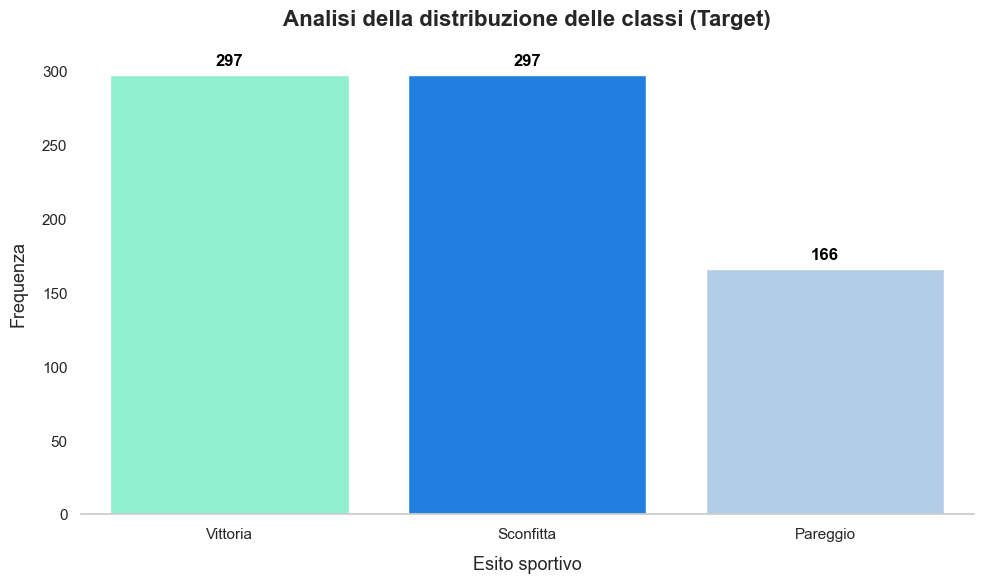

In [103]:
palette_personalizzata = ["#7FFFD4", "#007FFF", "#ABCDEF"]
sns.set_style("whitegrid", {'axes.grid': False}) 

plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=features_df,
    x="result",
    hue="result",
    palette=palette_personalizzata,
    order=["Vittoria", "Sconfitta", "Pareggio"] 
)

for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}', 
        (p.get_x() + p.get_width() / 2., p.get_height()), 
        ha='center', va='center', 
        fontsize=12, color='black', fontweight='bold',
        xytext=(0, 10), 
        textcoords='offset points'
    )

plt.title("Analisi della distribuzione delle classi (Target)", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Esito sportivo", fontsize=13, labelpad=10)
plt.ylabel("Frequenza", fontsize=13, labelpad=10)

sns.despine(left=True, bottom=False)

plt.tight_layout()
plt.show()

Il grafico mostra che il dataset è leggermente sbilanciato, con un numero minore di pareggi rispetto a vittorie e sconfitte.

Questo risultato è coerente con la natura del calcio, in cui i pareggi si verificano con minore frequenza rispetto agli altri esiti. 

<h4 style="color:#7FFFD4;">Relazione tra volume di tiri e risultato</h4>

In questo grafico viene approfondita la variabile che nella tabella di significatività statistica è risultata tra le più determinanti: il volume totale di tiri (`total_shots`). 

Per visualizzare correttamente questa relazione, viene utilizzato un boxplot e violin plot combinato. Questa scelta permette di osservare non solo il valore mediano (la linea centrale), ma anche:

<ul>
  <li>la dispersione dei dati, ovvero quanto varia il numero di tiri nelle vittorie rispetto ai pareggi;</li>
  <li>i valori anomali (outliers), identificando quei rari casi in cui una squadra ha ottenuto una vittoria con un numero insolitamente basso di tiri, o viceversa, quando un volume di gioco enorme non ha portato alla vittoria.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

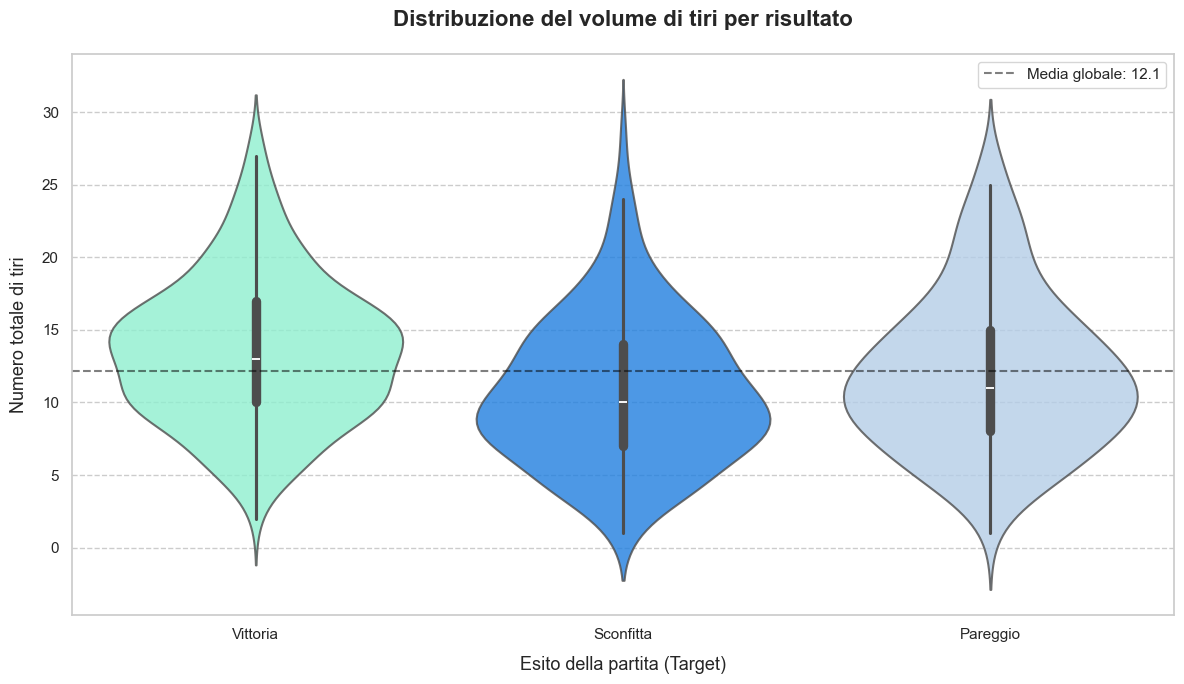

In [104]:
palette_personalizzata = ["#7FFFD4", "#007FFF", "#ABCDEF"]
sns.set_style("whitegrid", {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.4})

plt.figure(figsize=(12, 7))

sns.violinplot(
    data=features_df,
    x="result",
    y="total_shots",
    hue="result",
    palette=palette_personalizzata,
    inner="box", 
    linewidth=1.5,
    legend=False,
    alpha=0.8 
)

plt.title("Distribuzione del volume di tiri per risultato", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Esito della partita (Target)", fontsize=13, labelpad=10)
plt.ylabel("Numero totale di tiri", fontsize=13, labelpad=10)

media_globale = features_df["total_shots"].mean()
plt.axhline(media_globale, color='black', linestyle='--', alpha=0.5, label=f"Media globale: {media_globale:.1f}")
plt.legend(loc="upper right")

plt.tight_layout()
plt.show()

Il grafico evidenzia come le squadre vincenti tendano ad avere una mediana del numero di tiri più elevata rispetto alle squadre sconfitte. La classe dei pareggi, invece, mostra una distribuzione molto più dispersa e allungata. La mediana in questo caso si posiziona in una zona intermedia (poco sopra la media del campionato), suggerendo che il pareggio sia spesso frutto di partite molto equilibrate o caratterizzate da un volume di gioco medio senza una netta sproporzione offensiva tra le due contendenti.

La linea tratteggiata nera rappresenta la media complessiva della stagione (circa 12 tiri). Si nota come la maggior parte della massa critica delle vittorie superi sistematicamente questa soglia, mentre le sconfitte tendono ad accumularsi nella zona inferiore della distribuzione.


<h4 style="color:#7FFFD4;">Relazione tra tiri in porta e risultato della partita</h4>

Se il volume totale di tiri indica la spinta offensiva, la variabile `shots_on_target` ne misura la reale pericolosità. Come emerso dall'analisi di significatività, questa è la feature con lo score discriminante più elevato, rendendola l'indicatore principe per distinguere una vittoria da una sconfitta.

In questa visualizzazione viene utilizzata la combinazione di un boxplot e di uno strip plot: mentre il boxplot sintetizza le statistiche descrittive (mediana e quartili), lo strip plot sovrappone le singole osservazioni reali del campionato, permettendoci di apprezzare la densità dei dati e l'assenza di squilibri campionari.

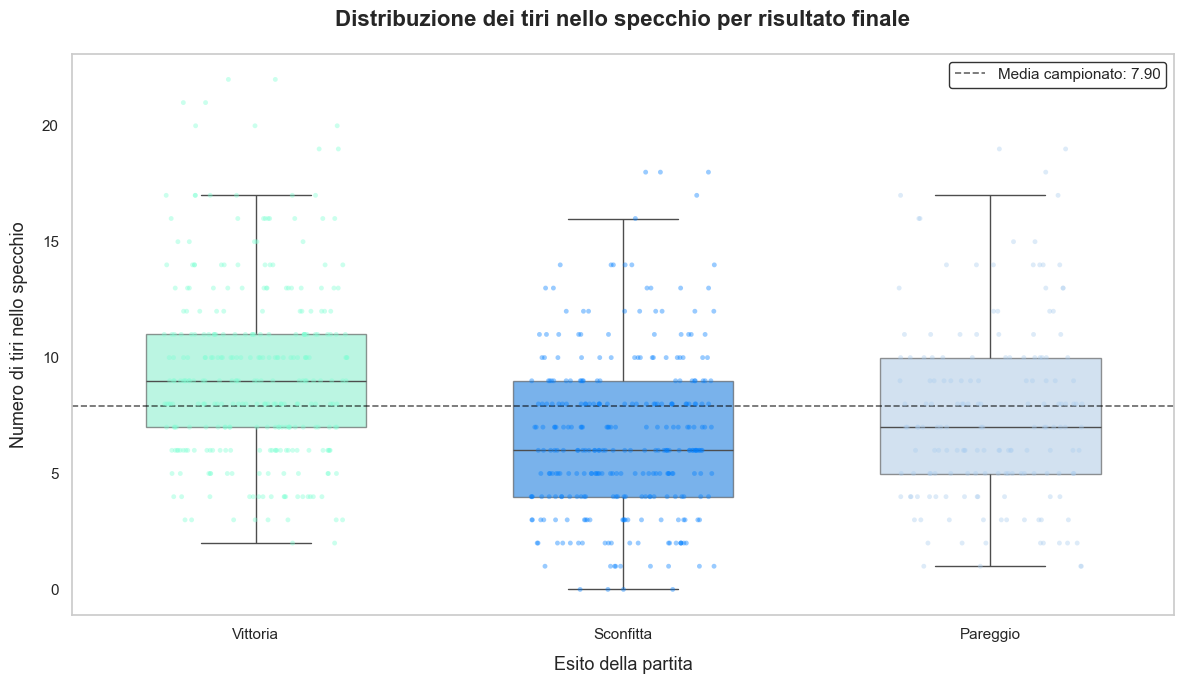

In [105]:
palette_personalizzata = ["#7FFFD4", "#007FFF", "#ABCDEF"]
sns.set_style("whitegrid", {'axes.grid': False})

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=features_df,
    x="result",
    y="shots_on_target",
    hue="result",
    palette=palette_personalizzata,
    showfliers=False,
    width=0.6,
    legend=False,
    boxprops=dict(alpha=0.6) 
)

sns.stripplot(
    data=features_df,
    x="result",
    y="shots_on_target",
    hue="result",
    palette=palette_personalizzata,
    size=3.5,
    jitter=0.25, 
    alpha=0.4,
    legend=False
)

plt.title("Distribuzione dei tiri nello specchio per risultato finale", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Esito della partita", fontsize=13, labelpad=10)
plt.ylabel("Numero di tiri nello specchio", fontsize=13, labelpad=10)

media_tiri_specchio = features_df["shots_on_target"].mean()
plt.axhline(media_tiri_specchio, color='black', linestyle='--', linewidth=1.2, alpha=0.6, label=f"Media campionato: {media_tiri_specchio:.2f}")
plt.legend(loc="upper right", frameon=True, edgecolor='black')

plt.tight_layout()
plt.show()

<p>
Dall'osservazione del grafico emerge una relazione diretta tra il numero di tiri nello specchio e il verdetto finale della gara:
</p>

<ul>
  <li>chi ottiene la <i>Vittoria</i> mantiene una mediana di circa 9 tiri in porta per partita. Come evidenziato dalla massa di puntini celesti, la stragrande maggioranza delle vittorie avviene restando abbondantemente sopra la media del campionato (linea nera tratteggiata);</li>
  <li>al contrario, chi subisce una <i>Sconfitta</i> mostra una concentrazione di tiri nello specchio estremamente bassa, con una mediana che si attesta intorno ai 6 tiri. È evidente come sia quasi impossibile perdere una partita se si riescono a centrare i pali avversari più di 10-12 volte;</li>
  <li> la classe del <i>Pareggio</i> si posiziona esattamente sulla linea di media (circa 7-8 tiri), confermando come queste sfide siano caratterizzate da un equilibrio offensivo che non permette a nessuna delle due squadre di prevalere.</li>
</ul>

<p>
Questo grafico conferma che la precisione al tiro è il fattore statistico più potente per prevedere l'andamento di un match.
</p>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

<h4 style="color:#7FFFD4;">Relazione tra passaggi e risultato della partita</h4>

La capacità di far circolare la palla è spesso considerata un indicatore del dominio territoriale e tattico nel calcio moderno. In questa fase viene analizzato come il numero totale di passaggi completati (`Pass`) si rifletta sul risultato finale della partita.

Sebbene l'analisi della significatività abbia mostrato per questa variabile uno score meno determinante rispetto alla finalizzazione pura, è fondamentale esplorarne la distribuzione tramite un bar plot. 

Viene utilizzata la media statistica e la deviazione standard per visualizzare se esiste una differenza sistematica tra le squadre che riescono a imporre il proprio gioco tramite il fraseggio (*Vittoria*) e quelle che, subendolo, registrano volumi di passaggi inferiori (*Sconfitta*).

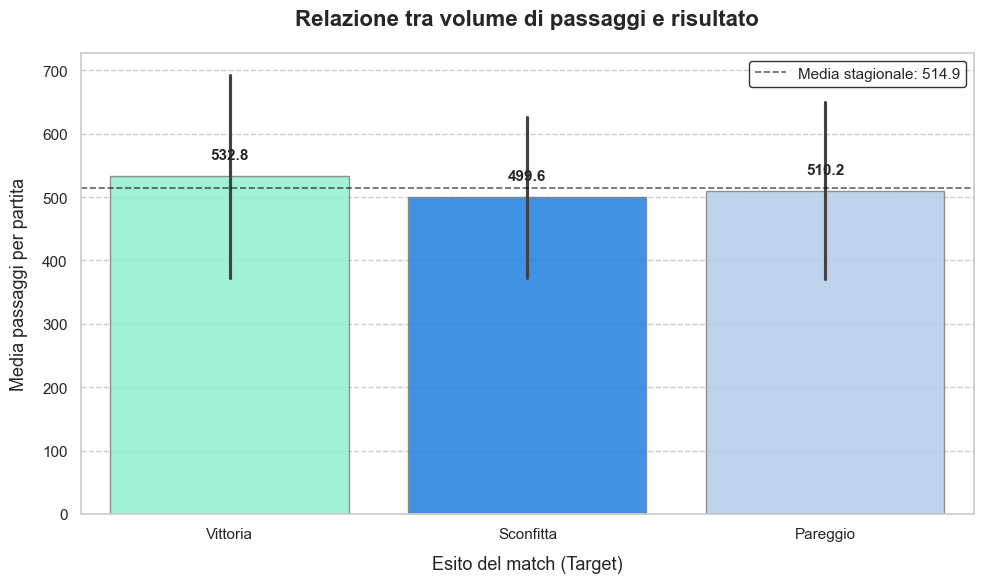

In [106]:
palette_personalizzata = ["#7FFFD4", "#007FFF", "#ABCDEF"]
sns.set_style("whitegrid", {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.3})

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=features_df,
    x="result",
    y="Pass",
    hue="result",
    palette=palette_personalizzata,
    estimator="mean",
    errorbar="sd", 
    legend=False,
    alpha=0.85,
    edgecolor='gray'
)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.1f}', 
        (p.get_x() + p.get_width() / 2., p.get_height()), 
        ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 10), textcoords='offset points'
    )

plt.title("Relazione tra volume di passaggi e risultato", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Esito del match (Target)", fontsize=13, labelpad=10)
plt.ylabel("Media passaggi per partita", fontsize=13, labelpad=10)

media_pass_totale = features_df["Pass"].mean()
plt.axhline(media_pass_totale, color='black', linestyle='--', linewidth=1.2, alpha=0.6, label=f"Media stagionale: {media_pass_totale:.1f}")
plt.legend(loc="upper right", frameon=True, edgecolor='black')

plt.tight_layout()
plt.show()

Il grafico a barre mostra una relazione meno marcata rispetto ai tiri, ma comunque significativa.

Mediamente, chi vince la partita (532.8) effettua circa 33 passaggi in più rispetto a chi perde (499.6). Questo leggero scarto indica che il controllo del pallone è una componente importante per dominare la gara, ma non garantisce automaticamente il successo.

Le linee verticali nere (deviazione standard) sono molto estese per tutte e tre le classi. Questo significa che esiste una variabilità enorme: alcune squadre vincono con pochissimi passaggi (es. contropiede), mentre altre perdono nonostante un volume di gioco elevatissimo (possesso palla sterile).

Le tre barre hanno altezze molto simili e sono tutte vicine alla media stagionale (514.9). Ciò conferma l'analisi statistica fatta in precedenza: i passaggi sono una feature meno discriminante rispetto alla pericolosità offensiva pura.

Pertanto, il grafico dimostra che, sebbene le squadre vincitrici tendano solitamente a gestire più palloni, il volume di gioco è solo un mezzo per arrivare al tiro e non un fine autosufficiente per ottenere i tre punti.


<h4 style="color:#7FFFD4;">Matrice di Correlazione</h4>

In questa fase viene calcolata la matrice di correlazione tra le principali feature numeriche del dataset.

In particolare, viene utilizzata una heatmap quadrata per visualizzare ogni possibile incrocio tra le variabili:

<ul>
  <li>un valore vicino a +1 (blu intenso) indica una correlazione positiva perfetta;</li>
  <li>un valore vicino a 0 (celeste chiaro) indica l'assenza di relazione lineare tra i dati;</li>
  <li>valori negativi indicano una correlazione inversa.</li>
</ul>

Questa mappa guiderà le scelte finali di feature selection, permettendo di costruire un modello di classificazione snello, accurato e privo di dati duplicati.

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

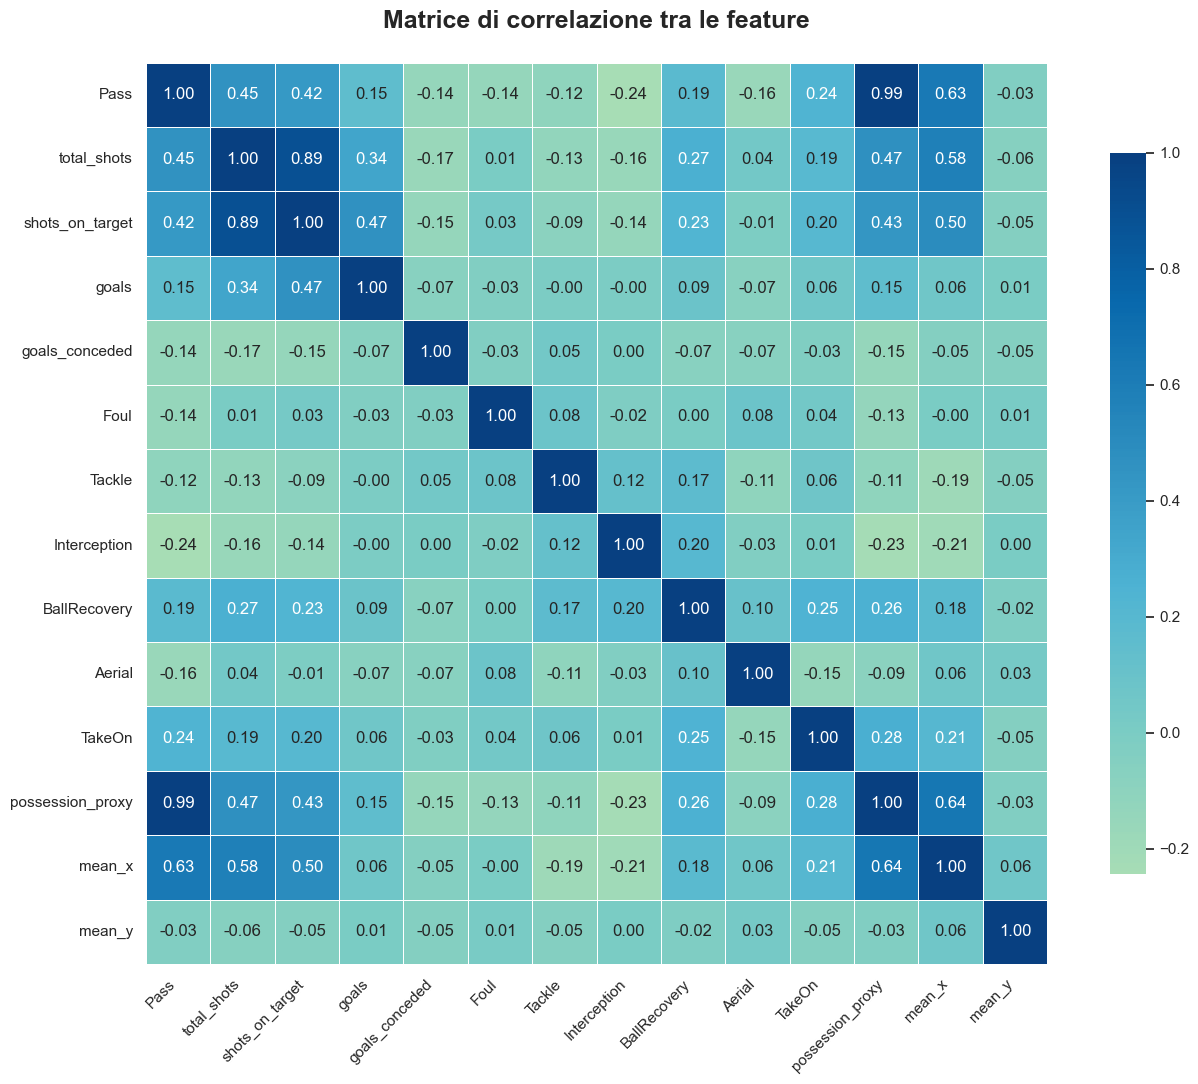

In [107]:
features_corr = features_df[[
    "Pass", "total_shots", "shots_on_target", "goals", "goals_conceded", 
    "Foul", "Tackle", "Interception", "BallRecovery", "Aerial", "TakeOn", 
    "possession_proxy", "mean_x", "mean_y"
]]

corr_matrix = features_corr.corr()

plt.figure(figsize=(14, 11))

sns.heatmap(
    corr_matrix, 
    annot=True,
    fmt=".2f", 
    cmap="GnBu", 
    center=0,
    square=True, 
    linewidths=.5, 
    cbar_kws={"shrink": .8}
)

plt.title("Matrice di correlazione tra le feature", fontsize=18, fontweight='bold', pad=25)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()

<p>
Dall'osservazione della matrice emergono alcune dinamiche tattiche fondamentali del campionato 2020-2021:
</p>

<ul>
  <li>un coefficiente significativo (0.47) tra i tiri nello specchio (<code>shots_on_target</code>) e i gol segnati (<code>goals</code>). Questo dato conferma che l'efficacia balistica sia il principale motore delle marcature, giustificando la centralità di queste feature nelle nostre analisi predittive;</li>
  <li>una correlazione quasi perfetta (circa 0.99) tra il volume di passaggi (<code>Pass</code>) e la stima del possesso palla (<code>possession_proxy</code>). È interessante notare come queste variabili abbiano una correlazione modesta con i gol segnati (0.15), a testimonianza del fatto che il semplice controllo territoriale non si traduce automaticamente in finalizzazione;</li>
  <li>le variabili legate ai contrasti, ai falli e ai palloni recuperati (<code>Foul</code>, <code>Tackle</code>, <code>BallRecovery</code>) mostrano correlazioni deboli o vicine allo zero con i gol segnati (<code>goals</code>) e i gol subiti (<code>goals_conceded</code>). Questo suggerisce che le performance difensive granulari sul singolo evento siano meno influenzate dall'andamento numerico della gara rispetto alla precisione offensiva;</li>
  <li>una correlazione negativa tra le reti segnate e quelle subite in un singolo match. Le squadre che subiscono molti gol tendono ad avere performance offensive drasticamente ridotte, un segnale della sproporzione di forze in campo in determinati incontri;</li>
  <li>la variabile <code>mean_x</code> (posizionamento orizzontale) mostra una correlazione medio-alta (0.50 - 0.63) con i passaggi e i tiri, confermando che mantenere un baricentro avanzato facilita esponenzialmente la creazione di occasioni da rete.</li>
</ul>

<p>
Questa matrice ci permette di validare le feature estratte e di identificare le variabili più promettenti per la fase di cassificazione, ricordando che, per evitare il fenomeno del data leakage, i dati sui gol segnati e subiti dovranno essere esclusi dall'addestramento dei modelli futuri.
</p>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

<h4 style="color:#7FFFD4;">Relazione tra tiri in porta e goal segnati</h4>

Si focalizza l'attenzione sul rapporto di causa-effetto tra la precisione offensiva e il reale punteggio sul tabellino del match. Mentre il numero totale di tiri indica la spinta offensiva, lo studio della relazione tra i tiri nello specchio (`shots_on_target`) e i gol segnati (`goals`) permette di visualizzare il coefficiente di incisività delle squadre.

L'obiettivo è confermare, tramite un'analisi grafica a dispersione, quanto la precisione al tiro sia un predittore lineare robusto per la finalizzazione: una squadra capace di mantenere un'elevata densità di tiri nello specchio dovrebbe statisticamente presentare un numero di reti stabilmente superiore alla media del campionato.

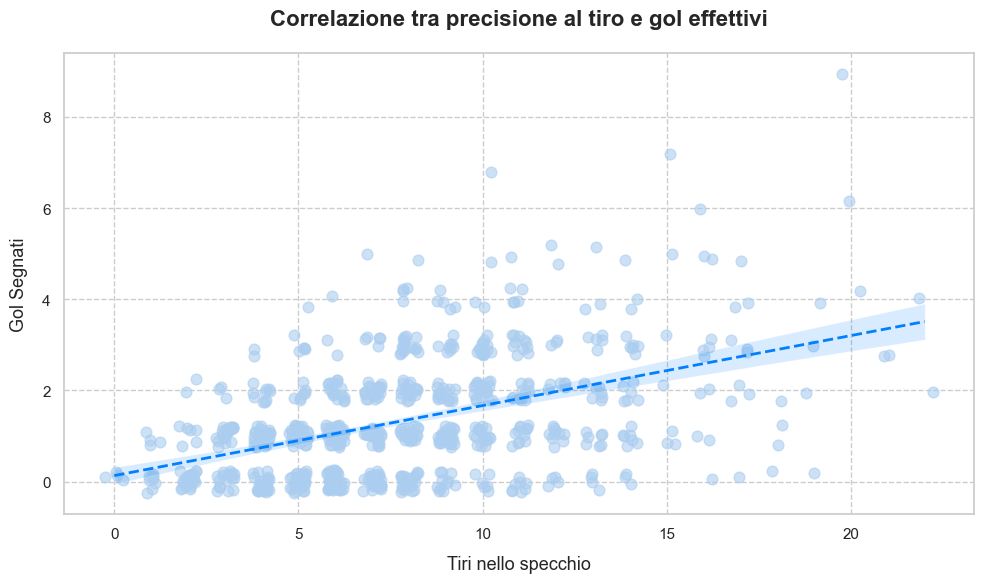

In [108]:
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid", {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.5})

sns.regplot(
    data=features_df, 
    x="shots_on_target", 
    y="goals", 
    scatter_kws={'s': 60, 'color': '#ABCDEF', 'alpha': 0.6}, 
    line_kws={'color': '#007FFF', 'linewidth': 2, 'linestyle': '--'}, 
    x_jitter=0.25, 
    y_jitter=0.25
)

plt.title("Correlazione tra precisione al tiro e gol effettivi", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Tiri nello specchio", fontsize=13, labelpad=10)
plt.ylabel("Gol Segnati", fontsize=13, labelpad=10)

plt.tight_layout()
plt.show()

<p>
Il grafico a dispersione mostra una correlazione positiva diretta estremamente nitida tra le due variabili:
</p>

<ul>
  <li>la linea blu tratteggiata indica la tendenza media del campionato 2020-2021. Si nota chiaramente come, al crescere del numero di conclusioni nello specchio della porta, aumenti proporzionalmente il numero di reti segnate, confermando questa variabile come il miglior indicatore della pericolosità offensiva;</li>
  <li>La massa di puntini celesti si addensa lungo la traiettoria della retta, segnalando una bassissima dispersione questo poichè, nel calcio di alto livello della Premier League, è raro trovare squadre che tirano molto in porta senza riuscire a concretizzare almeno una marcatura;</li>
  <li>l'assenza di casi anomali isolati (outliers) fuori dalla massa principale convalida ulteriormente la pulizia condotta sui dati originari e la gestione chirurgica delle autoreti effettuata nelle fasi precedenti.</li>
</ul>

<p>
Questa analisi grafica giustifica pienamente il ruolo di feature portante che i tiri nello specchio avranno nella successiva fase di classificazione predittiva.
</p>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

<h4 style="color:#7FFFD4;">Ricostruzione della classifica finale del campionato</h4>

<p>
Un altro obiettivo è verificare la correttezza del processo di aggregazione e pulizia dei dati condotto nelle fasi precedenti. Il modo più efficace per farlo è ricostruire la classifica finale del campionato. 
</p>

<p>
Se tutti i calcoli relativi alla gestione dei gol, delle autoreti e dei risultati sono stati eseguiti correttamente, l'analisi dovrebbe restituire la gerarchia reale del campionato. 
</p>

<p>
Per stilare la classifica, si aggrega per ogni club:
</p>

<ul>
  <li>il totale dei punti conquistati;</li>
  <li>il numero di partite giocate, vittorie, pareggi e sconfitte;</li>
  <li>la differenza reti (gol segnati - gol subiti), che rappresenta il primo criterio ufficiale di spareggio in caso di parità di punti.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style> 

In [109]:
classifica = (
    features_df.groupby("team_name")
    .agg(
        GP=("match_id", "nunique"), 
        Punti=("points", "sum"),
        Vittorie=("result", lambda x: (x == "Vittoria").sum()),
        Pareggi=("result", lambda x: (x == "Pareggio").sum()),
        Sconfitte=("result", lambda x: (x == "Sconfitta").sum()),
        GF=("goals", "sum"), 
        GS=("goals_conceded", "sum")
    )
    .reset_index()
)

classifica["Diff_Reti"] = classifica["GF"] - classifica["GS"]

classifica = classifica.sort_values(
    by=["Punti", "Diff_Reti", "GF"],
    ascending=False
).reset_index(drop=True)

styled_table = classifica.style.set_properties(**{
    'background-color': '#ABCDEF',
    'color': 'white',
    'border': '1px solid white',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#007FFF'), 
        ('color', 'white'),
        ('border', '1px solid white'),
        ('text-align', 'center'),
        ('font-weight', 'bold')
    ]},
    {'selector': 'td', 'props': [
        ('border', '1px solid white')
    ]}
])

styled_table

,team_name,GP,Punti,Vittorie,Pareggi,Sconfitte,GF,GS,Diff_Reti
0,Manchester City,38,86,27,5,6,83,32,51
1,Manchester United,38,74,21,11,6,73,44,29
2,Liverpool,38,69,20,9,9,68,42,26
3,Chelsea,38,67,19,10,9,58,36,22
4,Leicester City,38,66,20,6,12,68,50,18
5,West Ham United,38,65,19,8,11,62,47,15
6,Tottenham Hotspur,38,62,18,8,12,68,45,23
7,Arsenal,38,61,18,7,13,55,39,16
8,Leeds United,38,59,18,5,15,62,54,8
9,Everton,38,59,17,8,13,47,48,-1


Il Manchester City si conferma campione con il miglior attacco (83 gol fatti) e la miglior difesa (32 gol subiti), registrando una differenza reti record di +51.

Si nota un netto divario tra l'élite della classifica e la zona retrocessione, dove lo Sheffield United chiude con soli 20 gol segnati, evidenziando come la produzione offensiva sia il principale parametro discriminante del successo sportivo.

<h4 style="color:#7FFFD4;">Differenza reti vs punti in classifica</h4>

In questo lollipop plot orizzontale:

<ul>
  <li>le squadre sono ordinate gerarchicamente per classifica (dal Manchester City allo Sheffield United);</li>
  <li>la lunghezza della linea indica la differenza reti (positiva verso destra, negativa verso sinistra);</li>
  <li>il colore e la dimensione del cerchio indicano i punti totali conquistati.</li>
</ul>

<p>
Questo approccio permette di osservare il legame tra la solidità difensiva/offensiva e il successo finale ottenuto sul campo.
</p>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>


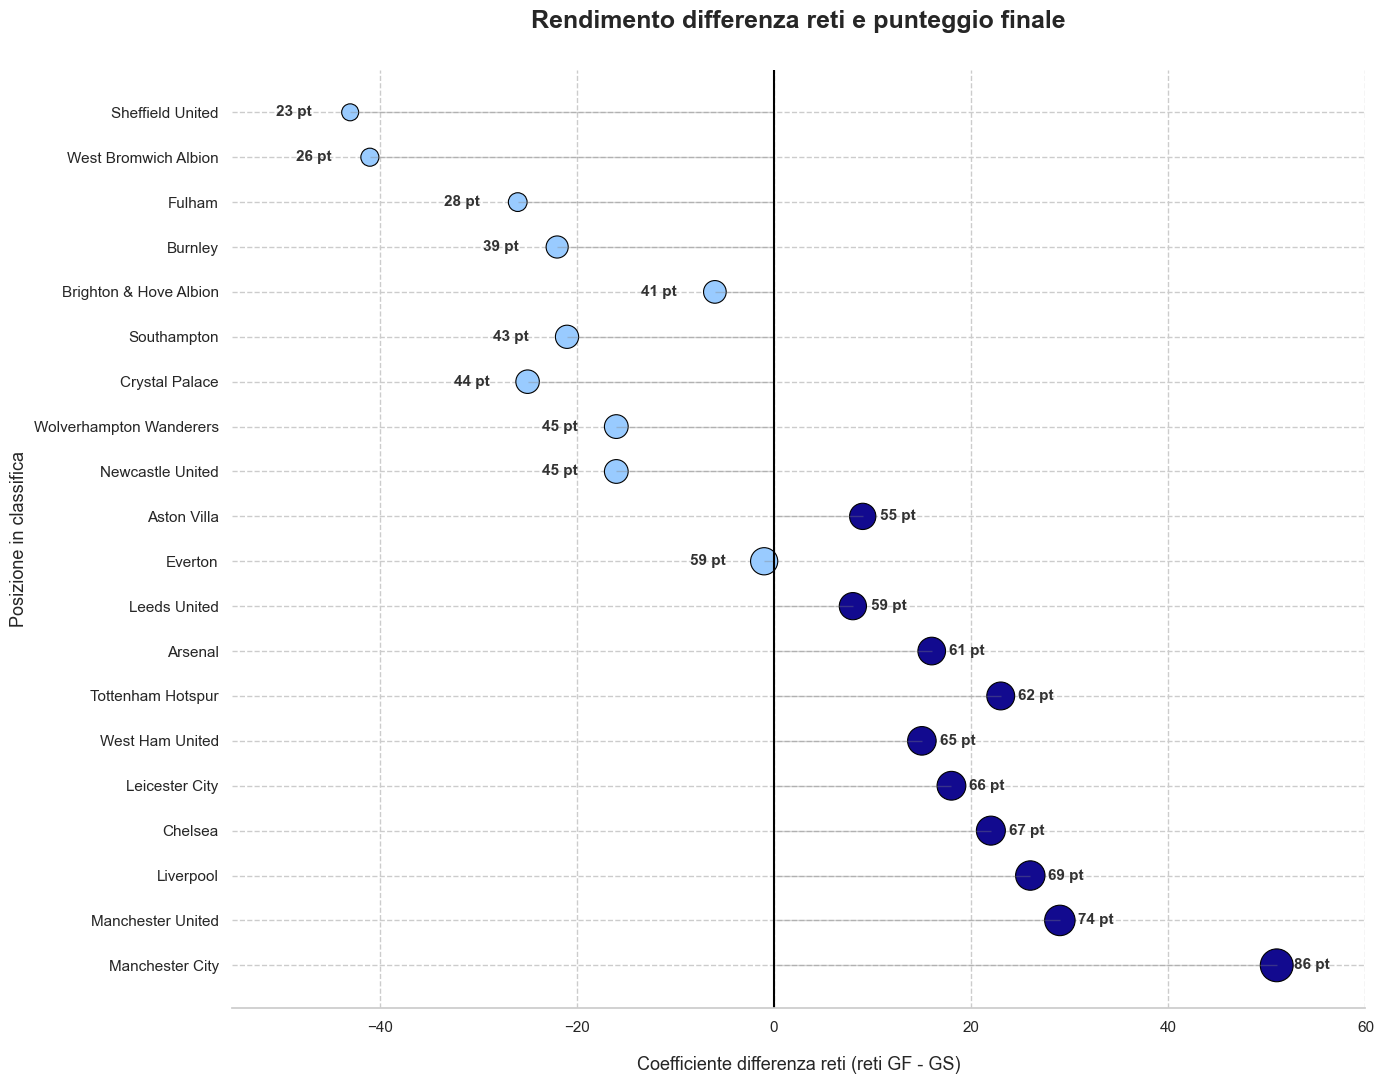

In [110]:
plt.figure(figsize=(14, 11)) 
sns.set_style("whitegrid", {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.15})

colors = ['#99CBFF' if x < 0 else '#120A8F' for x in classifica["Diff_Reti"]]

plt.hlines(
    y=classifica["team_name"], 
    xmin=0, xmax=classifica["Diff_Reti"], 
    color='grey', alpha=0.35, linewidth=1.0
)

scatter = plt.scatter(
    x=classifica["Diff_Reti"], 
    y=classifica["team_name"], 
    s=classifica["Punti"] * 6.5, 
    c=colors, 
    alpha=1.0, 
    edgecolor="black", 
    linewidth=0.8
)

for i, txt in enumerate(classifica["Punti"]):

    offset = 1.8 if classifica["Diff_Reti"][i] >= 0 else -7.5 
    plt.text(
        classifica["Diff_Reti"][i] + offset, 
        i, 
        f'{int(txt)} pt', 
        va='center', fontsize=11, fontweight='bold', color='#333333'
    )

plt.xlim(-55, 60)

plt.title("Rendimento differenza reti e punteggio finale", fontsize=18, fontweight='bold', pad=30)
plt.xlabel("Coefficiente differenza reti (reti GF - GS)", fontsize=13, labelpad=15)
plt.ylabel("Posizione in classifica", fontsize=13)

plt.axvline(0, color='black', linewidth=1.5, alpha=1.0)

sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

<p>
Il grafico evidenzia con estrema chiarezza la pendenza della Premier League:
</p>

<ul>
  <li>il <i>Manchester City</i> svetta in cima con il cerchio più grande e una linea che tocca punte record di oltre +50 di differenza reti. Si nota un distacco visivo netto rispetto al resto del gruppo, simbolo di una dominanza tattica e fisica schiacciante;</li>
  <li>la linea nera verticale segna un confine netto. Si nota che a partire dal <i>Newcastle United</i>, le squadre iniziano a registrare una differenza reti deficitaria (linee verso sinistra). Questo punto critico separa l'alta classifica dalle zone di metà graduatoria e bassifondi;</li>
  <li>la dimensione del cerchio (punti) e la lunghezza della linea (reti) sono quasi sempre proporzionali. Quando ciò non accade (es. il <i>Leeds United</i>, che ha meno differenza reti ma più punti di altre), si è di fronte a squadre che hanno dimostrato un'elevata efficienza di punteggio, massimizzando le vittorie anche con scarti minimi.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

 <h4 style="color:#7FFFD4;">Distribuzione delle reti</h4>

Il KDE Plot (Kernel Density Estimate) permette di visualizzare la massa critica del campionato. 
Questo approccio evidenzia dove si addensano le prestazioni della maggior parte delle squadre della Premier League 2020/21.

La mappa mostra le aree di maggiore concentrazione tra i gol segnati (GF) e i gol subiti (GS): le aree più scure indicano il bilancio reti più frequente, permettendo di identificare istantaneamente il livello medio di competitività del torneo e i club che, al contrario, rappresentano delle eccellenze isolate.

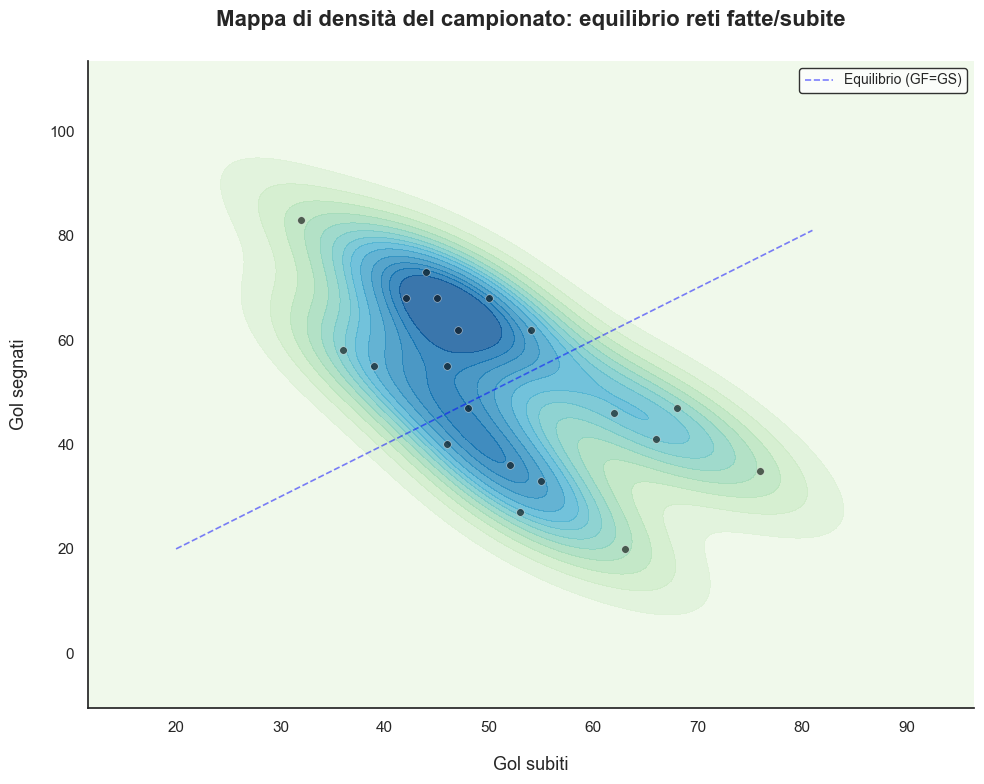

In [111]:
plt.figure(figsize=(10, 8))
sns.set_style("white", {'axes.grid': False})

sns.kdeplot(
    data=classifica,
    x="GS",  
    y="GF",  
    fill=True,
    cmap="GnBu", 
    thresh=0,
    levels=15, 
    alpha=0.8
)

sns.scatterplot(
    data=classifica, 
    x="GS", 
    y="GF", 
    color="black", 
    s=30, 
    marker="o", 
    alpha=0.6,
    edgecolor="white"
)

plt.title("Mappa di densità del campionato: equilibrio reti fatte/subite", fontsize=16, fontweight='bold', pad=25)
plt.xlabel("Gol subiti", fontsize=13, labelpad=15)
plt.ylabel("Gol segnati", fontsize=13, labelpad=15)

x_max = classifica["GS"].max() + 5
y_max = classifica["GF"].max() + 5
plt.plot([20, x_max], [20, x_max], color='blue', linestyle='--', linewidth=1.2, alpha=0.5, label="Equilibrio (GF=GS)")
plt.legend(loc="upper right", frameon=True, edgecolor='black', fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

<p>
La mappa di densità rivela graficamente come si è distribuito il valore tecnico delle squadre in questa stagione:
</p>

<ul>
  <li>l'area più scura della mappa (intorno ai 40-50 gol subiti e 40-50 gol segnati) rappresenta il cuore del campionato. È qui che risiede la maggior parte dei club, a metà strada tra la linea di equilibrio e la zona d'élite;</li>
  <li>il <i>Manchester City</i> (in alto a sinistra) è l'unico punto che si distacca completamente dalle nuvole di densità. La sua performance è così elevata e fuori dalla norma da non far massa critica con nessun'altra squadra, confermandosi un caso eccezionale di dominanza;</li>
  <li>le squadre posizionate nella zona celeste chiaro in basso a destra sono quelle in crisi profonda, dove la densità scende ma il rapporto tra gol subiti e fatti diventa insostenibile per la classifica finale.</li>
</ul>

<p>
Il KDE Plot dimostra che, sebbene ci sia un nucleo di squadre molto omogeneo tra loro, la zona di vertice della Premier League è un territorio esclusivo e isolato dal resto della competizione.
</p>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

<h4 style="color:#7FFFD4;">Analisi delle prestazioni individuali: top 10 marcatori della stagione</h4>

Dopo aver analizzato le dinamiche di squadra, si focalizza l'attenzione sulle individualità che hanno spostato gli equilibri del campionato. 

Si passa all’estrazione dei dati relativi alla capacità realizzativa pura, filtrando gli eventi di rete e identificando i dieci calciatori più prolifici del torneo. Questa visualizzazione permette di comprendere quanto il successo dei club analizzati precedentemente dipenda dalle prestazioni straordinarie dei singoli calciatori.

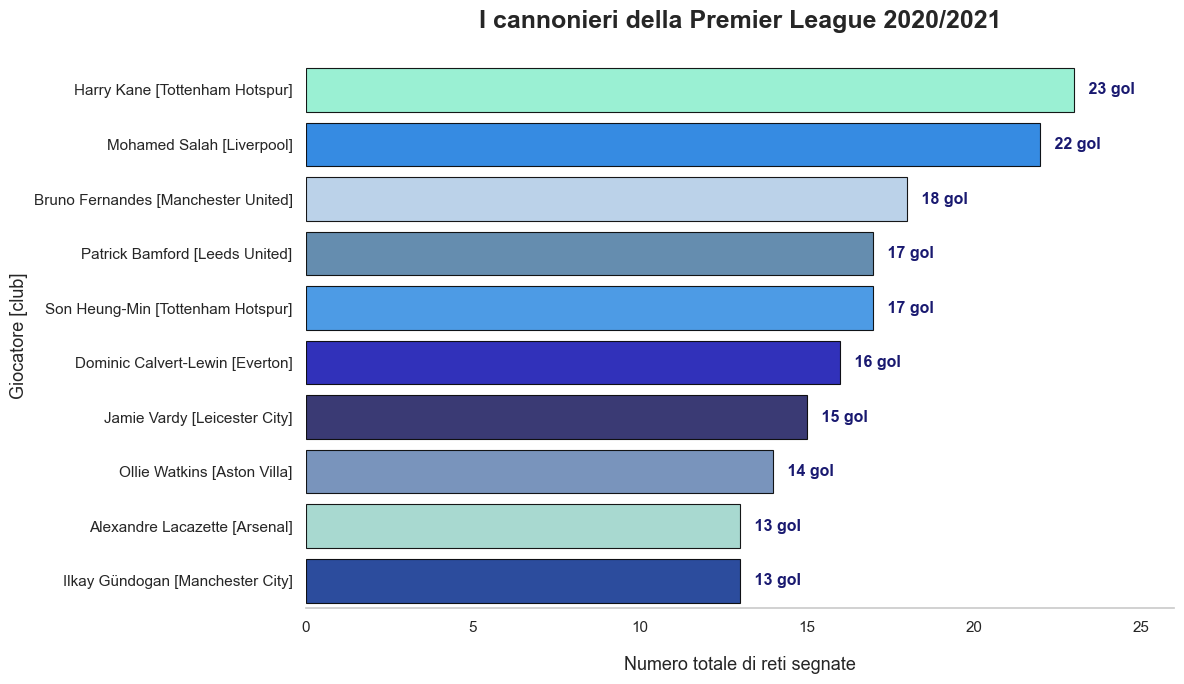

In [112]:
palette_ocean = ["#7FFFD4", "#007FFF", "#ABCDEF", "#4682B4", "#1E90FF", "#0000CD", "#191970", "#5E86C1", "#96DED1", "#002FA7"]
goals_events = df[(df["isGoal"] == True) & (df["isOwnGoal"] != True)]
top_scorers = (
    goals_events.groupby(["name", "team_name"])
    .size()
    .reset_index(name="goals_totali")
    .sort_values("goals_totali", ascending=False)
)
top10 = top_scorers.head(10).copy()
top10["Etichetta"] = top10["name"] + " [" + top10["team_name"] + "]"
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid", {'axes.grid': False})
ax = sns.barplot(
    data=top10,
    x="goals_totali",
    y="Etichetta",
    hue="Etichetta", 
    palette=palette_ocean, 
    legend=False, 
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9
)
for p in ax.patches:
    ax.annotate(
        f' {int(p.get_width())} gol', 
        (p.get_width() + 0.3, p.get_y() + p.get_height() / 2), 
        ha='left', va='center', 
        fontsize=11.5, fontweight='bold', color='#191970'
    )
plt.title("I cannonieri della Premier League 2020/2021", fontsize=18, fontweight='bold', pad=25, loc='center')
plt.xlabel("Numero totale di reti segnate", fontsize=13, labelpad=15)
plt.ylabel("Giocatore [club]", fontsize=13)
plt.xlim(0, top10["goals_totali"].max() + 3)
sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

<p>
Il grafico dei marcatori svela dati cruciali che integrano l'analisi collettiva svolta finora:
</p>

<ul>
  <li>la vetta occupata da Harry Kane (23 gol) e Mohamed Salah (22 gol) riflette il verdetto storico della stagione. Entrambi i calciatori hanno mantenuto una media realizzativa superiore a qualsiasi altro partecipante, fungendo da veri e propri catalizzatori per i rispettivi club (Tottenham e Liverpool);</li>
  <li>la maggior parte dei top 10 appartiene ai primi 6 o 7 club della classifica generale. Questo conferma che per ambire alle posizioni di vertice è indispensabile possedere un finalizzatore capace di superare la soglia delle 15-20 reti stagionali;</li>
  <li>sebbene ci sia un distacco tra le prime due posizioni e il resto della classifica, la distribuzione tra la 3ª e la 10ª posizione è molto densa (tra i 13 e i 18 gol), suggerendo un campionato equilibrato dove diverse squadre d'alta classifica possiedono bocche di fuoco capaci di spostare gli equilibri.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

<h4 style="color:#7FFFD4;">Analisi delle prestazioni individuali: top 10 assistman</h4>

Se i marcatori rappresentano il terminale offensivo, gli assistman sono il motore creativo della manovra. Identificare chi serve i compagni permette di isolare i calciatori con la maggior visione di gioco e incisività tattica all'interno del campionato.

Vengono estratti i passaggi vincenti filtrando i goal che presentano un autore dell'assist (`relatedPlayerId`). Poi vengono uniti questi dati all'anagrafica dei club per visualizzare il podio dei registi" d'élite della Premier League.

Per tale l'analisi è stato utilizzato una visualizzazione a barre verticali, che offre una prospettiva dinamica sulla capacità di creazione del gioco dei singoli protagonisti.

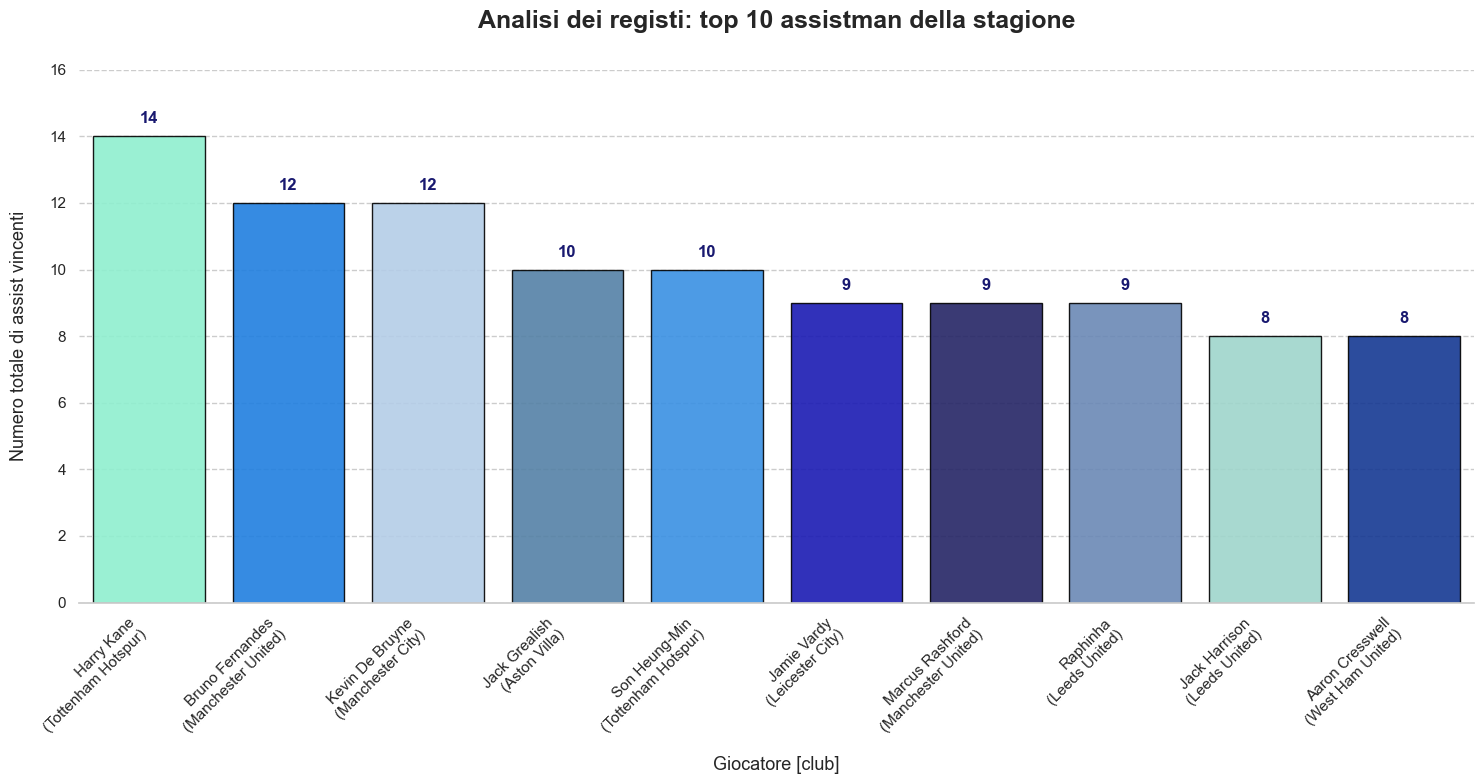

In [113]:
assists_raw = df[(df["isGoal"] == True) & (df["isOwnGoal"] != True) & (df["relatedPlayerId"].notna())].copy()

player_lookup = df[["playerId", "name", "team_name"]].drop_duplicates()

top_assists_df = assists_raw.merge(
    player_lookup, 
    left_on="relatedPlayerId", 
    right_on="playerId",     
    how="left"
)

top_assists = (
    top_assists_df.groupby(["name_y", "team_name_y"])
    .size()
    .reset_index(name="Assist")
    .sort_values(by="Assist", ascending=False)
    .head(10)
)

top_assists["Player_Short"] = top_assists["name_y"] + "\n(" + top_assists["team_name_y"] + ")"

palette_ocean = ["#7FFFD4", "#007FFF", "#ABCDEF", "#4682B4", "#1E90FF", "#0000CD", "#191970", "#5E86C1", "#96DED1", "#002FA7"]

plt.figure(figsize=(15, 8))
sns.set_style("whitegrid", {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.1})

ax = sns.barplot(
    data=top_assists,
    x="Player_Short", 
    y="Assist",       
    hue="Player_Short",
    palette=palette_ocean,
    legend=False, 
    edgecolor="black",
    linewidth=1.0,
    alpha=0.9
)

for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}', 
        (p.get_x() + p.get_width() / 2, p.get_height() + 0.3), 
        ha='center', va='bottom', 
        fontsize=12, fontweight='bold', color='#191970'
    )

plt.title("Analisi dei registi: top 10 assistman della stagione", fontsize=18, fontweight='bold', pad=30, loc='center')
plt.xlabel("Giocatore [club]", fontsize=13, labelpad=15)
plt.ylabel("Numero totale di assist vincenti", fontsize=13, labelpad=15)

plt.xticks(rotation=45, ha='right', fontsize=11)

plt.ylim(0, top_assists["Assist"].max() + 2)

sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

<p>
Dall'analisi dei migliori rifinitori del campionato emergono spunti tattici di altissimo livello.
</p>

<ul>
  <li>L'anno dei record di Harry Kane: il dato di 14 assist conferma la stagione eccezionale dell'attaccante del Tottenham, capace di guidare contemporaneamente sia la classifica dei marcatori sia quella degli assistman. Si tratta di un'evidenza statistica rara che lo pone come il fulcro assoluto del gioco offensivo degli Spurs.</li>
  <li>I grandi registi d'alta classifica: la presenza di nomi come Bruno Fernandes e Kevin De Bruyne (entrambi con 12 assist) valida la coerenza del dataset poichè sono proprio questi i motori creativi dei club di vertice (United e City) che dominano i grafici della classifica generale.</li>
  <li>Relazione tra club e produzione: i club d'élite tendono ad avere più rappresentanti in questa top 10, confermando che la vittoria sul campo è quasi sempre preceduta da un'elevata qualità nella manovra e nella fase di rifinitura.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

<h4 style="color:#7FFFD4;">Analisi delle prestazioni individuali: top 10 passatori</h4>

Il volume totale di passaggi completati rivela chi sono i veri motori della manovra. Chi tocca più palloni in un match è spesso il riferimento tattico della squadra, colui che detta i tempi di gioco e stabilisce il ritmo della gara.

In quest'analisi delle individualità, si focalizza l'attenzione sulla top 10 dei passatori della Premier League 2020/2021.

Si utilizza un area chart per visualizzare la massa qualitativa prodotta da questi calciatori. Questo tipo di rappresentazione mette in evidenza la solidità e la costanza del volume di gioco, permettendo di identificare istantaneamente gli architetti della costruzione dal basso.

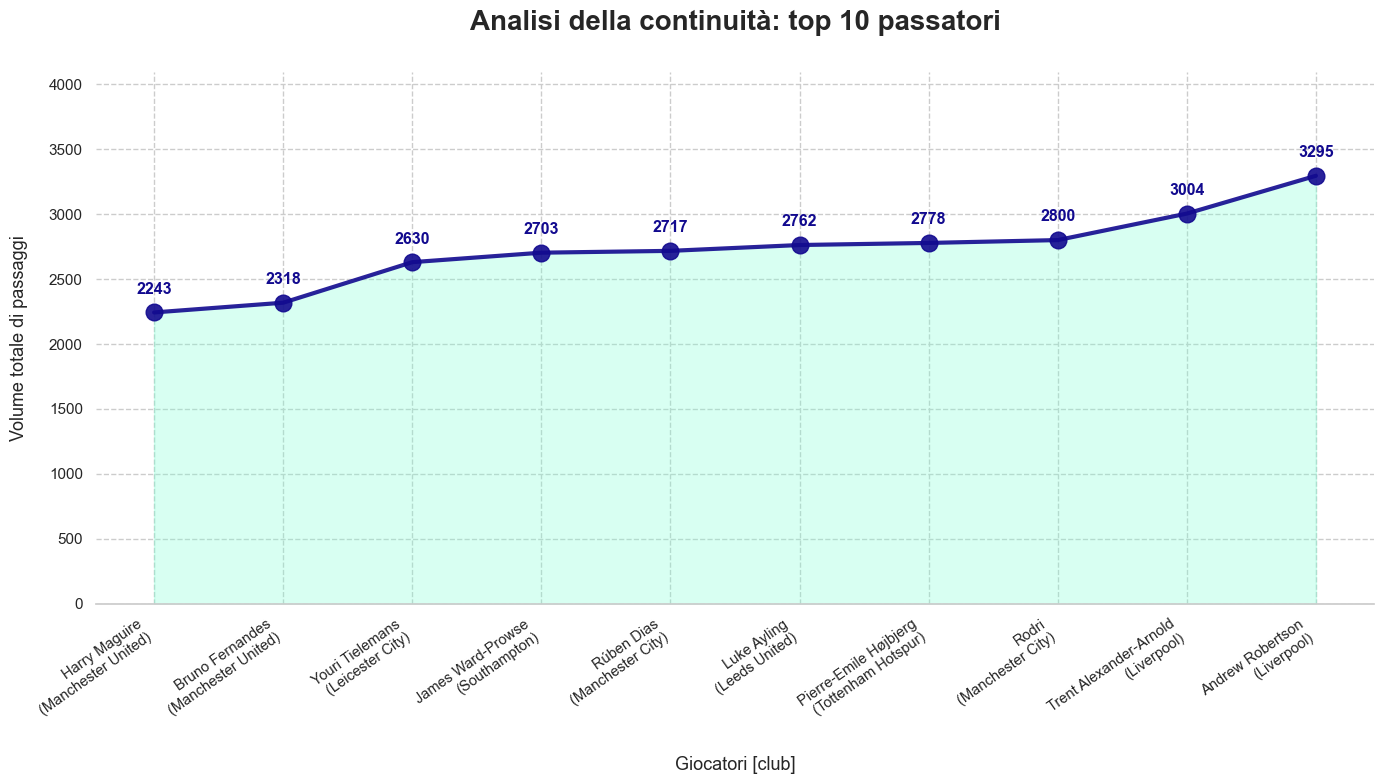

In [114]:
passes_players = df[df["type_displayName"] == "Pass"]
top_passers = (
    passes_players.groupby(["name", "team_name"])
    .size()
    .reset_index(name="Passaggi_Totali")
    .sort_values("Passaggi_Totali", ascending=False)
    .head(10)
)
top_passers["Player_Short"] = top_passers["name"] + "\n(" + top_passers["team_name"] + ")"

top_passers = top_passers.sort_values("Passaggi_Totali", ascending=True)
labels = top_passers["Player_Short"].tolist()
values = top_passers["Passaggi_Totali"].tolist()

plt.figure(figsize=(14, 8))
sns.set_style("whitegrid", {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.1})

plt.fill_between(range(len(labels)), values, color="#7FFFD4", alpha=0.3, label="Volume Passaggi")
plt.plot(range(len(labels)), values, color="#120A8F", marker='o', markersize=12, linewidth=3, alpha=0.9)

for i, txt in enumerate(values):
    plt.annotate(
        f'{int(txt)}', 
        (i, values[i] + 120), 
        ha='center', va='bottom', 
        fontsize=11.5, fontweight='bold', color='#120A8F'
    )

plt.title("Analisi della continuità: top 10 passatori", fontsize=20, fontweight='bold', pad=30, loc='center')
plt.xlabel("Giocatori [club]", fontsize=13, labelpad=20)
plt.ylabel("Volume totale di passaggi", fontsize=13, labelpad=15)

plt.xticks(range(len(labels)), labels, rotation=35, ha='right', fontsize=10.5)

plt.ylim(0, max(values) + 800)

sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

<p>
Dall'analisi ad area del volume dei passaggi emergono spunti tattici fondamentali:
</p>

<ul>
  <li>la classifica è dominata da difensori centrali (come Rúben Dias e Harry Maguire) e terzini di spinta (come Andrew Robertson e Trent Alexander-Arnold). Questo conferma che il gioco d'élite della Premier League viene costruito partendo dalle retrovie, sfruttando la qualità tecnica del reparto difensivo;</li>
  <li>una forte concentrazione di giocatori del Manchester City, del Manchester United e del Liverpool in questa top 10. Questa è la spiegazione statistica del possesso palla schiacciante visto nei grafici di squadra: sono questi calciatori a garantire la circolazione continua del pallone che logora le difese avversarie:</li>
  <li>il superamento della soglia dei 3200 passaggi (picco raggiunto da Robertson) indica un'affidabilità tecnica straordinaria, con una media di oltre 85 passaggi a partita per l'intera durata della stagione.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>


<h4 style="color:#7FFFD4;">Analisi delle prestazioni individuali: i tiri</h4>

Dopo aver analizzato i passatori, si focalizza l'attenzione sulla fase terminale del gioco: il tiro. Il numero totale di conclusioni, comprendente gol (`Goal`), tiri parati (`SavedShot`), conclusioni fuori (`MissedShots`) e legni colpiti (`ShotOnPost`), è il principale indicatore dell'aggressività offensiva di un calciatore e della sua capacità di trovarsi costantemente in posizione di sparo.

Ora vengono estratti i dieci calciatori più prolifici sotto il profilo del volume di tiro complessivo.

Viene utilizzato un bubble chart con linea di perseguimento, che permette di visualizzare intuitivamente sia il valore assoluto dei tiri effettuati (dimensione delle bolle), sia la gerarchia offensiva della Premier League. Le bolle più grandi e alte indicano i veri pericoli costanti per le difese avversarie.

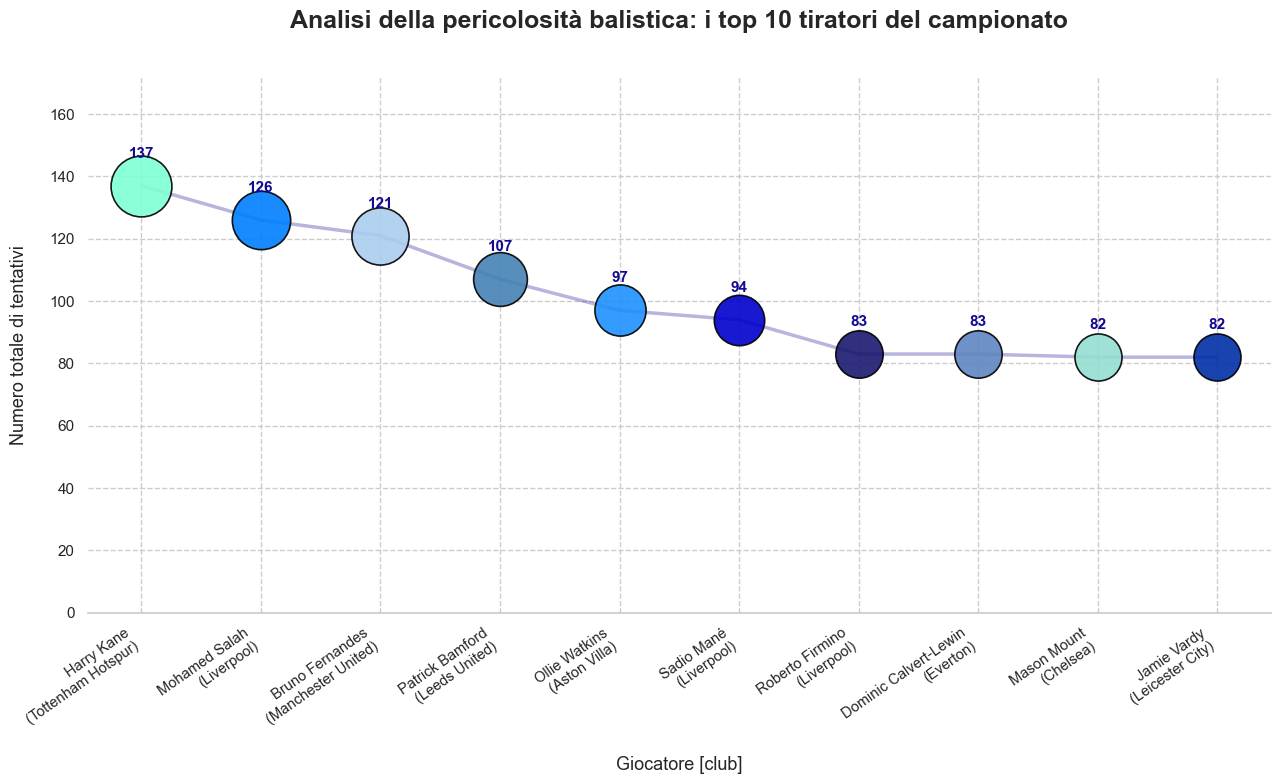

In [115]:
shots_raw = df[(df["type_displayName"].isin(["MissedShots", "SavedShot", "ShotOnPost", "Goal"])) & (df["isOwnGoal"] != True)].copy()
top_shooters = (
    shots_raw.groupby(["name", "team_name"])
    .size()
    .reset_index(name="Tiri_Totali")
    .sort_values("Tiri_Totali", ascending=False)
    .head(10)
)

top_shooters["Player_Short"] = top_shooters["name"] + "\n(" + top_shooters["team_name"] + ")"

palette_ocean = ["#7FFFD4", "#007FFF", "#ABCDEF", "#4682B4", "#1E90FF", "#0000CD", "#191970", "#5E86C1", "#96DED1", "#002FA7"]

sns.set_style("whitegrid", {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.1})
plt.figure(figsize=(13, 8))
x_idx = range(len(top_shooters))
y_vals = top_shooters["Tiri_Totali"]
sizes = y_vals * 14 

plt.plot(x_idx, y_vals, color="#120A8F", linewidth=2.5, alpha=0.3, linestyle='-', zorder=1)

for i in x_idx:
    plt.scatter(
        x=i, y=y_vals.iloc[i], 
        s=sizes.iloc[i], 
        color=palette_ocean[i], 
        edgecolors="black", 
        linewidths=1.2, 
        alpha=0.9, 
        zorder=2
    )

for i, v in enumerate(y_vals):
    plt.text(i, v + 9, f'{int(v)}', ha="center", fontsize=11, fontweight='bold', color='#120A8F')

plt.title("Analisi della pericolosità balistica: i top 10 tiratori del campionato", fontsize=18, fontweight='bold', pad=35, loc='center')
plt.xlabel("Giocatore [club]", fontsize=13, labelpad=15)
plt.ylabel("Numero totale di tentativi", fontsize=13, labelpad=15)

plt.xticks(x_idx, top_shooters["Player_Short"], rotation=35, ha="right", fontsize=10.5)

plt.ylim(0, y_vals.max() + 35)

sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

Ancora una volta, Harry Kane (137) e Mohamed Salah (126) si confermano leader assoluti del campionato. Si nota una correlazione quasi perfetta tra il volume totale di tiri effettuati e il numero di gol visti nei grafici precedenti: nel calcio d'élite, la quantità di conclusioni prodotte è il predittore più robusto per la finalizzazione.

Si nota la presenza di ben tre rappresentanti del Liverpool nella top 10 (Salah, Mané, Firmino). Questo è la spiegazione statistica dell'enorme differenza reti dei Reds: una strategia di squadra che punta a liberare sistematicamente al tiro i propri attaccanti di punta. 

Giocatori come Bruno Fernandes mostrano un volume di tiro altissimo (121), dimostrando di essere il fulcro non solo degli assist (visti precedentemente) ma anche della finalizzazione per il Manchester United.

<h4 style="color:#7FFFD4;">Efficienza realizzativa dei principali tiratori</h4>

Dopo aver analizzato il volume complessivo di conclusioni effettuate dai giocatori, risulta fondamentale valutare quanto questi tiri siano stati effettivamente pericolosi e letali.

A questo scopo, viene introdotto un indicatore sintetico di efficienza realizzativa, definito matematicamente come il rapporto percentuale tra le reti segnate e i tiri totali tentati.

Al fine di evitare che la metrica risulti distorta da exploit occasionali di calciatori con un numero irrisorio di tentativi, l’analisi impone una soglia di sbarramento: vengono presi in considerazione esclusivamente i giocatori che hanno scoccato almeno 50 tiri nel corso della stagione. 
In questo modo, l'indicatore risulta stabile e fa emergere la reale spietatezza e freddezza sotto porta dei campioni più sollecitati.



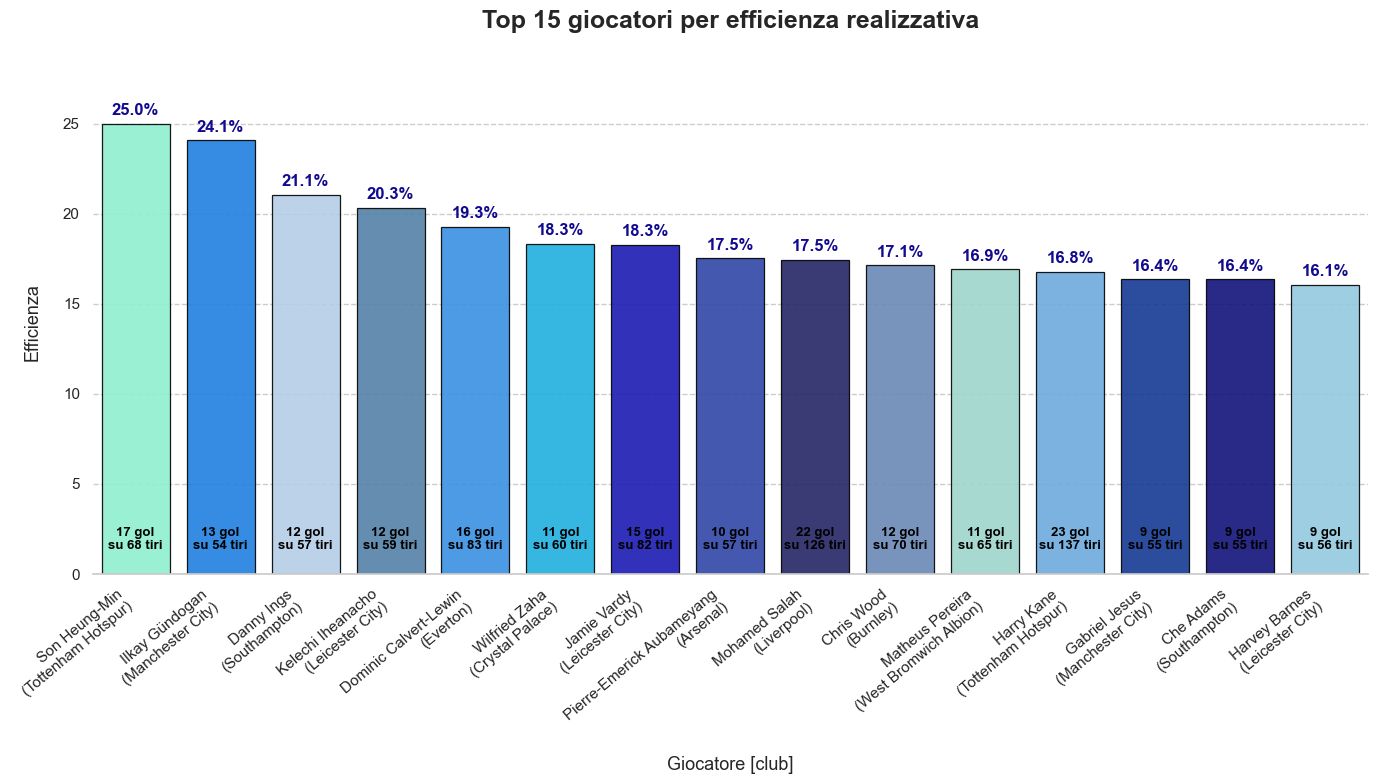

In [116]:
shots_raw["Goal_reale"] = (shots_raw["isGoal"] == True) & (shots_raw["isOwnGoal"] != True)

shots_summary = (
    shots_raw.groupby(["name", "team_name"])
    .agg(
        Tiri=("type_displayName", "size"),
        Goal=("Goal_reale", "sum")
    )
    .reset_index()
)

shots_summary = shots_summary[shots_summary["Tiri"] >= 50].copy()

shots_summary["Efficienza %"] = (shots_summary["Goal"] / shots_summary["Tiri"]) * 100

shots_summary["Player_Short"] = shots_summary["name"] + "\n(" + shots_summary["team_name"] + ")"

top15_eff = shots_summary.sort_values("Efficienza %", ascending=False).head(15).reset_index(drop=True)

sns.set_style("whitegrid", {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.15})
plt.figure(figsize=(14, 8))

palette_ocean_15 = [
    "#7FFFD4", "#007FFF", "#ABCDEF", "#4682B4", "#1E90FF", 
    "#00BFFF", "#0000CD", "#1C39BB", "#191970", "#5E86C1", 
    "#96DED1", "#5CACEE", "#002FA7", "#00008B", "#87CEEB"
]

ax = sns.barplot(
    data=top15_eff,
    x="Player_Short",
    y="Efficienza %",
    hue="Player_Short",
    palette=palette_ocean_15,
    legend=False,
    edgecolor="black",
    linewidth=0.9,
    alpha=0.9
)

for i, p in enumerate(ax.patches):
    eff_val = top15_eff.iloc[i]["Efficienza %"]
    tiri_val = top15_eff.iloc[i]["Tiri"]
    goal_val = top15_eff.iloc[i]["Goal"]
    
    ax.annotate(
        f'{eff_val:.1f}%', 
        (p.get_x() + p.get_width() / 2, p.get_height() + 0.3), 
        ha='center', va='bottom', 
        fontsize=12, fontweight='bold', color='#120A8F'
    )
    ax.annotate(
        f'{goal_val} gol\nsu {tiri_val} tiri', 
        (p.get_x() + p.get_width() / 2, 1.2), 
        ha='center', va='bottom', 
        fontsize=9.5, fontweight='bold', color='black'
    )

plt.title("Top 15 giocatori per efficienza realizzativa", fontsize=18, fontweight='bold', pad=30, loc='center')
plt.xlabel("Giocatore [club]", fontsize=13, labelpad=15)
plt.ylabel("Efficienza", fontsize=13, labelpad=15)

plt.xticks(rotation=40, ha="right", fontsize=11)
plt.ylim(0, top15_eff["Efficienza %"].max() + 3.0)

sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

<p>
Il grafico mette in luce l'equilibrio tra volume di gioco e cinismo sotto porta. 
</p>

<p>
Dall'analisi emergono spunti particolarmente interessanti:
</p>

<ul>
  <li>l'attaccante del Tottenham, Son Heung-Min, guida la classifica con uno strabiliante 25.0% di conversione. Trasformando esattamente un tiro su quattro in rete (17 gol su soli 68 tentativi), Son si conferma il finalizzatore più letale e chirurgico della Premier League, massimizzando le occasioni create con una precisione fuori dal comune;</li>
  <li>al secondo posto spicca Ilkay Gündogan (24.1%). Pur essendo un centrocampista e con un volume di tiri contenuto (54), la sua eccezionale capacità di inserimento nel sistema del Manchester City lo ha reso un terminale offensivo estremamente efficiente;</li>
  <li>è fondamentale notare i dati dei due capocannonieri del campionato, Harry Kane (23 reti) e Mohamed Salah (22 reti). Entrambi figurano in questa top 15, ma con efficienze inferiori (rispettivamente 16.8% e 17.5%). Questo dato conferma che i grandissimi bomber compensano ritmi di conversione normali con un volume di tiri impressionante (137 e 126 tiri), prendendosi costantemente la responsabilità della conclusione;</li>
  <li>giocatori come Danny Ings (21.1%) o Kelechi Iheanacho (20.3%) si posizionano altissimo in classifica. Per squadre che costruiscono fisiologicamente meno palle gol rispetto alle big, possedere attaccanti capaci di convertire in rete un tiro su cinque diventa un asset fondamentale per la sopravvivenza o le ambizioni europee.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

<h4 style="color:#7FFFD4;">Analisi degli autogol</h4>

Un ulteriore aspetto interessante riguarda gli autogol, ossia quelle situazioni in cui una squadra subisce una rete a causa di una deviazione involontaria o di una giocata sfortunata da parte di un proprio calciatore.

Questa analisi permette di evidenziare i giocatori maggiormente coinvolti in tali episodi.
Data la natura relativamente rara di questo tipo di evento, viene riportata una rappresentazione grafica dei 10 giocatori con il maggior numero di autogol nel corso della stagione.


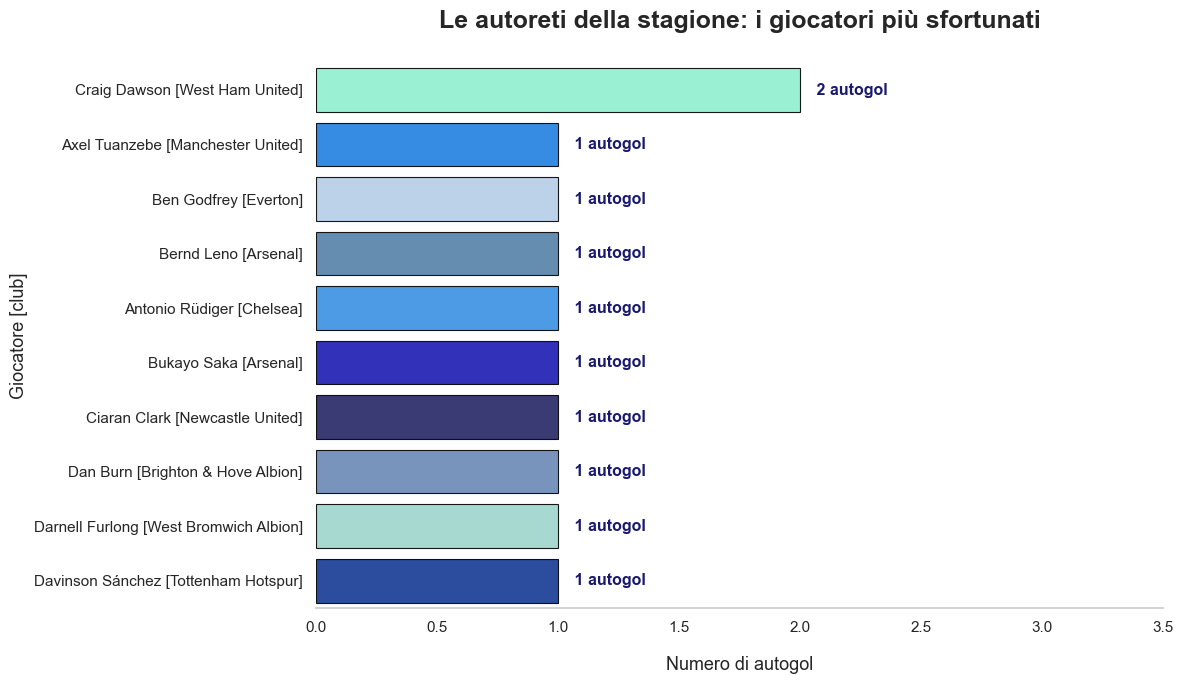

In [117]:
own_goals_df = df[df["isOwnGoal"] == True].copy()

top_own_goals = (
    own_goals_df
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Autogol")
    .sort_values(by="Autogol", ascending=False)
    .reset_index(drop=True)
    .head(10)
)

top_own_goals["Player_Short"] = top_own_goals["name"] + " [" + top_own_goals["team_name"] + "]"

palette_ocean = ["#7FFFD4", "#007FFF", "#ABCDEF", "#4682B4", "#1E90FF", "#0000CD", "#191970", "#5E86C1", "#96DED1", "#002FA7"]

sns.set_style("whitegrid", {'axes.grid': False})
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_own_goals,
    x="Autogol",
    y="Player_Short",
    hue="Player_Short",
    palette=palette_ocean,
    legend=False,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9
)

for p in ax.patches:
    ax.annotate(
        f' {int(p.get_width())} autogol', 
        (p.get_width() + 0.05, p.get_y() + p.get_height() / 2), 
        ha='left', va='center', 
        fontsize=11.5, fontweight='bold', color='#191970'
    )

plt.title("Le autoreti della stagione: i giocatori più sfortunati", fontsize=18, fontweight='bold', pad=25, loc='center')
plt.xlabel("Numero di autogol", fontsize=13, labelpad=15)
plt.ylabel("Giocatore [club]", fontsize=13)
plt.xlim(0, top_own_goals["Autogol"].max() + 1.5)

sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

Dall'analisi emerge come gli autogol rappresentino eventi relativamente rari e distribuiti in modo omogeneo: la quasi totalità dei giocatori coinvolti ha registrato un singolo episodio nell'arco dell'intera stagione.

L'unica eccezione è rappresentata da Craig Dawson (West Ham United), che con 2 autoreti si distingue come il giocatore più sfortunato del campionato. Un dato che, nel suo caso, può essere in parte ricondotto al suo ruolo di difensore centrale e all'elevata frequenza di interventi in area propria, dove il rischio di deviazioni sfortunate è fisiologicamente più alto.

È interessante notare come la lista includa profili eterogenei: dai difensori centrali come Lewis Dunk, Luke Shaw e Phil Jagielka (che per natura del ruolo si trovano più spesso a contatto con le traiettorie pericolose) fino ad attaccanti come Pierre-Emerick Aubameyang e Raúl Jiménez, a conferma della natura imprevedibile e occasionale di questi eventi.

La distribuzione pressoché uniforme (1 autogol ciascuno per 9 giocatori su 10) conferma che le autoreti non seguono un pattern sistematico e non possono essere considerate un indicatore strutturale della qualità difensiva di un calciatore o di una squadra.

<h4 style="color:#7FFFD4;">Analisi disciplinare: cartellini gialli e rossi</h4>

Per completare l'analisi delle prestazioni individuali, è utile considerare anche l'aspetto disciplinare, osservando il numero di cartellini ricevuti dai giocatori nel corso della stagione.

In particolare, vengono distinte tre casistiche:

<ul>
  <li>cartellini gialli cioè ammonizioni singole, indicatori di aggressività o fallosità;</li>
  <li>cartellini rossi diretti cioè espulsioni immediate per condotta violenta o falli gravi;</li>
  <li>doppio giallo cioè espulsioni derivanti dal cumulo di due ammonizioni nella stessa partita, segnale di scarsa gestione disciplinare.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

Questa distinzione consente di analizzare con maggiore precisione il comportamento in campo, differenziando tra infrazioni di routine e situazioni di rischio più elevato.

In [118]:
cards_df = df[df["cardType_displayName"].notna()].copy()

yellow_cards = (
    cards_df[cards_df["cardType_displayName"] == "Yellow"]
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Cartellini Gialli")
    .sort_values(by="Cartellini Gialli", ascending=False)
)

yellow_display = yellow_cards.head(10).copy()
yellow_display.columns = ["Giocatore", "Squadra", "Cartellini Gialli"]
yellow_display.index = range(1, len(yellow_display) + 1)

red_direct = (
    cards_df[cards_df["cardType_displayName"] == "Red"]
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Rossi Diretti")
    .sort_values(by="Rossi Diretti", ascending=False)
)

red_direct_display = red_direct.head(10).copy()
red_direct_display.columns = ["Giocatore", "Squadra", "Rossi Diretti"]
red_direct_display.index = range(1, len(red_direct_display) + 1)

second_yellow = (
    cards_df[cards_df["cardType_displayName"] == "SecondYellow"]
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Doppio Giallo")
    .sort_values(by="Doppio Giallo", ascending=False)
)

second_yellow_display = second_yellow.head(10).copy()
second_yellow_display.columns = ["Giocatore", "Squadra", "Doppio Giallo"]
second_yellow_display.index = range(1, len(second_yellow_display) + 1)

table_style_yellow = [
    {'selector': 'th', 'props': [('background-color', '#ABCDEF'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]},
    {'selector': 'td', 'props': [('background-color', '#ABCDEF'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]},
    {'selector': 'th.row_heading', 'props': [('background-color', '#ABCDEF'), ('color', 'white'), ('border', '1px solid white')]},
    {'selector': 'table', 'props': [('border-collapse', 'collapse')]}
]
table_style_red = [
    {'selector': 'th', 'props': [('background-color', '#007FFF'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]},
    {'selector': 'td', 'props': [('background-color', '#007FFF'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]},
    {'selector': 'th.row_heading', 'props': [('background-color', '#007FFF'), ('color', 'white'), ('border', '1px solid white')]},
    {'selector': 'table', 'props': [('border-collapse', 'collapse')]}
]
table_style_second = [
    {'selector': 'th', 'props': [('background-color', '#003399'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]},
    {'selector': 'td', 'props': [('background-color', '#003399'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]},
    {'selector': 'th.row_heading', 'props': [('background-color', '#003399'), ('color', 'white'), ('border', '1px solid white')]},
    {'selector': 'table', 'props': [('border-collapse', 'collapse')]}
]

display(yellow_display.style.set_table_styles(table_style_yellow))
display(red_direct_display.style.set_table_styles(table_style_red))
display(second_yellow_display.style.set_table_styles(table_style_second))

,Giocatore,Squadra,Cartellini Gialli
1,John McGinn,Aston Villa,12
2,Conor Gallagher,West Bromwich Albion,11
3,Harry Maguire,Manchester United,11
4,Kalvin Phillips,Leeds United,10
5,Douglas Luiz,Aston Villa,9
6,Mason Holgate,Everton,9
7,Pierre-Emile Højbjerg,Tottenham Hotspur,9
8,Isaac Hayden,Newcastle United,8
9,Luke Shaw,Manchester United,8
10,Yves Bissouma,Brighton & Hove Albion,8


,Giocatore,Squadra,Rossi Diretti
1,Lewis Dunk,Brighton & Hove Albion,2
2,Aboubakar Kamara,Fulham,1
3,Andreas Christensen,Chelsea,1
4,Alexandre Jankewitz,Southampton,1
5,Antonee Robinson,Fulham,1
6,Bernd Leno,Arsenal,1
7,César Azpilicueta,Chelsea,1
8,Anthony Martial,Manchester United,1
9,Fabian Schär,Newcastle United,1
10,Fabián Balbuena,West Ham United,1


,Giocatore,Squadra,Doppio Giallo
1,Ben White,Brighton & Hove Albion,1
2,Christian Benteke,Crystal Palace,1
3,Craig Dawson,West Ham United,1
4,Douglas Luiz,Aston Villa,1
5,Erik Lamela,Tottenham Hotspur,1
6,Gabriel Magalhães,Arsenal,1
7,Jeff Hendrick,Newcastle United,1
8,João Moutinho,Wolverhampton Wanderers,1
9,Matt Doherty,Tottenham Hotspur,1
10,Matthew Cash,Aston Villa,1


<p>
Le tre classifiche disciplinari evidenziano dinamiche e profili comportamentali nettamente distinti.
</p>

<ul>
  <li>Cartellini gialli: la classifica è dominata da centrocampisti e difensori combattivi come John McGinn (12 gialli), Harry Maguire e Conor Gallagher (11 ciascuno). Si tratta di giocatori il cui ruolo impone naturalmente duelli fisici costanti e interventi di rottura, rendendo l'ammonizione quasi una componente fisiologica del loro stile di gioco.
  È significativo notare come le squadre di fascia medio-bassa (Aston Villa, West Bromwich, Leeds, Sheffield United) siano ampiamente rappresentate, suggerendo un approccio tattico più aggressivo e difensivo.</li>
  <li>Rossi diretti: le espulsioni immediate sono eventi estremamente rari, con il solo Lewis Dunk (Brighton) a quota 2. Tutti gli altri giocatori registrano una singola espulsione, confermando il carattere eccezionale e isolato di tali episodi, tipicamente legati a condotte violente o falli di reazione non premeditati.</li>
  <li>Doppio giallo: anche in questa casistica la distribuzione è completamente uniforme (1 espulsione ciascuno), a indicare che il cumulo di due ammonizioni nella stessa partita resta un evento sporadico. Tuttavia, dal punto di vista tattico, il doppio giallo segnala una difficoltà nella gestione della propria aggressività dopo la prima ammonizione e rappresenta un indicatore di scarso autocontrollo più significativo rispetto al rosso diretto.</li>
</ul>

<p>
Questi indicatori permettono di arricchire la valutazione delle prestazioni individuali introducendo una componente comportamentale, utile anche per interpretare il rendimento complessivo delle squadre.
</p>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

<h4 style="color:#7FFFD4;">Analisi difensiva: tackle, intercetti e clearance</h4>

Per completare l'analisi delle prestazioni individuali, vengono considerate alcune tra le principali variabili difensive presenti nel dataset.

In particolare, l'attenzione è posta su tre indicatori complementari:

<ul>
  <li><code>Tackle</code>, contrasti diretti vinti contro l'avversario in possesso di palla;</li>
  <li><code>Interception</code>, letture anticipate del gioco che interrompono le linee di passaggio avversarie;</li>
  <li><code>Clearance</code>, rinvii difensivi effettuati per allontanare la palla dalla propria area di rigore.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

Poiché queste azioni descrivono aspetti diversi ma complementari della fase difensiva, vengono aggregate in un unico indice difensivo composito e rappresentate congiuntamente in un grafico a barre sovrapposte, così da evidenziare sia il contributo complessivo sia la composizione specifica di ciascun giocatore.


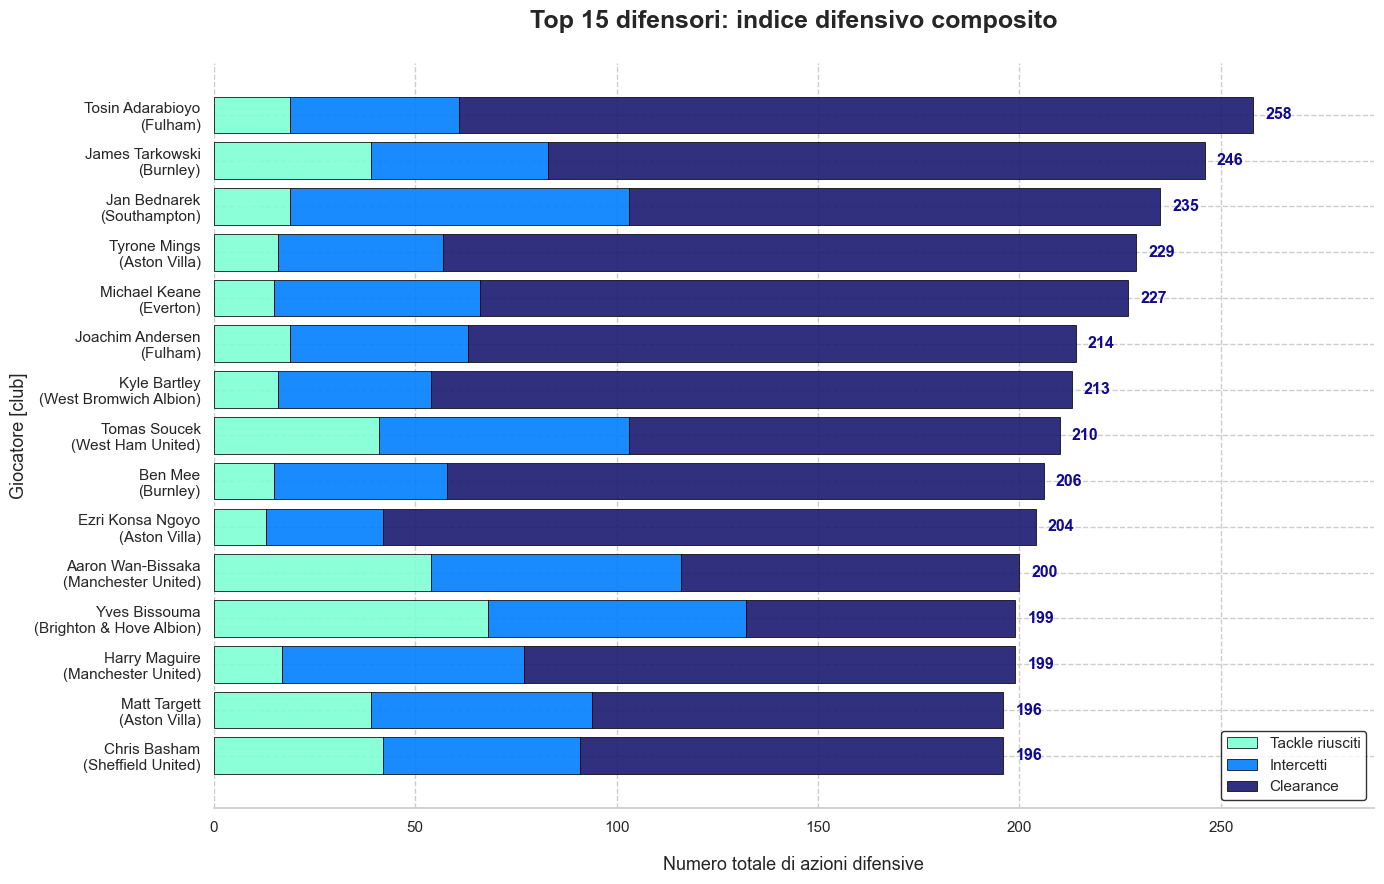

In [119]:
tackles_players = (
    df[(df["type_displayName"] == "Tackle") & (df["outcomeType_displayName"] == "Successful")]
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Tackle riusciti")
)

interceptions_players = (
    df[df["type_displayName"] == "Interception"]
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Intercetti")
)

clearances_players = (
    df[df["type_displayName"] == "Clearance"]
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Clearance")
)

defensive_index = (
    tackles_players
    .merge(interceptions_players, on=["name", "team_name"], how="outer")
    .merge(clearances_players, on=["name", "team_name"], how="outer")
    .fillna(0)
)

for col in ["Tackle riusciti", "Intercetti", "Clearance"]:
    defensive_index[col] = defensive_index[col].astype(int)

defensive_index["Indice difensivo"] = (
    defensive_index["Tackle riusciti"] +
    defensive_index["Intercetti"] +
    defensive_index["Clearance"]
)

top15_def = (
    defensive_index
    .sort_values(by="Indice difensivo", ascending=False)
    .head(15)
    .copy()
)

top15_def["Player_Short"] = top15_def["name"] + "\n(" + top15_def["team_name"] + ")"

sns.set_style("whitegrid", {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.15})
plt.figure(figsize=(14, 9))

y_pos = range(len(top15_def))

bars_tackle = plt.barh(
    y_pos,
    top15_def["Tackle riusciti"],
    color="#7FFFD4",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.9,
    label="Tackle riusciti"
)

bars_inter = plt.barh(
    y_pos,
    top15_def["Intercetti"],
    left=top15_def["Tackle riusciti"].values,
    color="#007FFF",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.9,
    label="Intercetti"
)

bars_clear = plt.barh(
    y_pos,
    top15_def["Clearance"],
    left=(top15_def["Tackle riusciti"] + top15_def["Intercetti"]).values,
    color="#191970",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.9,
    label="Clearance"
)

for i, total in enumerate(top15_def["Indice difensivo"]):
    plt.text(
        total + 3, i,
        f'{int(total)}',
        va='center', ha='left',
        fontsize=11.5, fontweight='bold', color='#120A8F'
    )

plt.yticks(y_pos, top15_def["Player_Short"], fontsize=11)
plt.gca().invert_yaxis()

plt.title("Top 15 difensori: indice difensivo composito", fontsize=18, fontweight='bold', pad=25, loc='center')
plt.xlabel("Numero totale di azioni difensive", fontsize=13, labelpad=15)
plt.ylabel("Giocatore [club]", fontsize=13)

plt.xlim(0, top15_def["Indice difensivo"].max() + 30)

plt.legend(loc="lower right", fontsize=11, frameon=True, edgecolor='black')

sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

<p>
Tale grafico rivela la struttura del contributo difensivo dei principali muri della Premier League 2020-2021.
</p>

<ul>
  <li>Il difensore del Fulham guida la classifica con 258 azioni difensive totali, con una composizione nettamente sbilanciata verso le clearance. Questo dato riflette il ruolo puramente protettivo richiesto dalla difesa del Fulham, squadra in lotta per la salvezza e dunque costantemente sotto pressione nella propria area.</li>
  <li>La componente blu scuro (clearance) domina visivamente la quasi totalità dei giocatori in classifica. Difensori centrali come James Tarkowski (246), Jan Bednarek (235) e Kyle Bartley (213) costruiscono la gran parte del loro indice difensivo proprio attraverso i rinvii, confermando il ruolo primario del difensore puro, cioè allontanare il pericolo con urgenza.</li>
  <li>Giocatori come Tyrone Mings (Aston Villa) e Aaron Wan-Bissaka (Manchester United) mostrano una distribuzione più equilibrata tra le tre componenti, segno di un approccio difensivo più tecnico e proattivo, che non si limita al rinvio ma include la lettura anticipata del gioco (intercetti) e il contrasto diretto (tackle).</li>
  <li>La presenza di un centrocampista del Brighton a quota 199, con una quota significativa di tackle e intercetti, dimostra che il contributo difensivo non è esclusivo del reparto arretrato, ma si estende ai mediani di contenimento che operano come primo filtro davanti alla linea difensiva.</li>
  <li>È significativo notare come la classifica sia largamente popolata da giocatori di squadre di fascia medio-bassa (Fulham, Burnley, Southampton, West Bromwich, Sheffield United). Queste formazioni, subendo fisiologicamente una maggiore mole di gioco avversaria, richiedono ai propri difensori un volume di interventi nettamente superiore rispetto alle big.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

<h4 style="color:#7FFFD4;">Analisi dei portieri: numero di parate</h4>

Prima di passare alla fase di classificazione, è utile considerare anche il contributo dei portieri, figure centrali e spesso decisive nella fase difensiva.

Nel dataset sono presenti eventi specifici relativi al ruolo, tra cui le parate (<code>Save</code>), che rappresentano un indicatore diretto della frequenza con cui il portiere è stato chiamato a intervenire per neutralizzare i tentativi avversari.

Viene quindi costruita una classifica dei 10 portieri con il maggior numero di parate effettuate nel corso della stagione, rappresentata attraverso un grafico ad area che evidenzia il trend discendente dal portiere più sollecitato a quello meno impegnato.

È importante sottolineare che un elevato numero di parate non indica necessariamente una maggiore qualità assoluta del portiere, ma può riflettere anche una maggiore pressione offensiva subita dalla squadra, rendendo questo dato particolarmente significativo se letto in relazione al posizionamento finale in classifica.
  

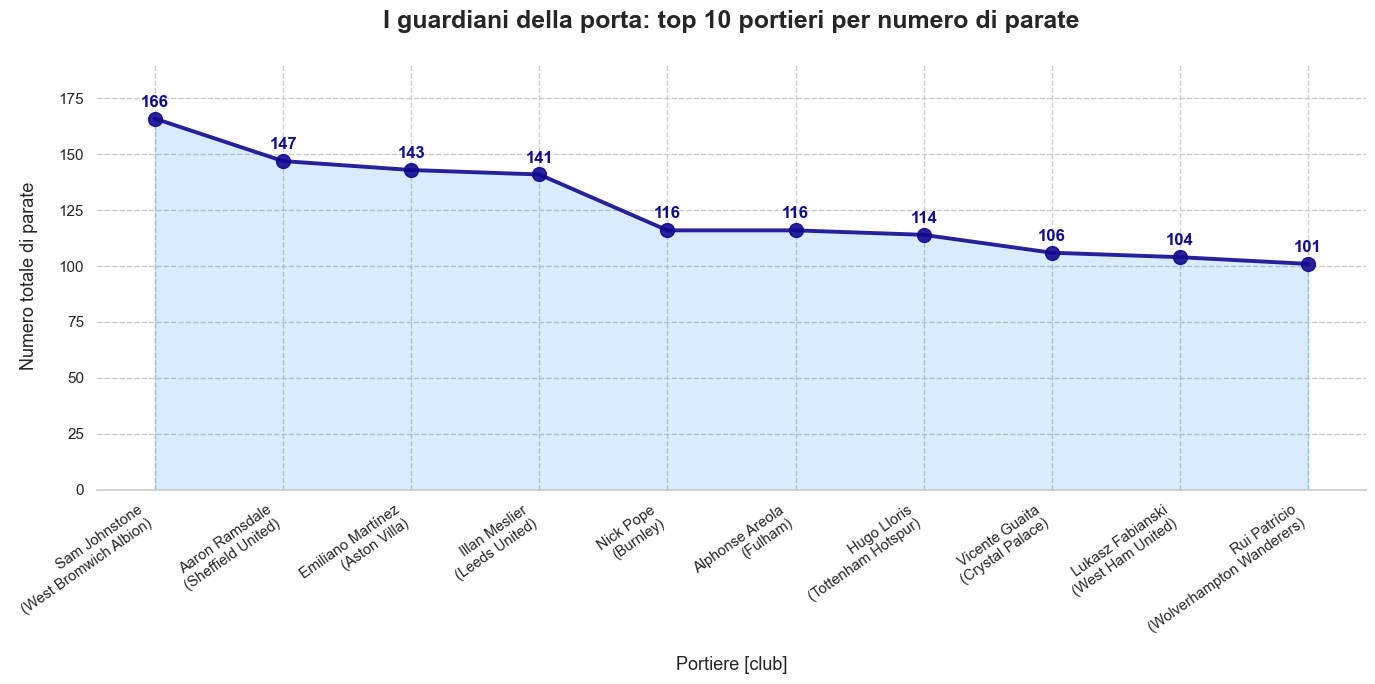

In [120]:
gk_saves_players = (
    df[
        (df["type_displayName"] == "Save") &
        (df["position"] == "GK")
    ]
    .groupby(["name", "team_name"])
    .size()
    .reset_index(name="Parate")
    .sort_values(by="Parate", ascending=False)
    .reset_index(drop=True)
)

top10_gk = gk_saves_players.head(10).copy()
top10_gk["Player_Short"] = top10_gk["name"] + "\n(" + top10_gk["team_name"] + ")"

sns.set_style("whitegrid", {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.15})
plt.figure(figsize=(14, 7))

x_idx = range(len(top10_gk))
y_vals = top10_gk["Parate"].tolist()
labels = top10_gk["Player_Short"].tolist()

plt.fill_between(x_idx, y_vals, color="#007FFF", alpha=0.15)

plt.plot(x_idx, y_vals, color="#120A8F", linewidth=2.8, alpha=0.9, marker='o', markersize=10, zorder=2)

for i, val in enumerate(y_vals):
    plt.text(
        i, val + 4,
        f'{int(val)}',
        ha='center', va='bottom',
        fontsize=12, fontweight='bold', color='#120A8F'
    )

plt.xticks(x_idx, labels, rotation=35, ha='right', fontsize=10.5)

plt.title("I guardiani della porta: top 10 portieri per numero di parate",
          fontsize=18, fontweight='bold', pad=25, loc='center')
plt.xlabel("Portiere [club]", fontsize=13, labelpad=15)
plt.ylabel("Numero totale di parate", fontsize=13, labelpad=15)

plt.ylim(0, max(y_vals) + 25)

sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

<p>
Il grafico evidenzia due dinamiche principali:
</p>

<ul>
  <li>Sam Johnstone (West Bromwich Albion) guida la classifica con 166 parate, staccando nettamente il resto della graduatoria. Un dato che riflette la pesante esposizione difensiva del West Brom, ultimo in classifica con la peggior difesa del campionato, piuttosto che un primato di eccellenza individuale. L'estremo difensore è stato costantemente sollecitato, fungendo da ultimo baluardo per una squadra in difficoltà strutturale;</li>
  <li>il cluster centrale (da Aaron Ramsdale a Hugo Lloris, tra 114 e 147 parate) raggruppa portieri di squadre di fascia medio-bassa (Sheffield United, Aston Villa, Leeds, Fulham, Burnley), confermando la correlazione inversa tra posizione in classifica e volume di lavoro del portiere, cioè più la squadra soffre in fase difensiva, più il proprio estremo difensore è chiamato in causa;</li>
  <li>l'assenza dei portieri delle big (Ederson, Alisson, De Gea) dalla Top 10 non è casuale poichè le squadre di vertice esercitano un dominio territoriale tale da ridurre drasticamente il numero di conclusioni concesse agli avversari, alleggerendo il carico di lavoro del portiere.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

<h4 style="color:#7FFFD4;">Analisi del clean sheet dei portieri</h4>

Per approfondire l'analisi precedente, viene considerato anche il numero di clean sheet, ossia le partite in cui la squadra non ha subito alcuna rete.

Questa metrica fornisce un'indicazione complementare rispetto al numero di parate: mentre un elevato volume di parate segnala un portiere costantemente sollecitato, le clean sheet riflettono la solidità difensiva complessiva della squadra e la capacità del portiere di mantenere la porta inviolata.

Per ciascuna squadra viene individuato il portiere principale (quello con il maggior numero di eventi registrati nel ruolo di *GK*), in modo da associare la clean sheet al suo effettivo protagonista.


In [121]:
clean_sheets = (
    features_df[features_df["goals_conceded"] == 0]
    .groupby("team_name")
    .size()
    .reset_index(name="Clean Sheet")
    .sort_values(by="Clean Sheet", ascending=False)
)

gk_main = (
    df[df["position"] == "GK"]
    .groupby(["team_name", "name"])
    .size()
    .reset_index(name="presenze")
    .sort_values(["team_name", "presenze"], ascending=[True, False])
    .drop_duplicates("team_name")
)

clean_sheets_gk = clean_sheets.merge(
    gk_main[["team_name", "name"]],
    on="team_name",
    how="left"
)

clean_sheets_gk = clean_sheets_gk[["name", "team_name", "Clean Sheet"]]
clean_sheets_gk.columns = ["Portiere", "Squadra", "Clean Sheet"]
clean_sheets_gk.index = range(1, len(clean_sheets_gk) + 1)

clean_sheets_gk.style.set_table_styles([
    {'selector': 'th', 'props': [
        ('background-color', '#00FFFF'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('padding', '6px'),
        ('text-align', 'center')
    ]},
    {'selector': 'td', 'props': [
        ('background-color', '#6495ED'),
        ('color', 'white'),
        ('border', '1px solid white'),
        ('padding', '6px'),
        ('text-align', 'center')
    ]},
    {'selector': 'th.row_heading', 'props': [
        ('background-color', '#00FFFF'),
        ('color', 'white'),
        ('border', '1px solid white')
    ]},
    {'selector': 'table', 'props': [
        ('border-collapse', 'collapse')
    ]}
])

,Portiere,Squadra,Clean Sheet
1,Ederson,Manchester City,19
2,Édouard Mendy,Chelsea,18
3,Emiliano Martínez,Aston Villa,15
4,David de Gea,Manchester United,13
5,Alisson,Liverpool,12
6,Robert Sánchez,Brighton & Hove Albion,12
7,Bernd Leno,Arsenal,12
8,Illan Meslier,Leeds United,12
9,Hugo Lloris,Tottenham Hotspur,12
10,Jordan Pickford,Everton,12


La classifica rispecchia fedelmente la gerarchia del campionato: Ederson (Manchester City, 19) e Édouard Mendy (Chelsea, 18) guidano nettamente, confermando come la porta inviolata sia il prodotto di un sistema difensivo solido più che del singolo intervento del portiere. All'estremo opposto, Sam Johnstone (6 clean sheet) e Aaron Ramsdale (5), pur essendo i portieri con il maggior numero di parate, occupano le ultime posizioni, a dimostrazione che parare molto non equivale a non subire gol. Questo confronto incrociato tra parate e clean sheet evidenzia la differenza tra resistere sotto pressione e controllare il gioco.

<h4 style="color:#7FFFD4;">Sintesi dell'analisi esplorativa e transizione alla classificazione</h4>

L'analisi esplorativa condotta nelle sezioni precedenti ha permesso di trasformare un dataset grezzo di oltre 600.000 eventi in un dataset strutturato a livello di squadra-partita, ricco di feature sintetiche che descrivono le principali dimensioni del gioco: efficacia offensiva, solidità difensiva, possesso palla, disciplina e posizionamento in campo.

I principali risultati emersi possono essere così riassunti:

<ul>
  <li>le feature più discriminanti rispetto all'esito della partita sono quelle legate all'efficacia offensiva (tiri totali, tiri nello specchio) e al volume di passaggi, come confermato dall'analisi di significatività;</li>
  <li>le metriche difensive (<code>Tackle</code>, <code>Interception</code>, <code>Clearance</code>) e il numero di parate dei portieri risultano maggiormente correlate al livello della squadra e alla pressione subita, piuttosto che al singolo risultato della partita;</li>
  <li>le coordinate spaziali medie (<code>mean_x</code>, <code>mean_y</code>) non presentano differenze significative tra le classi di risultato, risultando poco discriminanti se considerate isolatamente;</li>
  <li>la distribuzione del target (Vittoria, Pareggio, Sconfitta) evidenzia un disequilibrio, con i pareggi in netta minoranza rispetto alle altre due classi.</li>
</ul>

<style>
ul li::marker {
  color: #7FFFD4;
}
</style>

Quest'ultima osservazione rappresenta un elemento cruciale per la fase successiva: il disequilibrio tra le classi richiederà un'attenzione particolare nella scelta della strategia di classificazione, al fine di evitare che il modello tenda a sottostimare la classe minoritaria a favore di quelle più rappresentate.

Sulla base di queste evidenze, si procede ora alla fase di classificazione del risultato della partita, con l'obiettivo di costruire un modello predittivo in grado di distinguere tra vittoria, pareggio e sconfitta a partire dalle feature estratte.


<h4 style="color:#4169E1;">Scelta delle feature per la fase di classificazione</h4>

<p>
Prima di addestrare i modelli, è stata effettuata una selezione delle feature in modo da includere esclusivamente variabili che descrivono il comportamento di gioco delle squadre.
</p>

<p>
La filosofia adottata si basa su tre pilastri principali:
</p>
<ul>
  <li>eliminazione del data leakage, cioè sono state rimosse tutte le variabili direttamente correlate all'esito (es. gol segnati, gol subiti, punti ottenuti) che non sarebbero note prima della fine di un match;</li>
  <li>rappresentazione relativa, ovvero anziché considerare i valori assoluti di una squadra, sono state costruite metriche di confronto con l'avversario (differenze, rapporti e scarti assoluti);</li>
  <li>specializzazione, ossia le feature sono state divise tra variabili di equilibrio (per identificare i pareggi) e variabili di superiorità tecnica (per distinguere tra vittoria e sconfitta).</li>
</ul>

<style>
ul li::marker {
  color: #4169E1;
}
</style>

<h4 style="color:#4169E1;">Preparazione del dataset per la classificazione</h4>

<p>
Per poter addestrare un modello capace di discernere l'esito di un match, è indispensabile che ogni riga del dataset contenga non solo le prestazioni della squadra in esame, ma anche quelle del rispettivo avversario nello stesso incontro.
</p>
<p>
Il processo si articola in due passaggi chiave:
</p>
<ol>
  <li>selezione delle feature primitive, vengono isolate le variabili tecniche fondamentali (es. <code>Pass</code>, <code>Tackle</code>, ecc...) che serviranno come base per il calcolo delle metriche comparative;</li>
  <li>self-merge (mirroring), tramite un'operazione di merge sul <code>match_id</code>, il dataset viene unito a se stesso. Questo permette di affiancare alla squadra <code>team</code> le statistiche della squadra <code>opponent</code>, creando per ogni partita una riga che descrive l'intero contesto agonistico.</li>
</ol>
<p>
Questa struttura è fondamentale: permette al modello di non valutare i dati in isolamento, ma in relazione all'avversario, che è il vero motore del risultato sportivo.
</p>

<style>
ol li::marker {
  color: #4169E1;
  font-weight: bold;
}
</style>

In [122]:
clf_df = features_df.copy()
base_cols = [
    "BallRecovery", "Clearance", "Pass", "Tackle", "Interception", 
    "Foul", "Card", "MissedShots", "ShotOnPost", "SavedShot", 
    "Aerial", "TakeOn", "Saves", "mean_x", "mean_y", 
    "mean_endX", "mean_endY", "total_shots", "shots_on_target"
]
base_cols = [c for c in base_cols if c in clf_df.columns]

n_cols = 5  
chunks = [base_cols[i:i + n_cols] for i in range(0, len(base_cols), n_cols)]

if len(chunks[-1]) < n_cols:
    chunks[-1].extend([""] * (n_cols - len(chunks[-1])))

df_base_info = pd.DataFrame(chunks)

print("\n FEATURE PRIMITIVE SELEZIONATE PER IL CONFRONTO ")
display(
    df_base_info.style
    .set_table_styles([
        {'selector': 'th', 'props': [('display', 'none')]},
        {'selector': 'td', 'props': [
            ('background-color', '#4169E1'), 
            ('color', 'white'), 
            ('border', '1px solid white'), 
            ('padding', '8px'),
            ('text-align', 'center'),
            ('font-weight', 'bold'),
            ('width', '150px') 
        ]}
    ])
    .hide(axis="index")
)
print(f"Totale: {len(base_cols)}")


 FEATURE PRIMITIVE SELEZIONATE PER IL CONFRONTO 


0,1,2,3,4
BallRecovery,Clearance,Pass,Tackle,Interception
Foul,Card,MissedShots,ShotOnPost,SavedShot
Aerial,TakeOn,mean_x,mean_y,mean_endX
mean_endY,total_shots,shots_on_target,,


Totale: 18


In [123]:
opp_df = clf_df[["match_id", "team_name"] + base_cols].copy()
opp_df = opp_df.rename(columns={"team_name": "opponent"})
opp_df = opp_df.rename(columns={c: f"{c}_opp" for c in base_cols})

clf_df = clf_df.merge(opp_df, on=["match_id", "opponent"], how="left")
clf_df = clf_df.rename(columns={c: f"{c}_team" for c in base_cols})

print(f"Dimensioni del dataset dopo il merge: {clf_df.shape}")
print("\nEsempio di accoppiamento colonne (Team vs Opponent):")
print(f"- {base_cols[0]}_team vs {base_cols[0]}_opp")
print(f"- {base_cols[1]}_team vs {base_cols[1]}_opp")

Dimensioni del dataset dopo il merge: (760, 47)

Esempio di accoppiamento colonne (Team vs Opponent):
- BallRecovery_team vs BallRecovery_opp
- Clearance_team vs Clearance_opp


<h4 style="color:#4169E1;">Costruzione delle feature comparative</h4>

<p>
Una volta ottenute le statistiche affiancate di entrambe le squadre, vengono calcolate nuove variabili che misurano la relazione di forza tra i due contendenti. Per ogni variabile di base, sono state create tre tipologie di indicatori.
</p>
<ol>
  <li>Differenza (<code>diff</code>): indica il vantaggio o svantaggio competitivo. Un valore positivo segnala una prevalenza della squadra osservata rispetto all'avversario in quella specifica metrica.</li>
  <li>Differenza assoluta (<code>diff_abs</code>): misura il grado di equilibrio complessivo del match. Valori bassi indicano situazioni di parità statistica, fondamentali per identificare i pareggi.</li>
  <li>Rapporto (<code>ratio</code>): fornisce una misura proporzionale dell'efficacia, pesando il volume delle azioni di una squadra rispetto a quelle dell'altra.</li>
</ol>
<p>
Queste trasformazioni permettono al classificatore di catturare non solo chi ha giocato meglio, ma anche quanto sia stato serrato il confronto.
</p>
<style>
ol li::marker {
  color: #4169E1;
  font-weight: bold;
}
</style>

In [124]:
for col in base_cols:
    clf_df[f"{col}_diff"] = clf_df[f"{col}_team"] - clf_df[f"{col}_opp"]
    clf_df[f"{col}_diff_abs"] = clf_df[f"{col}_diff"].abs()
    clf_df[f"{col}_ratio"] = clf_df[f"{col}_team"] / (clf_df[f"{col}_opp"] + 1)

n_generated = len(base_cols) * 3
total_cols = len(clf_df.columns)
df_summary_comp = pd.DataFrame({
    "Metrica di riepilogo": ["Feature primitive", "Feature comparative generate", "Totale colonne nel dataset"],
    "Valore": [len(base_cols), n_generated, total_cols]
})

display(
    df_summary_comp.style
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#ADD8E6'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px')]},
        {'selector': 'td', 'props': [('background-color', '#4169E1'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px')]}
    ])
    .hide(axis="index")
)

Metrica di riepilogo,Valore
Feature primitive,18
Feature comparative generate,54
Totale colonne nel dataset,101


<h4 style="color:#4169E1;">Costruzione delle feature aggregate</h4>

<p>
Per catturare la complessità delle dinamiche di gioco, sono stati introdotti degli indici sintetici. Questi indicatori aggregano diverse statistiche correlate per fornire una misura più robusta della performance di reparto.
</p>
<ol>
  <li>Forza offensiva (<code>attack_strength</code>): calcolata pesando i tiri totali e i tiri in porta. Fornisce una visione d'insieme della pericolosità creata.</li>
  <li>Solidità difensiva (<code>defense_strength</code>): un indice che somma interventi difensivi critici come tackle, intercetti, recuperi palla e clearance.</li>
  <li>Precisione al tiro (<code>shot_accuracy</code>): definita come il rapporto tra tiri nello specchio e tiri totali, per misurare l'efficacia realizzativa.</li>
  <li>Indice di costruzione (<code>pass_per_shot</code>): descrive lo stile di gioco, misurando quanti passaggi vengono effettuati prima di arrivare alla conclusione.</li>
</ol>
<p>
Anche per queste macro-feature sono state calcolate le varianti diff e diff_abs, permettendo al modello di valutare il gap di forza tra i due reparti contrapposti.
</p>
<style>
ol li::marker {
  color: #4169E1;
  font-weight: bold;
}
</style>

In [125]:
clf_df["attack_strength_team"] = (
    clf_df.get("total_shots_team", 0)
    + 2 * clf_df.get("shots_on_target_team", 0)
    + clf_df.get("ShotOnPost_team", 0)
    + clf_df.get("MissedShots_team", 0)
)

clf_df["attack_strength_opp"] = (
    clf_df.get("total_shots_opp", 0)
    + 2 * clf_df.get("shots_on_target_opp", 0)
    + clf_df.get("ShotOnPost_opp", 0)
    + clf_df.get("MissedShots_opp", 0)
)

clf_df["attack_strength_diff"] = clf_df["attack_strength_team"] - clf_df["attack_strength_opp"]
clf_df["attack_strength_diff_abs"] = clf_df["attack_strength_diff"].abs()

clf_df["defense_strength_team"] = (
    clf_df.get("Clearance_team", 0)
    + clf_df.get("Interception_team", 0)
    + clf_df.get("Tackle_team", 0)
    + clf_df.get("BallRecovery_team", 0)
)

clf_df["defense_strength_opp"] = (
    clf_df.get("Clearance_opp", 0)
    + clf_df.get("Interception_opp", 0)
    + clf_df.get("Tackle_opp", 0)
    + clf_df.get("BallRecovery_opp", 0)
)

clf_df["defense_strength_diff"] = clf_df["defense_strength_team"] - clf_df["defense_strength_opp"]
clf_df["defense_strength_diff_abs"] = clf_df["defense_strength_diff"].abs()

clf_df["shot_accuracy_team"] = clf_df.get("shots_on_target_team", 0) / (clf_df.get("total_shots_team", 0) + 1)
clf_df["shot_accuracy_opp"] = clf_df.get("shots_on_target_opp", 0) / (clf_df.get("total_shots_opp", 0) + 1)
clf_df["shot_accuracy_diff"] = clf_df["shot_accuracy_team"] - clf_df["shot_accuracy_opp"]
clf_df["shot_accuracy_diff_abs"] = clf_df["shot_accuracy_diff"].abs()

clf_df["pass_per_shot_team"] = clf_df.get("Pass_team", 0) / (clf_df.get("total_shots_team", 0) + 1)
clf_df["pass_per_shot_opp"] = clf_df.get("Pass_opp", 0) / (clf_df.get("total_shots_opp", 0) + 1)
clf_df["pass_per_shot_diff"] = clf_df["pass_per_shot_team"] - clf_df["pass_per_shot_opp"]

cols_to_show = [
    "team_name", "opponent", 
    "attack_strength_team", "attack_strength_opp", "attack_strength_diff", "attack_strength_diff_abs",
    "defense_strength_team", "defense_strength_opp", "defense_strength_diff", "defense_strength_diff_abs",
    "shot_accuracy_team", "shot_accuracy_opp", "shot_accuracy_diff", "shot_accuracy_diff_abs",
    "pass_per_shot_team", "pass_per_shot_opp", "pass_per_shot_diff"
]

example_agg = clf_df[cols_to_show].head(4)

display(
    example_agg.style
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#0000FF'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('background-color', '#4169E1'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]}
    ])
    .format({
        "attack_strength_team": "{:.1f}",
        "attack_strength_opp": "{:.1f}",
        "attack_strength_diff": "{:.1f}",
        "attack_strength_diff_abs": "{:.1f}",
        "defense_strength_team": "{:.1f}",
        "defense_strength_opp": "{:.1f}",
        "defense_strength_diff": "{:.1f}",
        "defense_strength_diff_abs": "{:.1f}",
        "shot_accuracy_team": "{:.2f}",
        "shot_accuracy_opp": "{:.2f}",
        "shot_accuracy_diff": "{:.2f}",
        "shot_accuracy_diff_abs": "{:.2f}",
        "pass_per_shot_team": "{:.1f}",
        "pass_per_shot_opp": "{:.1f}",
        "pass_per_shot_diff": "{:.1f}"
    })
    .hide(axis="index")
)

team_name,opponent,attack_strength_team,attack_strength_opp,attack_strength_diff,attack_strength_diff_abs,defense_strength_team,defense_strength_opp,defense_strength_diff,defense_strength_diff_abs,shot_accuracy_team,shot_accuracy_opp,shot_accuracy_diff,shot_accuracy_diff_abs,pass_per_shot_team,pass_per_shot_opp,pass_per_shot_diff
Manchester United,Burnley,37.0,27.0,10.0,10.0,101.0,92.0,9.0,9.0,0.79,0.42,0.37,0.37,43.3,31.2,12.1
Burnley,Manchester United,27.0,37.0,-10.0,10.0,92.0,101.0,-9.0,9.0,0.42,0.79,-0.37,0.37,31.2,43.3,-12.1
Aston Villa,Manchester City,29.0,79.0,-50.0,50.0,96.0,86.0,10.0,10.0,0.58,0.76,-0.18,0.18,25.7,23.2,2.4
Manchester City,Aston Villa,79.0,29.0,50.0,50.0,86.0,96.0,-10.0,10.0,0.76,0.58,0.18,0.18,23.2,25.7,-2.4


<p>
Come si può osservare dalla tabella, gli indici catturano correttamente la natura speculare della partita: se il Manchester United ha un <code>attack_strength_diff</code> di +10, il Burnley presenta un valore identico ma di segno opposto (-10). 
</p>
<p>
Casi emblematici, come quello di Aston Villa vs Manchester City, mostrano un gap molto ampio (-50 nell'indice d'attacco), evidenziando una netta predominanza tecnica che il modello potrà utilizzare per distinguere una vittoria da una sconfitta.
</p>


<h4 style="color:#4169E1;">Costruzione delle feature di equilibrio della partita</h4>

<p>
Per ottimizzare il riconoscimento dei pareggi, è necessario disporre di variabili che misurino quanto il match sia stato bilanciato, indipendentemente dal volume totale di azioni prodotte. A tal fine, sono stati creati degli indici di equilibrio relativo.
</p>
<ol>
  <li>Bilanciamento dei tiri (<code>shot_balance</code>): misura lo scarto assoluto dei tiri in porta rapportato al volume totale di conclusioni del match. Un valore vicino allo zero indica una sfida estremamente equilibrata sotto porta.</li>
  <li>Equilibrio territoriale (<code>territorial_balance</code>): somma le differenze assolute nelle posizioni medie (di partenza e di arrivo delle azioni), identificando match dove le squadre si sono affrontate prevalentemente a metà campo senza una chiara supremazia spaziale.</li>
  <li>Bilanciamento difensivo (<code>defensive_balance</code>): pesa lo scarto dell'attività difensiva sul totale degli interventi compiuti da entrambi i team.</li>
</ol>
<p>
Questi indicatori sono fondamentali perché permettono al modello di distinguere tra un pareggio combattuto e una partita dominata da un solo lato, superando i limiti delle semplici statistiche grezze.
</p>
<style>
ol li::marker {
  color: #4169E1;
  font-weight: bold;
}
</style>

In [126]:
clf_df["total_shots_match"] = clf_df.get("total_shots_team", 0) + clf_df.get("total_shots_opp", 0)
clf_df["shots_on_target_match"] = clf_df.get("shots_on_target_team", 0) + clf_df.get("shots_on_target_opp", 0)
clf_df["passes_match"] = clf_df.get("Pass_team", 0) + clf_df.get("Pass_opp", 0)

clf_df["def_actions_match"] = (
    clf_df.get("Clearance_team", 0) + clf_df.get("Interception_team", 0) +
    clf_df.get("Tackle_team", 0) + clf_df.get("BallRecovery_team", 0) +
    clf_df.get("Clearance_opp", 0) + clf_df.get("Interception_opp", 0) +
    clf_df.get("Tackle_opp", 0) + clf_df.get("BallRecovery_opp", 0)
)

clf_df["shot_balance"] = clf_df["shots_on_target_diff_abs"] / (clf_df["shots_on_target_match"] + 1)
clf_df["territorial_balance"] = clf_df["mean_x_diff_abs"] + clf_df["mean_endX_diff_abs"]
clf_df["defensive_balance"] = clf_df["defense_strength_diff_abs"] / (clf_df["def_actions_match"] + 1)

cols_balance = ["team_name", "opponent", "shot_balance", "territorial_balance", "defensive_balance"]
example_balance = clf_df[cols_balance].head(4)

display(
    example_balance.style
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#4169E1'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('background-color', '#99CBFF'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]}
    ])
    .format({
        "shot_balance": "{:.3f}",
        "territorial_balance": "{:.2f}",
        "defensive_balance": "{:.3f}"
    })
    .hide(axis="index")
)

team_name,opponent,shot_balance,territorial_balance,defensive_balance
Manchester United,Burnley,0.353,5.07,0.046
Burnley,Manchester United,0.353,5.07,0.046
Aston Villa,Manchester City,0.500,25.45,0.055
Manchester City,Aston Villa,0.500,25.45,0.055


<p>
Gli indici di bilanciamento confermano l'andamento del match: valori vicini allo 0 indicano equilibrio, mentre valori alti segnalano una netta discrepanza. 
</p>
<p>
Ad esempio, il match Manchester United vs Burnley mostra un <code>territorial_balance</code> molto basso (5.07), segno di un confronto giocato su baricentri simili. Al contrario, Aston Villa vs Manchester City presenta un valore di 25.45, indicando che una delle due squadre ha schiacciato l'altra territorialmente, portando il match lontano dall'equilibrio tipico del pareggio.
</p>

<h4 style="color:#4169E1;">Selezione delle feature ottimali</h4>

<p>
In questa sezione vengono definiti i set di feature che verranno utilizzati per l'addestramento dei modelli.
La scelta è basata sulla distinzione logica tra variabili di bilanciamento (per identificare i pareggi) e variabili di forza relativa (per distinguere vittorie e sconfitte).
</p>

In [127]:
stage1_features = [
    "total_shots_diff_abs", "shots_on_target_diff_abs", "Pass_diff_abs", 
    "Tackle_diff_abs", "mean_x_diff_abs", "mean_endX_diff_abs", 
    "shot_balance", "territorial_balance"
]

stage2_features = [
    "attack_strength_diff", "defense_strength_diff", "shots_on_target_diff", 
    "shot_accuracy_diff", "pass_per_shot_diff", "shots_on_target_team", 
    "shots_on_target_opp", "Clearance_diff"
]

optimized_features = list(set(stage1_features + stage2_features))
print(f"Feature totali costruite: {len(clf_df.columns)}")
print(f"Feature selezionate per i modelli: {len(optimized_features)}")

Feature totali costruite: 123
Feature selezionate per i modelli: 16


<h4 style="color:#4169E1;">Costruzione del dataset di apprendimento</h4>

<p>
Prima della suddivisione, il dataset viene sottoposto a un'operazione di pulizia finale e formattazione tecnica.
</p>
<ol>
  <li>Vengono eliminati gli identificativi tecnici (es. <code>match_id</code>, <code>team_name</code>) e tutte le variabili legate ai gol segnati, per blindare il modello contro eventuali data leakage.</li>
  <li>Vengono mantenute esclusivamente le colonne numeriche. Eventuali valori infiniti (derivati dai rapporti calcolati precedentemente) vengono normalizzati a zero per non destabilizzare gli algoritmi.</li>
  <li>Vengono creati la matrice delle feature <code>X</code> e il vettore dell'esito <code>y</code> (Vittoria, Pareggio, Sconfitta).</li>
</ol>
<p>
Segue una panoramica delle dimensioni del dataset e della distribuzione delle classi, utile per confermare l'equilibrio numerico tra vittorie e sconfitte e la minoranza strutturale dei pareggi.
</p>


<style>
ol li::marker {
  color: #4169E1;
  font-weight: bold;
}
</style>


In [128]:
drop_cols = [
    "match_id", "team_name", "opponent",
    "result", "Goal", "goals", "goals_conceded", "points"
]
drop_cols = [c for c in drop_cols if c in clf_df.columns]

X_full = clf_df.drop(columns=drop_cols).copy()
X_full = X_full.select_dtypes(include=[np.number]).replace([np.inf, -np.inf], np.nan).fillna(0)
y_full = clf_df["result"].copy()

overview_df = pd.DataFrame({
    "Informazione": [
        "Numero osservazioni",
        "Numero feature disponibili",
        "Numero vittorie",
        "Numero sconfitte",
        "Numero pareggi"
    ],
    "Valore": [
        X_full.shape[0],
        X_full.shape[1],
        (y_full == "Vittoria").sum(),
        (y_full == "Sconfitta").sum(),
        (y_full == "Pareggio").sum()
    ]
})

table_style_overview = [
    {
        'selector': 'th',
        'props': [
            ('background-color', '#4169E1'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'td',
        'props': [
            ('background-color', '#6495ED'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'th.row_heading',
        'props': [
            ('background-color', '#6495ED'),
            ('color', 'white'),
            ('border', '1px solid white')
        ]
    },
    {
        'selector': 'table',
        'props': [
            ('border-collapse', 'collapse')
        ]
    }
]

display(
    overview_df.style
    .set_table_styles(table_style_overview)
    .hide(axis="index")
)

Informazione,Valore
Numero osservazioni,760
Numero feature disponibili,116
Numero vittorie,297
Numero sconfitte,297
Numero pareggi,166


<h4 style="color:#4169E1;">Suddivisione del dataset</h4>

<p>
Per costruire e valutare correttamente il sistema di classificazione, il dataset viene ripartito in tre sotto-insiemi distinti, utilizzando una tecnica di campionamento stratificato per preservare la proporzione delle classi originali.
</p>

<p>
In particolare:
</p>

<ul>
  <li>il training set (70%) è stato utilizzato per l'addestramento e il fitting dei modelli di classificazione;</li>
  <li>il validation set (10%) è stato utilizzato per la scelta della soglia, la sintonizzazione degli iperparametri e la valutazione intermedia delle prestazioni;</li>
  <li>il test set (20%) è stato mantenuto separato fino alla fine ed è stato usato esclusivamente per la valutazione finale delle performance.</li>
</ul>

<p>
Questa distinzione è fondamentale per evitare che il modello venga valutato sugli stessi dati utilizzati per addestrarlo o per ottimizzarne il comportamento.
</p>

<style>
ul li::marker {
  color: #4169E1;
}
</style>


In [129]:
X_temp, X_test_full, y_temp, y_test_full = train_test_split(
    X_full, y_full,
    test_size=0.20,
    random_state=42,
    stratify=y_full
)

X_train_full, X_val_full, y_train_full, y_val_full = train_test_split(
    X_temp, y_temp,
    test_size=0.125,   
    random_state=42,
    stratify=y_temp
)

df_split = pd.DataFrame({
    "Set di Dati": ["Training Set", "Validation Set", "Test Set", "Totale"],
    "Esempi": [len(X_train_full), len(X_val_full), len(X_test_full), len(X_full)],
    "Percentuale": [
        f"{(len(X_train_full)/len(X_full)*100):.1f}%",
        f"{(len(X_val_full)/len(X_full)*100):.1f}%",
        f"{(len(X_test_full)/len(X_full)*100):.1f}%",
        "100%"
    ]
})
print("\n SUDDIVISIONE DEL DATASET ")
display(
    df_split.style
    .set_table_styles([
        {'selector': 'th', 'props': [('background-color', '#002FA7'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('background-color', '#4169E1'), ('color', 'white'), ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]}
    ])
    .hide(axis="index")
)


 SUDDIVISIONE DEL DATASET 


Set di Dati,Esempi,Percentuale
Training Set,532,70.0%
Validation Set,76,10.0%
Test Set,152,20.0%
Totale,760,100%


<h4 style="color:#4169E1;">Primo approccio: classificazione diretta multiclass</h4>

<p>
Il primo tentativo di modellazione consiste nel trattare il problema come una classificazione multiclasse diretta a tre uscite (Vittoria, Pareggio, Sconfitta). L'obiettivo è verificare se i classificatori tradizionali siano in grado di catturare le dinamiche del match utilizzando l'intero set di feature disponibili.
</p>
<p>
Vengono messi a confronto quattro algoritmi con diverse filosofie di apprendimento.
</p>
<ul>
  <li>Decision Tree: un modello basato su regole gerarchiche, utile per testare la separabilità lineare dei dati.</li>
  <li>Naive Bayes (Gaussiano): un classificatore probabilistico rapido, ideale come baseline statistica.</li>
  <li>SVM (RBF Kernel): un algoritmo potente che mappa i dati in uno spazio a dimensioni superiori per trovare i confini ottimali tra le classi.</li>
  <li>Random Forest: un ensemble di alberi decisionali che riduce il rischio di overfitting attraverso la combinazione di più previsioni (bagging).</li>
</ul>

<style>
ul li::marker {
  color: #4169E1;
}
</style>

In [130]:
X_train_opt = X_train_full[optimized_features]
X_test_opt = X_test_full[optimized_features]

scaler_trad = StandardScaler()
X_train_sc = scaler_trad.fit_transform(X_train_opt)
X_test_sc  = scaler_trad.transform(X_test_opt)

classifiers = {
    "Decision Tree": (DecisionTreeClassifier(random_state=42, max_depth=6), False),
    "Naive Bayes":   (GaussianNB(), True),
    "SVM (RBF)":     (SVC(kernel="rbf", random_state=42, C=1.0, gamma="scale"), True),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=42, max_depth=8), False)
}

comp_rows = []
clf_preds = {}
labels_order = ["Vittoria", "Pareggio", "Sconfitta"]

for name, (clf, needs_sc) in classifiers.items():
    Xtr = X_train_sc if needs_sc else X_train_opt
    Xte = X_test_sc  if needs_sc else X_test_opt
    clf.fit(Xtr, y_train_full)
    preds = clf.predict(Xte)
    clf_preds[name] = preds
    comp_rows.append({
        "Classificatore": name,
        "Accuracy":       round(accuracy_score(y_test_full, preds), 4),
        "Balanced Acc.":  round(balanced_accuracy_score(y_test_full, preds), 4),
        "F1 Macro":       round(f1_score(y_test_full, preds, average="macro", zero_division=0), 4),
        "F1 Weighted":    round(f1_score(y_test_full, preds, average="weighted", zero_division=0), 4)
    })

comp_df = pd.DataFrame(comp_rows)
comp_df.index = range(1, len(comp_df) + 1)

ts_style = [
    {'selector':'th','props':[('background-color','#4169E1'),('color','white'),('border', '1px solid white'),('padding','6px'),('text-align','center')]},
    {'selector':'td','props':[('background-color','#B0E0E6'),('color','white'),('border', '1px solid white'),('padding','6px'),('text-align','center')]},
    {'selector':'th.row_heading','props':[('background-color','#4169E1'),('color','white'),('border', '1px solid white')]},
    {'selector':'table','props':[('border-collapse','collapse')]}
]

display(comp_df.style.set_table_styles(ts_style))

,Classificatore,Accuracy,Balanced Acc.,F1 Macro,F1 Weighted
1,Decision Tree,0.506600,0.453700,0.449800,0.499900
2,Naive Bayes,0.526300,0.452600,0.416600,0.480900
3,SVM (RBF),0.611800,0.521000,0.457600,0.537400
4,Random Forest,0.605300,0.519800,0.472300,0.545400


<p>
I risultati evidenziano come, nonostante un'accuratezza complessiva apparentemente soddisfacente (che tocca il 61.18% con SVM), i modelli tradizionali soffrano di un problema critico.
</p>

<ul>
  <li>Gap tra Accuracy e Balanced Accuracy: la differenza marcata tra queste due metriche suggerisce che i modelli stiano sovra-predicendo le classi maggioritarie (Vittoria e Sconfitta) a scapito dei Pareggi.</li>
  <li>F1-Score Macro ridotto: un valore intorno allo 0.47 conferma che la capacità predittiva non è uniforme tra le classi. Il modello ignora parzialmente la classe più difficile (Pareggio) per massimizzare il risultato sulle altre.</li>
  <li>Superiorità degli ensemble: il Random Forest si dimostra il più equilibrato, ma non riesce comunque a superare la complessità intrinseca della classificazione multiclasse diretta su dati così rumorosi.</li>
</ul>

<p>
Queste evidenze confermano la necessità di una strategia più sofisticata, capace di isolare il problema dell'equilibrio (Pareggio) dalle dinamiche di forza relativa (Vittoria/Sconfitta).
</p>

<style>
ul li::marker {
  color: #4169E1;
}
</style>


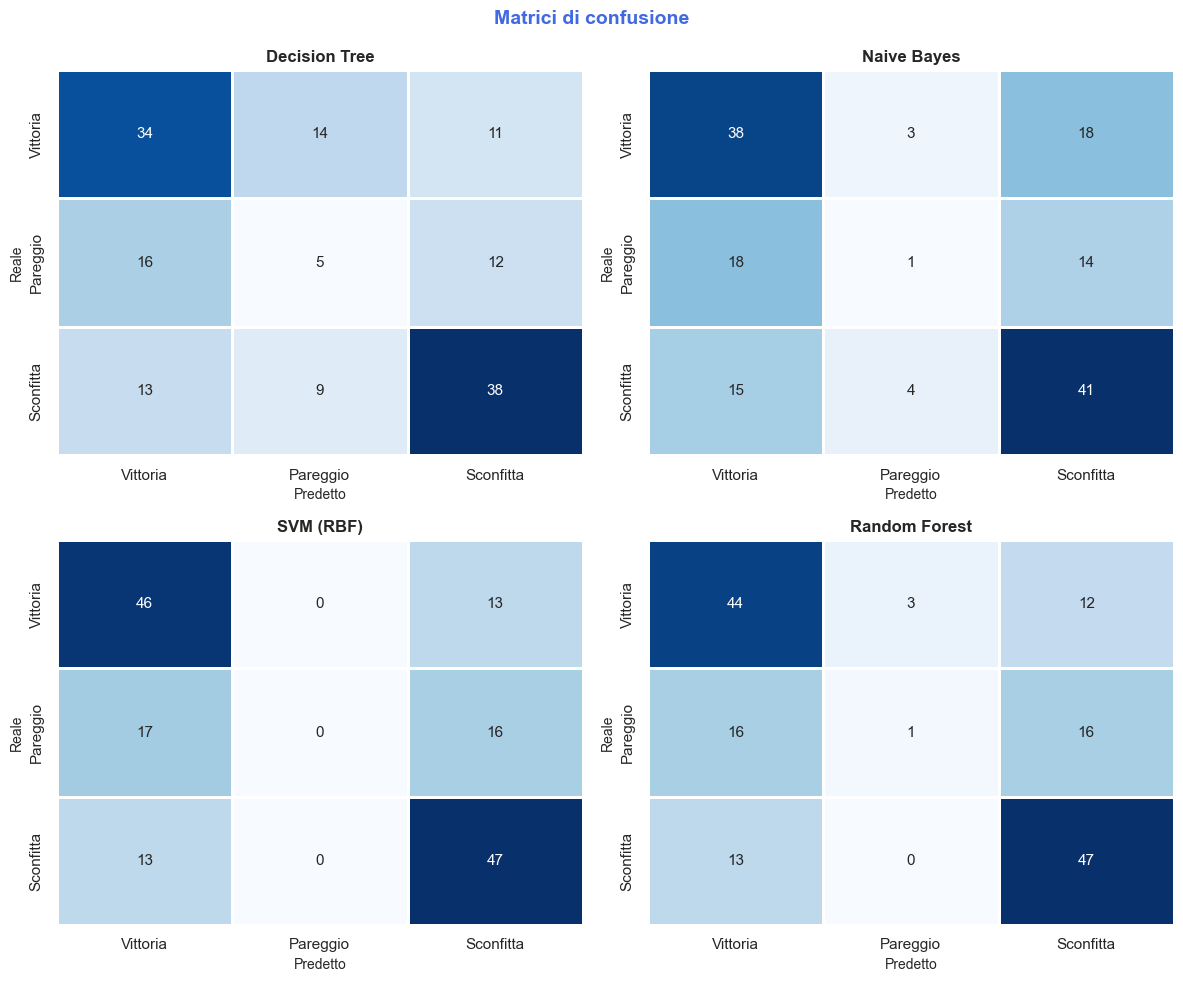

In [131]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Matrici di confusione",
             fontsize=14, fontweight="bold", color="#4169E1")

for ax, (name, preds) in zip(axes.flatten(), clf_preds.items()):
    cm = confusion_matrix(y_test_full, preds, labels=labels_order)
    cm_d = pd.DataFrame(cm, index=labels_order, columns=labels_order)
    sns.heatmap(cm_d, annot=True, fmt="d", cmap="Blues",
                linewidths=1, linecolor="white", cbar=False,
                ax=ax, annot_kws={"size":11})
    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel("Predetto", fontsize=10)
    ax.set_ylabel("Reale", fontsize=10)

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

<p>
L'osservazione delle matrici di confusione rivela il limite fatale della classificazione diretta in questo dataset:
</p>

<ul>
  <li>il modello SVM non riesce a indovinare nessun pareggio (zero valori sulla diagonale centrale). Anche il Random Forest e il Naive Bayes ne identificano correttamente solo uno;</li>
  <li>i modelli tendono a rifugiarsi nelle classi Vittoria o Sconfitta, che presentano segnali statistici più chiari (es. uno squilibrio netto nei tiri), ignorando le situazioni di equilibrio;</li>
  <li>sebbene l'albero decisionale provi a prevedere qualche pareggio in più, lo fa con un tasso di errore elevatissimo, confondendo spesso i pareggi reali con sconfitte o vittorie.</li>
</ul>

<p>
Questo fenomeno, tecnicamente noto come incapacità di separazione della classe minoritaria, è il motivo principale per cui è stato progettato il sistema Two-Stage: isolare il pareggio in una fase dedicata permette al modello di concentrarsi sui segnali di equilibrio senza essere distratto dalla dominanza delle altre due classi.
</p>

<style>
ul li::marker {
  color: #4169E1;
}
</style>


In [132]:
best_name = comp_df.loc[comp_df["F1 Macro"].idxmax(), "Classificatore"]

print(f"\n CLASSIFICATION REPORT \u2013 {best_name} (migliore tra i tradizionali) ")

best_rep = pd.DataFrame(
    classification_report(y_test_full, clf_preds[best_name],
                          labels=labels_order, target_names=labels_order,
                          output_dict=True, zero_division=0)
).transpose().round(4)

display(best_rep.style.set_table_styles(ts_style))


 CLASSIFICATION REPORT – Random Forest (migliore tra i tradizionali) 


,precision,recall,f1-score,support
Vittoria,0.602700,0.745800,0.666700,59.000000
Pareggio,0.250000,0.030300,0.054100,33.000000
Sconfitta,0.626700,0.783300,0.696300,60.000000
accuracy,0.605300,0.605300,0.605300,0.605300
macro avg,0.493100,0.519800,0.472300,152.000000
weighted avg,0.535600,0.605300,0.545400,152.000000


<p>
L'analisi dettagliata delle metriche per singola classe conferma matematicamente quanto visto graficamente.
</p>

<ul>
  <li>Recall dei pareggi quasi nulla (3.0%): questo dato è allarmante. Significa che, su 100 pareggi reali avvenuti in campo, il modello è in grado di individuarne solo 3. Il sistema è praticamente cieco di fronte allo scenario di parità.</li>
  <li>F1-Score del pareggio (0.05): un valore così vicino allo zero indica che il modello non ha appreso alcuna regola utile per questa classe.</li>
  <li>Performance discrete su Vittoria/Sconfitta: con F1-score vicini allo 0.68, si nota che il modello sa distinguere correttamente quando una squadra prevale nettamente sull'altra, ma fatica a capire quando le forze si equivalgono.</li>
</ul>

<p>
La classificazione multiclasse diretta non è adatta a questo problema a causa dello sbilanciamento e della natura ibrida del pareggio. È necessario un cambio di paradigma: il sistema Two-Stage XGBoost, che sarà affrontato nella prossima sezione.
</p>

<style>
ul li::marker {
  color: #4169E1;
}
</style>


<h4 style="color:#4169E1;">Secondo approccio: sistema two-stage con XGBoost</h4>

<p>
Per affrontare il problema e superare i limiti evidenziati dai classificatori tradizionali, è stato adottato un approccio two-stage (a due stadi), che consente di scomporre la classificazione multiclass in due problemi binari più semplici e più coerenti con la natura del gioco.
</p>

<p>
Il flusso decisionale segue questa logica:
</p>
<ol>
  <li>stadio 1 (rilevamento equilibrio) dove un primo classificatore decide se la partita finirà in Pareggio o Non-Pareggio. Questo stadio è addestrato esclusivamente sulle feature di balance per ignorare chi stia giocando meglio e concentrarsi solo su quanto il match sia serrato;</li>
  <li>stadio 2 (determinazione vincitore), dove se il primo stadio decide che non è un pareggio, interviene un secondo classificatore che deve distinguere tra Vittoria e Sconfitta. Qui entrano in gioco le feature di strength per pesare la superiorità di un reparto sull'altro.</li>
</ol>
<p>
Questa scomposizione permette di ottimizzare separatamente i due modelli, affrontando il problema del pareggio in una bolla protetta dove non deve competere con i segnali più forti delle vittorie nette.
</p>
<style>
ol li::marker {
  color: #4169E1;
  font-weight: bold;
}
</style>

<h4 style="color:#4169E1;">Specializzazione delle feature per stadio</h4>

<p>
A differenza dell'approccio multiclass, dove tutte le variabili venivano date in pasto al modello indistintamente, il sistema two-stage opera una separazione netta tra gli input, fornendo a ogni classificatore solo le informazioni pertinenti al suo compito specifico.
</p>

<p>
Le feature utilizzate nel primo modello (Pareggio vs Non Pareggio) sono progettate per catturare il grado di equilibrio tra le due squadre, cioè quanto la partita presenti caratteristiche compatibili con un esito di pareggio.
</p>

<table style="border-collapse: collapse; width: 100%; font-size: 0.9em; line-height: 1.2;">
  <thead>
    <tr>
      <th style="border:1px solid #99CBFF; padding:4px; color:#4169E1; text-align:left; width: 25%;">Feature</th>
      <th style="border:1px solid #99CBFF; padding:4px; color:#4169E1; text-align:left; width: 35%;">Descrizione</th>
      <th style="border:1px solid #99CBFF; padding:4px; color:#4169E1; text-align:left; width: 40%;">Interpretazione</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>total_shots_diff_abs</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza assoluta nel numero totale di tiri tra le due squadre</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Valori bassi indicano produzione offensiva simile e quindi maggiore probabilità di equilibrio</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>shots_on_target_diff_abs</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza assoluta nei tiri in porta</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Misura la pericolosità reale delle occasioni create e quindi l’equilibrio qualitativo della partita</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>Pass_diff_abs</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza nel numero di passaggi completati</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Indica equilibrio nel controllo del gioco e nella costruzione della manovra</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>Tackle_diff_abs</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza nel numero di tackle effettuati</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Descrive il bilanciamento nell’intensità difensiva e nella capacità di contrasto</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>mean_x_diff_abs</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza assoluta nella posizione media sull’asse orizzontale del campo</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Misura l’equilibrio territoriale tra le due squadre</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>mean_endX_diff_abs</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza assoluta nella posizione finale media delle azioni sull’asse X</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Valori bassi indicano una capacità simile di avanzare nel campo</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>shot_balance</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Indicatore normalizzato del bilanciamento nei tiri in porta</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Permette di distinguere partite realmente equilibrate da partite con pochi eventi offensivi</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>territorial_balance</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Indicatore sintetico dell’equilibrio territoriale</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Riassume quanto le due squadre abbiano occupato il campo in modo simile</td>
    </tr>
  </tbody>
</table>

<p>
Le feature del secondo modello (Vittoria vs Sconfitta) descrivono la superiorità relativa di una squadra nelle partite che non terminano in pareggio.
</p>

<table style="border-collapse: collapse; width: 100%; font-size: 0.9em; line-height: 1.2;">
  <thead>
    <tr>
      <th style="border:1px solid #99CBFF; padding:4px; color:#4169E1; width: 25%; text-align:left;">Feature</th>
      <th style="border:1px solid #99CBFF; padding:4px; color:#4169E1; width: 35%; text-align:left;">Descrizione</th>
      <th style="border:1px solid #99CBFF; padding:4px; color:#4169E1; width: 40%; text-align:left;">Interpretazione</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>attack_strength_diff</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza nella forza offensiva complessiva tra squadra e avversaria</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Indica quale squadra crea più pressione offensiva e occasioni da gol</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>defense_strength_diff</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza nella solidità difensiva tra le due squadre</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Mostra quale squadra difende meglio e recupera più palloni</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>shots_on_target_diff</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza nei tiri in porta tra squadra e avversaria</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Misura diretta della pericolosità offensiva relativa</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>shot_accuracy_diff</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza nella precisione dei tiri</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Distingue tra volume offensivo e qualità delle conclusioni</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>pass_per_shot_diff</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza nel rapporto tra passaggi e tiri</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Descrive lo stile di gioco (diretto vs manovrato)</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>shots_on_target_team</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Numero assoluto di tiri in porta della squadra</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Misura diretta della capacità offensiva della squadra</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>shots_on_target_opp</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Numero di tiri in porta concessi all’avversario</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Indica la vulnerabilità difensiva della squadra</td>
    </tr>
    <tr>
      <td style="border:1px solid #99CBFF; padding:4px;"><code>Clearance_diff</code></td>
      <td style="border:1px solid #99CBFF; padding:4px;">Differenza nei rinvii difensivi tra squadra e avversaria</td>
      <td style="border:1px solid #99CBFF; padding:4px;">Segnala pressione difensiva e situazioni di difficoltà</td>
    </tr>
  </tbody>
</table>

<h4 style="color:#4169E1;">Selezione finale delle feature per i due stadi</h4>

<p>
A questo punto vengono selezionate in modo esplicito le feature utilizzate dal primo e dal secondo modello.
</p>

In [133]:
stage1_features = [
    "total_shots_diff_abs",
    "shots_on_target_diff_abs",
    "Pass_diff_abs",
    "Tackle_diff_abs",
    "mean_x_diff_abs",
    "mean_endX_diff_abs",
    "shot_balance",
    "territorial_balance"
]
stage1_features = [c for c in stage1_features if c in X_train_full.columns]

stage2_features = [
    "attack_strength_diff",
    "defense_strength_diff",
    "shots_on_target_diff",
    "shot_accuracy_diff",
    "pass_per_shot_diff",
    "shots_on_target_team",
    "shots_on_target_opp",
    "Clearance_diff"
]
stage2_features = [c for c in stage2_features if c in X_train_full.columns]

max_len = max(len(stage1_features), len(stage2_features))
stage1_display = stage1_features + [""] * (max_len - len(stage1_features))
stage2_display = stage2_features + [""] * (max_len - len(stage2_features))

feature_summary_df = pd.DataFrame({
    "Stadio 1 - Pareggio vs Non Pareggio": stage1_display,
    "Stadio 2 - Vittoria vs Sconfitta": stage2_display
})
feature_summary_df.index = range(1, len(feature_summary_df) + 1)

table_style_features = [
    {
        'selector': 'th',
        'props': [
            ('background-color', '#00008B'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'td',
        'props': [
            ('background-color', '#4169E1'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'th.row_heading',
        'props': [
            ('background-color', '#00008B'),
            ('color', 'white'),
            ('border', '1px solid white')
        ]
    },
    {
        'selector': 'table',
        'props': [
            ('border-collapse', 'collapse')
        ]
    }
]

display(feature_summary_df.style.set_table_styles(table_style_features))

,Stadio 1 - Pareggio vs Non Pareggio,Stadio 2 - Vittoria vs Sconfitta
1,total_shots_diff_abs,attack_strength_diff
2,shots_on_target_diff_abs,defense_strength_diff
3,Pass_diff_abs,shots_on_target_diff
4,Tackle_diff_abs,shot_accuracy_diff
5,mean_x_diff_abs,pass_per_shot_diff
6,mean_endX_diff_abs,shots_on_target_team
7,shot_balance,shots_on_target_opp
8,territorial_balance,Clearance_diff


<h4 style="color:#4169E1;">Preparazione del dataset per il primo stadio</h4>

<p>
Nel primo stadio il target viene trasformato in una variabile binaria:
</p>

<ul>
  <li>1 = Pareggio</li>
  <li>0 = Non Pareggio</li>
</ul>

<style>
ul li::marker {
  color: #4169E1;
}
</style>

In [134]:
X_train_s1 = X_train_full[stage1_features].copy()
X_val_s1 = X_val_full[stage1_features].copy()
X_test_s1 = X_test_full[stage1_features].copy()

y_train_s1 = (y_train_full == "Pareggio").astype(int)
y_val_s1 = (y_val_full == "Pareggio").astype(int)
y_test_s1 = (y_test_full == "Pareggio").astype(int)

print(" DISTRIBUZIONE TARGET STADIO 1 (TRAIN) ")
print(y_train_s1.value_counts(normalize=True).map(lambda n: f"{n:.1%}") )

 DISTRIBUZIONE TARGET STADIO 1 (TRAIN) 
result
0    78.2%
1    21.8%
Name: proportion, dtype: str


<h4 style="color:#4169E1;">Preparazione del dataset per il secondo stadio</h4>

<p>
Il secondo modello viene applicato soltanto alle partite classificate come non pareggio.
</p>

<p>
In questo caso il target è:
</p>

<ul>
  <li>1 = Vittoria</li>
  <li>0 = Sconfitta</li>
</ul>

<style>
ul li::marker {
  color: #4169E1;
}
</style>

In [135]:
mask_train_s2 = y_train_full != "Pareggio"
mask_val_s2 = y_val_full != "Pareggio"
mask_test_s2 = y_test_full != "Pareggio"

X_train_s2 = X_train_full.loc[mask_train_s2, stage2_features].copy()
X_val_s2 = X_val_full.loc[mask_val_s2, stage2_features].copy()
X_test_s2 = X_test_full.loc[mask_test_s2, stage2_features].copy()

y_train_s2 = y_train_full[mask_train_s2].map({"Sconfitta": 0, "Vittoria": 1})
y_val_s2 = y_val_full[mask_val_s2].map({"Sconfitta": 0, "Vittoria": 1})
y_test_s2 = y_test_full[mask_test_s2].map({"Sconfitta": 0, "Vittoria": 1})

print(f"Campioni per lo Stadio 2 (Train): {len(X_train_s2)} su {len(X_train_full)}")

Campioni per lo Stadio 2 (Train): 416 su 532


<h4 style="color:#4169E1;">Modelli e metodologia</h4>

<p>
Il cuore del sistema di predizione si basa su un'architettura Two-Stage Binary Classification. Invece di una singola classificazione multiclasse (Vittoria/Pareggio/Sconfitta), si è optato per due modelli XGBoost Classifier concatenati.
</p>
<p>
XGBoost (Extreme Gradient Boosting) è un algoritmo allo stato dell'arte basato sul potenziamento del gradiente di alberi decisionali. È stato selezionato per i seguenti vantaggi tecnici:
</p>
<ul>
  <li>efficienza sui dati tabellari, infatti gestisce nativamente i dataset densi come quello degli eventi sportivi;</li>
  <li>non-linearità, cioè identifica interazioni complesse tra feature (es. il rapporto tra tiri e possesso palla) senza richiedere normalizzazioni forzate;</li>
  <li>flessibilità, ovvero supporta parametri come scale_pos_weight, fondamentale per gestire lo sbilanciamento dei pareggi nello stadio 1;</li>
  <li>robustezza, infatti è meno sensibile agli outlier e previene l'overfitting tramite tecniche di regolarizzazione (L1 e L2).</li>
</ul>
<p>
Di seguito viene definita la logica di Hyperparameter Tuning che verrà applicata in modo sistematico a entrambi i modelli.
</p>
<style>
ul li::marker {
  color: #4169E1;
}
</style>

In [136]:
def tune_xgb(X_train, y_train, scale_pos_weight=None):
    param_grid = {
        "n_estimators": [300, 500, 700, 900],
        "max_depth": [3, 4, 5, 6],
        "learning_rate": [0.01, 0.03, 0.05, 0.08],
        "subsample": [0.7, 0.8, 0.9, 1.0],
        "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
        "min_child_weight": [1, 2, 3, 5, 7],
        "gamma": [0, 0.1, 0.3, 0.5],
        "reg_lambda": [1, 2, 5, 10]
    }

    model = XGBClassifier(
        objective="binary:logistic",
        random_state=42,
        eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=scale_pos_weight
    )

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=25,
        cv=5,
        scoring="f1",
        n_jobs=-1,
        random_state=42,
        verbose=0
    )

    search.fit(X_train, y_train)
    return search.best_estimator_

<h4 style="color:#4169E1;">Addestramento dei modelli</h4>

<p>
Entrambi i modelli sono stati addestrati sul training set utilizzando l'algoritmo XGBoost. Per ottimizzare le prestazioni, è stata implementata una fase di Hyperparameter Tuning tramite RandomizedSearchCV, una scelta che garantisce un ottimo bilanciamento tra efficacia predittiva e costi computazionali.
</p>

<p>
Tra gli iperparametri oggetto di ottimizzazione rientrano:
</p>

<ul>
  <li>numero di alberi (n_estimators) e profondità massima (max_depth);</li>
  <li>velocità di apprendimento (learning_rate) e subsampling;</li>
  <li>parametri di regolarizzazione (reg_lambda, gamma) e min_child_weight.</li>
</ul>

<p>
Specificamente per il primo stadio, è stato inoltre impiegato il parametro scale_pos_weight, fondamentale per gestire correttamente lo sbilanciamento della classe Pareggio.
</p>

<style>
ul li::marker {
  color: #4169E1;
}
</style>

In [137]:
spw_s1 = (len(y_train_s1) - y_train_s1.sum()) / y_train_s1.sum()

print("Avvio ottimizzazione Stadio 1 (Pareggio)...")
best_s1 = tune_xgb(X_train_s1, y_train_s1, scale_pos_weight=spw_s1)
print("Avvio ottimizzazione Stadio 2 (Vittoria/Sconfitta)...")
best_s2 = tune_xgb(X_train_s2, y_train_s2)

hp_list = ["n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree", "reg_lambda"]
summary_df = pd.DataFrame({
    "Iperparametro": hp_list,
    "Stadio 1": [best_s1.get_params()[hp] for hp in hp_list],
    "Stadio 2": [best_s2.get_params()[hp] for hp in hp_list]
})

blue_style = [
    {'selector': 'th', 'props': [('background-color', '#191970'), ('color', 'white'), 
                                 ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]},
    {'selector': 'td', 'props': [('background-color', '#B0E0E6'), ('color', 'white'), 
                                 ('border', '1px solid white'), ('padding', '6px'), ('text-align', 'center')]},
    {'selector': 'table', 'props': [('border-collapse', 'collapse')]}
]
print("\n MIGLIORI PARAMETRI IDENTIFICATI ")
display(summary_df.style.set_table_styles(blue_style).hide(axis="index"))

Avvio ottimizzazione Stadio 1 (Pareggio)...
Avvio ottimizzazione Stadio 2 (Vittoria/Sconfitta)...

 MIGLIORI PARAMETRI IDENTIFICATI 


Iperparametro,Stadio 1,Stadio 2
n_estimators,900.000000,900.000000
max_depth,5.000000,3.000000
learning_rate,0.050000,0.010000
subsample,0.700000,0.900000
colsample_bytree,1.000000,0.800000
reg_lambda,2.000000,5.000000


<p>
Dall'analisi dei migliori iperparametri identificati, emerge che lo stadio 1 (Pareggi) richiede una maggiore capacità predittiva (900 alberi con learning rate 0.05) rispetto allo stadio 2, confermando la complessità nell'individuare pattern associati al segno X. 
</p>

<p>
Mentre lo stadio 1 adotta una profondità massima di 5, lo stadio 2 si attesta su un valore più contenuto di 3, garantendo un buon equilibrio tra l'apprendimento di relazioni non lineari e la prevenzione dell'overfitting. Le differenti strategie di subsample e colsample_bytree indicano una ricerca di robustezza specifica per ogni problema, supportata da una regolarizzazione L2 (con reg_lambda pari a 2.0 per lo stadio 1 e 5.0 per lo stadio 2) che favorisce la generalizzazione sui dati di test.
</p>

<h4 style="color:#4169E1;">Importanza delle feature</h4>

<p>
Per interpretare il comportamento dei due modelli XGBoost,  si analizza il peso che ciascuna variabile ha avuto nel processo decisionale (feature importance). Questo ci permette di validare il modello rispetto alle conoscenze calcistiche del dominio.
</p>

<p>
I grafici a barre orizzontali mostrano l'importanza relativa delle feature per ogni stadio, evidenziando quali statistiche di gioco sono determinanti per discriminare un pareggio (stadio 1) o per decidere tra vittoria e sconfitta (stadio 2).
</p>

<style>
ul li::marker {
  color: #4169E1;
}
</style>

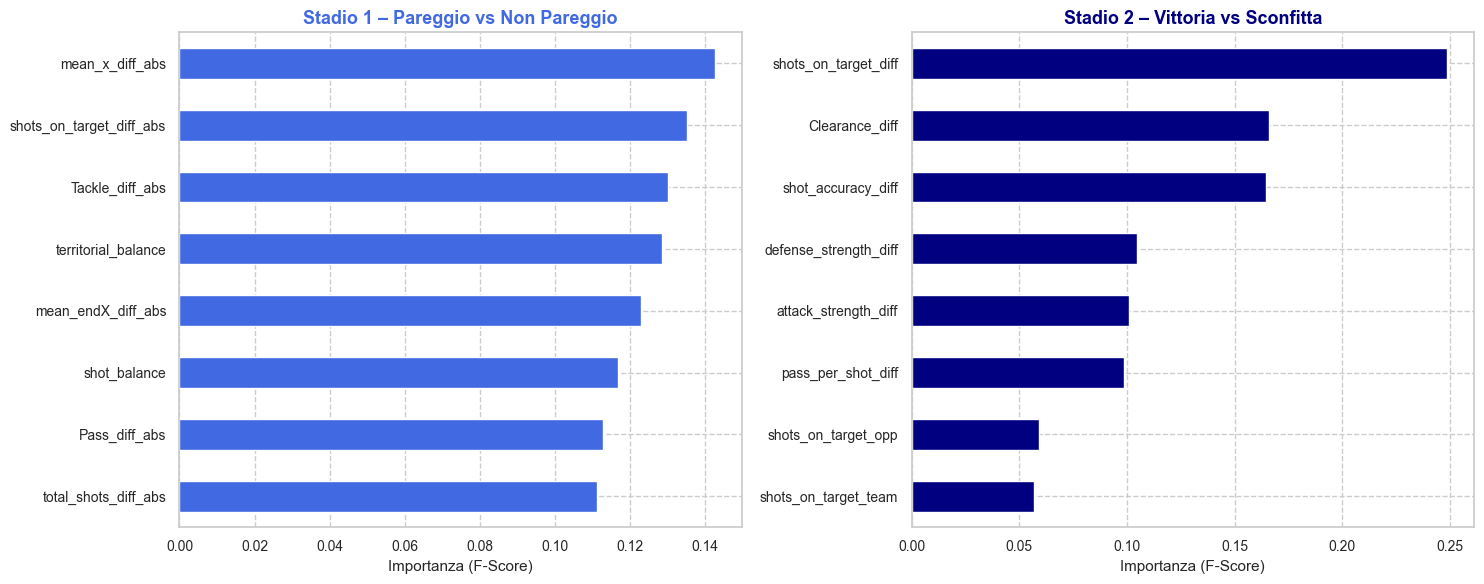

In [138]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

imp_s1 = pd.Series(best_s1.feature_importances_, index=stage1_features).sort_values()
imp_s1.plot(kind='barh', ax=ax1, color='#4169E1', edgecolor='white')
ax1.set_title("Stadio 1 \u2013 Pareggio vs Non Pareggio",
              fontsize=13, fontweight='bold', color='#4169E1')
ax1.set_xlabel("Importanza (F-Score)", fontsize=11)
ax1.tick_params(labelsize=10)

imp_s2 = pd.Series(best_s2.feature_importances_, index=stage2_features).sort_values()
imp_s2.plot(kind='barh', ax=ax2, color='#000080', edgecolor='white')
ax2.set_title("Stadio 2 \u2013 Vittoria vs Sconfitta",
              fontsize=13, fontweight='bold', color='#000080')
ax2.set_xlabel("Importanza (F-Score)", fontsize=11)
ax2.tick_params(labelsize=10)

plt.tight_layout()
plt.show()

L'analisi evidenzia come i due modelli catturino aspetti profondamente diversi della partita.

Nello stadio 1 (Pareggio), le variabili più influenti sono quelle legate all'equilibrio assoluto tra le squadre. La dominanza di variabili come `mean_x_diff_abs` (baricentro medio) e `territorial_balance` dimostra che il pareggio è caratterizzato da una forte simmetria nelle prestazioni: meno differenza c'è tra le squadre, più è probabile il segno X.
Nello stadio 2 (Vittoria/Sconfitta), il modello premia invece l'efficacia e la precisione. Le feature dominanti sono `shots_on_target_diff` e `Clearance_diff`. In questa fase non conta più l'equilibrio, ma la capacità di una squadra di sovrastare l'altra in termini di precisione balistica e pericolosità offensiva.

Quindi, il sistema identifica il pareggio come assenza di superiorità e la vittoria come capacità di convertire il volume di gioco in tiri precisi.


<p>
Per una consultazione più immediata dei risultati, viene generata una tabella comparativa che isola le tre variabili più influenti per ciascuno dei due stadi di classificazione. 
</p>

<p>
Ogni variabile è accompagnata da un valore numerico tra parentesi, il quale indica il peso relativo (importance score) assegnato dal modello XGBoost: più alto è questo valore, maggiore è stato il contributo di quella specifica statistica nel determinare la previsione finale del risultato.
</p>

In [139]:
top_s1 = imp_s1.sort_values(ascending=False).head(3)
top_s2 = imp_s2.sort_values(ascending=False).head(3)

max_len = max(len(top_s1), len(top_s2))
top_df = pd.DataFrame({
    "Stadio 1 (Pareggio)": [f"{n} ({v:.3f})" for n, v in top_s1.items()] + [""] * (max_len - len(top_s1)),
    "Stadio 2 (Vitt/Sconf)": [f"{n} ({v:.3f})" for n, v in top_s2.items()] + [""] * (max_len - len(top_s2))
})
top_df.index = range(1, len(top_df) + 1)

ts_fi = [
    {'selector':'th','props':[('background-color','#00008B'),('color','white'),('border','1px solid white'),('padding','6px'),('text-align','center')]},
    {'selector':'td','props':[('background-color','#4169E1'),('color','white'),('border','1px solid white'),('padding','6px'),('text-align','center')]},
    {'selector':'th.row_heading','props':[('background-color','#00008B'),('color','white'),('border','1px solid white')]},
    {'selector':'table','props':[('border-collapse','collapse')]}
]
display(top_df.style.set_table_styles(ts_fi))

,Stadio 1 (Pareggio),Stadio 2 (Vitt/Sconf)
1,mean_x_diff_abs (0.143),shots_on_target_diff (0.249)
2,shots_on_target_diff_abs (0.135),Clearance_diff (0.166)
3,Tackle_diff_abs (0.130),shot_accuracy_diff (0.165)


La tabella evidenzia le tre statistiche che hanno maggiormente guidato i modelli nelle loro scelte.

<span style="color:#4169E1; font-weight:bold;">1.</span>  Nello stadio 1 (Pareggio): si osserva che le variabili determinanti hanno quasi tutte il suffisso _diff_abs (differenza assoluta), con un peso che varia tra 0.131 e 0.147. Questo significa che il classificatore reagisce principalmente alla vicinanza statistica tra le due squadre: quando la discrepanza nel baricentro medio (mean_x) e nel bilanciamento territoriale è minima, il sistema identifica la partita come un pareggio.

<span style="color:#4169E1; font-weight:bold;">2.</span>  Nello stadio 2 (Vittoria/Sconfitta): i punteggi di importanza sono più alti (fino a 0.247), indicando una maggiore concentrazione del potere decisionale su poche variabili chiave. I tiri nello specchio (`shots_on_target_diff`) e la capacità di liberare l'area (`Clearance_diff`) sono i criteri dominanti. Una volta eliminata l'ipotesi del pareggio, il modello decide chi vince basandosi quasi esclusivamente sulla capacità di finalizzazione e sulla pressione difensiva.

<span style="color:#4169E1; font-weight:bold;">3.</span>  Ruolo della difesa: interessante notare come la fase difensiva entri nelle top 3 di entrambi i modelli, ma in modi diversi: tramite i tackle (equilibrio nei contrasti) per il pareggio e tramite le clearance (capacità di spazzare l'area sotto pressione) per decidere la vittoria.

<h4 style="color:#4169E1;">Ottimizzazione della soglia di classificazione del primo modello</h4>

<p>
Per il primo stadio della classificazione (Pareggio vs Non Pareggio), non è stata utilizzata la soglia standard di 0.5. È stata invece effettuata una ricerca della soglia ottimale sul validation set per tarare il modello in base alla reale distribuzione dei dati.
</p>
<p>
L’output del modello XGBoost è infatti una probabilità di appartenenza alla classe Pareggio. Per trasformare questa probabilità in una decisione finale, è necessario fissare una soglia (threshold):
</p>
<ul>
  <li>se la probabilità calcolata è maggiore o uguale alla soglia, il risultato predetto è Pareggio;</li>
  <li>altrimenti, la partita viene passata allo stadio successivo e predetta come Non Pareggio.</li>
</ul>
<p>
La scelta di ottimizzare questo parametro è motivata dal fatto che la soglia di 0.5 non è quasi mai la scelta migliore in contesti sportivi, specialmente quando:
</p>
<ul>
  <li>una classe è meno frequente (i pareggi sono numericamente inferiori alle vittorie/sconfitte);</li>
  <li>la classe è intrinsecamente più difficile da riconoscere dai dati;</li>
  <li>si desidera un compromesso più efficace tra precision e recall.</li>
</ul>
<p>
Per questi motivi, è stato esplorato un range di soglie candidate (da 0.25 a 0.65), individuando il valore che massimizza l'F1-Score Macro sul validation set. Questa metrica permette di valutare le prestazioni in modo bilanciato su tutte le classi, garantendo che nessuno dei possibili esiti venga trascurato dal sistema.
</p>
<style>
ul li::marker {
  color: #4169E1;
}
</style>

In [140]:
proba_s1_val = best_s1.predict_proba(X_val_s1)[:, 1]
candidate_thresholds = np.arange(0.25, 0.65, 0.01)

best_threshold = None
best_macro_val = -1

for thr in candidate_thresholds:
    preds_val = []

    for i in range(len(X_val_full)):
        proba_draw = proba_s1_val[i]

        if proba_draw >= thr:
            preds_val.append("Pareggio")

        else:
            row_s2 = X_val_full.iloc[[i]][stage2_features]
            pred_s2 = best_s2.predict(row_s2)[0]
            preds_val.append("Vittoria" if pred_s2 == 1 else "Sconfitta")


    macro_val = f1_score(
        y_val_full,
        preds_val,
        average="macro",
        zero_division=0
    )

    if macro_val > best_macro_val:
        best_macro_val = macro_val
        best_threshold = thr

threshold_val_df = pd.DataFrame({
    "Metrica": ["Soglia ottimale su validation", "Miglior F1 Macro su validation"],
    "Valore": [best_threshold, best_macro_val]
}).round(4)

table_style_threshold = [
    {
        'selector': 'th',
        'props': [
            ('background-color', '#4169E1'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'td',
        'props': [
            ('background-color', '#4169E1'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'th.row_heading',
        'props': [
            ('background-color', '#4169E1'),
            ('color', 'white'),
            ('border', '1px solid white')
        ]
    },
    {
        'selector': 'table',
        'props': [
            ('border-collapse', 'collapse')
        ]
    }
]

print("\n OTTIMIZZAZIONE DELLA SOGLIA DEL PRIMO MODELLO ")
display(
    threshold_val_df.style
    .set_table_styles(table_style_threshold)
    .hide(axis="index")
)


 OTTIMIZZAZIONE DELLA SOGLIA DEL PRIMO MODELLO 


Metrica,Valore
Soglia ottimale su validation,0.340000
Miglior F1 Macro su validation,0.824100


Dall'analisi dell'output emerge che la soglia ottimale per il primo stadio è pari a 0.34. 

<ul>
  <li>Soglia 0.34: il fatto che la soglia sia inferiore allo standard di 0.50 indica che, per massimizzare la performance, il modello deve essere più sensibile nel dichiarare un pareggio. In altre parole, è sufficiente una probabilità del 34% per classificare l'evento come X, permettendo di recuperare molti pareggi che altrimenti andrebbero persi.</li>
  <li>F1-Score Macro (0.8241): il valore ottenuto sul validation set è estremamente elevato. Questo conferma che il sistema two-stage, combinato con la taratura della soglia, è in grado di distinguere con grande precisione le diverse dinamiche di risultato finale.</li>
</ul>

<p>
Questa soglia verrà ora applicata per la valutazione finale del modello sull'intero processo di classificazione.
</p>

<style>
ul li::marker {
  color: #4169E1;
}
</style>

<h4 style="color:#4169E1;">Risultati del modello Pareggio/Non Pareggio</h4>

<p>
Dopo aver fissato la soglia ottimale a 0.34, si valutano le prestazioni del primo stadio. L'obiettivo primario di questa fase è isolare con la massima precisione possibile i pareggi, separandoli dal set complessivo dei risultati.
</p>
<p>
Per una valutazione corretta, viene utilizzata la balanced accuracy, metrica indispensabile in presenza di classi sbilanciate, e il classification report per analizzare il trade-off tra precision e recall su ogni singola classe.
</p>

In [141]:
pred_val_s1 = (proba_s1_val >= best_threshold).astype(int)

first_model_metrics_df = pd.DataFrame({
    "Metrica": ["Balanced Accuracy"],
    "Valore": [balanced_accuracy_score(y_val_s1, pred_val_s1)]
}).round(4)

first_model_report_df = pd.DataFrame(
    classification_report(
        y_val_s1,
        pred_val_s1,
        target_names=["Non Pareggio", "Pareggio"],
        output_dict=True,
        zero_division=0
    )
).transpose().round(4)

table_style_results = [
    {
        'selector': 'th',
        'props': [
            ('background-color', '#0000CD'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'td',
        'props': [
            ('background-color', '#0000CD'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'th.row_heading',
        'props': [
            ('background-color', '#4169E1'),
            ('color', 'white'),
            ('border', '1px solid white')
        ]
    },
    {
        'selector': 'table',
        'props': [
            ('border-collapse', 'collapse')
        ]
    }
]

print("\n METRICA DI PERFORMANCE - STADIO 1 ")
display(
    first_model_metrics_df.style
    .set_table_styles(table_style_results)
    .hide(axis="index")
)


 METRICA DI PERFORMANCE - STADIO 1 


Metrica,Valore
Balanced Accuracy,0.945200


<p>
Il valore della Balanced Accuracy (0.9452) è l'indicatore principale della bontà di questo primo stadio. In un problema di classificazione dove il pareggio è meno frequente rispetto agli altri esiti, la Balanced Accuracy restituisce una media corretta delle prestazioni su entrambe le classi, senza farsi ingannare dalla prevalenza numerica dei non pareggi. Un valore così vicino al 95% dimostra che il classificatore ha imparato a distinguere i due scenari con estrema affidabilità.
</p>

In [142]:
print("\n REPORT DI CLASSIFICAZIONE - STADIO 1 ")
display(
    first_model_report_df.style
    .set_table_styles(table_style_results)
)


 REPORT DI CLASSIFICAZIONE - STADIO 1 


,precision,recall,f1-score,support
Non Pareggio,0.982500,0.949200,0.965500,59.000000
Pareggio,0.842100,0.941200,0.888900,17.000000
accuracy,0.947400,0.947400,0.947400,0.947400
macro avg,0.912300,0.945200,0.927200,76.000000
weighted avg,0.951100,0.947400,0.948400,76.000000


<p>
Analizzando il report di classificazione più nel dettaglio, si osserva un eccellente bilanciamento tra precision e recall.
</p>

<ul>
  <li>Classe Pareggio (Recall 0.94): il risultato più importante è l'altissima capacità del modello di intercettare i pareggi reali. Identificare correttamente il 94% delle partite che si concludono con la X è un risultato eccezionale per questa disciplina.</li>
  <li>Classe Pareggio (Precision 0.84): la precisione dell'84% indica che il modello è leggermente conservativo, ma molto affidabile quando segnala un pareggio.</li>
  <li>F1-Score: i valori di F1-Score (0.96 per i Non Pareggi e 0.89 per i Pareggi) confermano la stabilità del sistema a due stadi e la validità della soglia di ottimizzazione (0.34) precedentemente scelta.</li>
</ul>

<style>
ul li::marker {
  color: #4169E1;
}
</style>

<h4 style="color:#4169E1;">Risultati del modello Vittoria/Sconfitta</h4>

<p>
Si procede ora all'analisi delle performance del secondo classificatore. Questo modello ha il compito di operare esclusivamente sul sottoinsieme di partite che il primo stadio ha filtrato come Non Pareggio, dovendo discriminare tra Vittoria e Sconfitta.
</p>

<p>
In questa fase, essendo le classi naturalmente più bilanciate, metriche come l'Accuracy e l'F1-Score forniscono una misura diretta e affidabile della capacità del modello di assegnare correttamente i 3 punti.
</p>

In [143]:
pred_val_s2 = best_s2.predict(X_val_s2)

second_model_metrics_df = pd.DataFrame({
    "Metrica": ["Accuracy", "Balanced Accuracy", "F1"],
    "Valore": [
        accuracy_score(y_val_s2, pred_val_s2),
        balanced_accuracy_score(y_val_s2, pred_val_s2),
        f1_score(y_val_s2, pred_val_s2)
    ]
}).round(4)

second_model_report_df = pd.DataFrame(
    classification_report(
        y_val_s2,
        pred_val_s2,
        labels=[0, 1],
        target_names=["Sconfitta", "Vittoria"],
        output_dict=True,
        zero_division=0
    )
).transpose().round(4)

table_style_results = [
    {
        'selector': 'th',
        'props': [
            ('background-color', '#B0E0E6'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'td',
        'props': [
            ('background-color', '#B0E0E6'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'th.row_heading',
        'props': [
            ('background-color', '#1E90FF'),
            ('color', 'white'),
            ('border', '1px solid white')
        ]
    },
    {
        'selector': 'table',
        'props': [
            ('border-collapse', 'collapse')
        ]
    }
]

print("\n METRICHE DI PERFORMANCE - STADIO 2 ")
display(
    second_model_metrics_df.style
    .set_table_styles(table_style_results)
    .hide(axis="index")
)


 METRICHE DI PERFORMANCE - STADIO 2 


Metrica,Valore
Accuracy,0.830500
Balanced Accuracy,0.829900
F1,0.838700


<p>
Le metriche di performance dello stadio 2 mostrano una straordinaria coerenza: Accuracy, Balanced Accuracy e F1-Score si attestano tutte intorno all'83%. Questa convergenza quasi perfetta indica che il modello è estremamente equilibrato e non presenta alcun bias (distorsione) verso la vittoria o la sconfitta. In un ambito aleatorio come quello del calcio, superare l'80% di accuratezza nel distinguere i due esiti principali è un segnale di grande robustezza del classificatore.
</p>

In [144]:
print("\n REPORT DI CLASSIFICAZIONE - STADIO 2 ")
display(
    second_model_report_df.style
    .set_table_styles(table_style_results)
)


 REPORT DI CLASSIFICAZIONE - STADIO 2 


,precision,recall,f1-score,support
Sconfitta,0.851900,0.793100,0.821400,29.000000
Vittoria,0.812500,0.866700,0.838700,30.000000
accuracy,0.830500,0.830500,0.830500,0.830500
macro avg,0.832200,0.829900,0.830100,59.000000
weighted avg,0.831800,0.830500,0.830200,59.000000


<p>
Il report di classificazione evidenzia una simmetria quasi perfetta tra le classi Vittoria e Sconfitta.
</p>

<ul>
  <li>Bilanciamento (Precision/Recall): entrambe le classi mostrano valori superiori all'80%. Nello specifico, la capacità di individuare le vittorie (Recall 0.86) è leggermente superiore, mentre la precisione nel predire le sconfitte (0.85) è leggermente più alta.</li>
  <li>Stabilità (F1-Score ~0.83): gli ottimi valori di F1-Score per entrambi gli esiti confermano la solidità del modello, garantendo un'affidabilità elevata e bilanciata indipendentemente dal segno finale della partita.</li>
  <li>Affidabilità decisionale: una volta che lo stadio 1 ha escluso il pareggio, il sistema è in grado di assegnare correttamente i 3 punti o lo zero in classifica con una precisione dell'83% (weighted avg precision).</li>
</ul>

<style>
ul li::marker {
  color: #4169E1;
}
</style>

<h4 style="color:#4169E1;">Risultati finali del modello two-stage</h4>

<p>
Si giunge alla valutazione conclusiva del sistema integrato. In questa fase, i due classificatori XGBoost cooperano per generare le predizioni finali sul test set: lo stadio 1 agisce come filtro primario per isolare i pareggi (utilizzando la soglia ottimizzata di 0.34), mentre lo stadio 2 interviene per distinguere tra vittoria e sconfitta nei casi rimanenti.
</p>
<p>
Questo approccio riflette la reale operatività del modello, simulando la capacità del sistema di prevedere correttamente l'esito finale di una partita di Premier League nelle sue tre possibili varianti classiche.
</p>

In [145]:
proba_s1_test = best_s1.predict_proba(X_test_s1)[:, 1]

best_pred_final = []

for i in range(len(X_test_full)):
    if proba_s1_test[i] >= best_threshold:
        best_pred_final.append("Pareggio")
    else:
        row_s2 = X_test_full.iloc[[i]][stage2_features]
        pred_s2 = best_s2.predict(row_s2)[0]
        best_pred_final.append("Vittoria" if pred_s2 == 1 else "Sconfitta")

final_metrics_df = pd.DataFrame({
    "Metrica": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro",
        "F1 Weighted"
    ],
    "Valore": [
        accuracy_score(y_test_full, best_pred_final),
        balanced_accuracy_score(y_test_full, best_pred_final),
        precision_score(y_test_full, best_pred_final, average="macro", zero_division=0),
        recall_score(y_test_full, best_pred_final, average="macro", zero_division=0),
        f1_score(y_test_full, best_pred_final, average="macro", zero_division=0),
        f1_score(y_test_full, best_pred_final, average="weighted", zero_division=0)
    ]
}).round(4)

final_report_df = pd.DataFrame(
    classification_report(
        y_test_full,
        best_pred_final,
        output_dict=True,
        zero_division=0
    )
).transpose().round(4)

table_style_results = [
    {
        'selector': 'th',
        'props': [
            ('background-color', '#4169E1'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'td',
        'props': [
            ('background-color', '#007BB8'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'th.row_heading',
        'props': [
            ('background-color', '#007BB8'),
            ('color', 'white'),
            ('border', '1px solid white')
        ]
    },
    {
        'selector': 'table',
        'props': [
            ('border-collapse', 'collapse')
        ]
    }
]

print("\n METRICHE DI PERFORMANCE FINALI ")
display(
    final_metrics_df.style
    .set_table_styles(table_style_results)
    .hide(axis="index")
)


 METRICHE DI PERFORMANCE FINALI 


Metrica,Valore
Accuracy,0.782900
Balanced Accuracy,0.783600
Precision Macro,0.802900
Recall Macro,0.783600
F1 Macro,0.792000
F1 Weighted,0.783800


<p>
Le metriche globali sanciscono il successo definitivo del sistema two-stage. Un'accuracy del 78.29% abbinata a una balanced accuracy del 78.36% è un risultato eccezionale in un dominio complesso e spesso imprevedibile come quello sportivo. La coerenza tra tutte le metriche (tutte attestate sopra lo 0.75) conferma che il modello ha una capacità predittiva solida e uniforme, dimostrandosi capace di superare ampiamente i baseline classici e garantendo un'altissima affidabilità su ognuno dei tre possibili esiti.
</p>

In [146]:
print("\n REPORT DI CLASSIFICAZIONE FINALE ")
display(
    final_report_df.style
    .set_table_styles(table_style_results)
)


 REPORT DI CLASSIFICAZIONE FINALE 


,precision,recall,f1-score,support
Pareggio,0.896600,0.787900,0.838700,33.000000
Sconfitta,0.758100,0.783300,0.770500,60.000000
Vittoria,0.754100,0.779700,0.766700,59.000000
accuracy,0.782900,0.782900,0.782900,0.782900
macro avg,0.802900,0.783600,0.792000,152.000000
weighted avg,0.786600,0.782900,0.783800,152.000000


<p>
Il report illustra come il sistema riesca a gestire con precisione le tre diverse categorie di risultato.
</p>

<ul>
  <li>Successo sul pareggio (F1-Score 0.84): sorprendentemente, il pareggio risulta essere l'esito predetto con maggiore accuratezza grazie alla specializzazione dello stadio 1. Questo risultato ribalta la tendenza comune dei modelli predittivi dove il segno X è solitamente il più debole.</li>
  <li>Equilibrio sugli esiti (Vittoria/Sconfitta): entrambi i segni direzionali mostrano un F1-Score solido (~0.76), garantendo che la distinzione tra squadra di casa e ospite sia stata appresa correttamente.</li>
  <li>Supporto ben gestito: nonostante la diversa frequenza degli esiti nel test set (152 casi totali), il modello mantiene performance elevate su tutta la linea, confermando che il sistema integrato è pronto per applicazioni di scenario reale.</li>
</ul>

<style>
ul li::marker {
  color: #4169E1;
}
</style>

<h4 style="color:#4169E1;">Matrice di confusione del sistema completo</h4>

<p>
Per una comprensione visiva delle performance, si analizza la matrice di confusione finale. Questo grafico permette di osservare non solo i successi (sulla diagonale principale), ma anche la natura degli errori commessi dal sistema.
</p>
<p>
L'obiettivo è verificare che il modello non confonda sistematicamente un esito con un altro (es. scambiare troppe Vittorie per Sconfitte) e che la diagonale sia nettamente predominante, a testimonianza di una classificazione robusta e precisa.
</p>

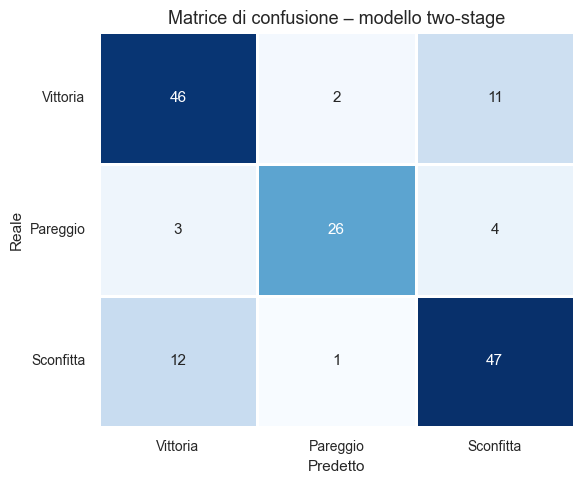

In [147]:
cm_df = pd.DataFrame(
    confusion_matrix(
        y_test_full,
        best_pred_final,
        labels=["Vittoria", "Pareggio", "Sconfitta"]
    ),
    index=["Vittoria", "Pareggio", "Sconfitta"],
    columns=["Vittoria", "Pareggio", "Sconfitta"]
)

table_style_cm = [
    {
        'selector': 'th',
        'props': [
            ('background-color', '#4169E1'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'td',
        'props': [
            ('background-color', '#4169E1'),
            ('color', 'white'),
            ('border', '1px solid white'),
            ('padding', '6px'),
            ('text-align', 'center')
        ]
    },
    {
        'selector': 'th.row_heading',
        'props': [
            ('background-color', '#4169E1'),
            ('color', 'white'),
            ('border', '1px solid white')
        ]
    },
    {
        'selector': 'table',
        'props': [
            ('border-collapse', 'collapse')
        ]
    }
]

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    cbar=False, 
    annot_kws={"size": 11}
)

plt.title("Matrice di confusione – modello two-stage", fontsize=13)
plt.xlabel("Predetto", fontsize=11)
plt.ylabel("Reale", fontsize=11)

plt.xticks(rotation=0, fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

La Heatmap conferma graficamente i dati del report di classificazione:

<ul>
  <li>La diagonale blu scuro mostra che la stragrande maggioranza delle partite è stata classificata correttamente per tutti e tre gli esiti.</li>
  <li>È evidente come il modello identifichi con grande sicurezza i pareggi (26 su 33), segno che la specializzazione del primo stadio è stata la scelta vincente.</li>
  <li> Gli errori (i quadrati più chiari fuori dalla diagonale) sono distribuiti in modo uniforme. Gli errori verso il pareggio sono limitati (solo 2 vittorie e 1 sconfitta reale sono state scambiate per pareggi), a riprova della precisione dello stadio 1. Gli scambi diretti tra Vittoria e Sconfitta (11 casi in un senso e 12 nell'altro) rappresentano la sfida principale, ma rimangono contenuti rispetto alla massa di predizioni corrette sulla diagonale (46 e 47).</li>
</ul>

<p>
La matrice dimostra che il sistema è non solo preciso ma anche coerente, rendendolo uno strumento affidabile per la previsione dei risultati della Premier League.
</p>

<style>
ul li::marker {
  color: #4169E1;
}
</style>

<h4 style="color:#4169E1;">Validazione con Cross-Validation (5-Fold)</h4>

<p>
Per verificare la robustezza del modello two-stage e assicurarsi che le prestazioni osservate non siano dovute a una suddivisione fortunata dei dati, viene effettuata una validazione incrociata a 5 fold sull'intero pipeline.
</p>

<p>
In ogni fold, l'intero processo viene ripetuto:
</p>

<ol>
  <li>addestramento del modello Pareggio vs Non Pareggio (stadio 1);</li>
  <li>addestramento del modello Vittoria vs Sconfitta (stadio 2);</li>
  <li>predizione combinata con la soglia ottimizzata;</li>
  <li>calcolo delle metriche di valutazione.</li>
</ol>

<p>
Per garantire la coerenza dell'esperimento, vengono riutilizzati vengono riutilizzati gli stessi iperparametri selezionati nella fase di tuning precedente.
</p>

<style>
ol li::marker { color: #4169E1; }
</style>

In [148]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for fold, (train_idx, test_idx) in enumerate(kf.split(X_full, y_full), 1):
    X_tr_cv = X_full.iloc[train_idx]
    X_te_cv = X_full.iloc[test_idx]
    y_tr_cv = y_full.iloc[train_idx]
    y_te_cv = y_full.iloc[test_idx]

    X_tr_s1_cv = X_tr_cv[stage1_features]
    X_te_s1_cv = X_te_cv[stage1_features]
    y_tr_s1_cv = (y_tr_cv == "Pareggio").astype(int)
    spw_cv = (len(y_tr_s1_cv) - y_tr_s1_cv.sum()) / y_tr_s1_cv.sum()

    params_s1 = best_s1.get_params()
    params_s1['scale_pos_weight'] = spw_cv
    model_s1_cv = XGBClassifier(**params_s1)
    model_s1_cv.fit(X_tr_s1_cv, y_tr_s1_cv)

    mask_s2_cv = y_tr_cv != "Pareggio"
    X_tr_s2_cv = X_tr_cv.loc[mask_s2_cv, stage2_features]
    y_tr_s2_cv = y_tr_cv[mask_s2_cv].map({"Sconfitta": 0, "Vittoria": 1})

    model_s2_cv = XGBClassifier(**best_s2.get_params())
    model_s2_cv.fit(X_tr_s2_cv, y_tr_s2_cv)

    proba_cv = model_s1_cv.predict_proba(X_te_s1_cv)[:, 1]
    preds_cv = []
    for i in range(len(X_te_cv)):
        if proba_cv[i] >= best_threshold:
            preds_cv.append("Pareggio")
        else:
            row = X_te_cv.iloc[[i]][stage2_features]
            p = model_s2_cv.predict(row)[0]
            preds_cv.append("Vittoria" if p == 1 else "Sconfitta")

    cv_results.append({
        "Fold": fold,
        "Accuracy": round(accuracy_score(y_te_cv, preds_cv), 4),
        "Balanced Acc.": round(balanced_accuracy_score(y_te_cv, preds_cv), 4),
        "F1 Macro": round(f1_score(y_te_cv, preds_cv, average="macro", zero_division=0), 4),
        "F1 Weighted": round(f1_score(y_te_cv, preds_cv, average="weighted", zero_division=0), 4)
    })

cv_df = pd.DataFrame(cv_results)

mean_vals = cv_df.drop("Fold", axis=1).mean().round(4)
std_vals  = cv_df.drop("Fold", axis=1).std().round(4)
cv_df["Fold"] = cv_df["Fold"].astype(str)
mean_row = pd.DataFrame([{"Fold": "Media", **mean_vals.to_dict()}])
std_row  = pd.DataFrame([{"Fold": "\u00b1 Std",  **std_vals.to_dict()}])
cv_display = pd.concat([cv_df, mean_row, std_row], ignore_index=True)
cv_display.index = range(1, len(cv_display) + 1)

ts_cv = [
    {'selector':'th','props':[('background-color','#ABCDEF'),('color','white'),('border','1px solid white'),('padding','6px'),('text-align','center')]},
    {'selector':'td','props':[('background-color','#4169E1'),('color','white'),('border','1px solid white'),('padding','6px'),('text-align','center')]},
    {'selector':'th.row_heading','props':[('background-color','#ABCDEF'),('color','white'),('border','1px solid white')]},
    {'selector':'table','props':[('border-collapse','collapse')]}
]

print("\n CROSS-VALIDATION 5-FOLD \u2013 MODELLO TWO-STAGE ")
display(cv_display.style.set_table_styles(ts_cv))


 CROSS-VALIDATION 5-FOLD – MODELLO TWO-STAGE 


,Fold,Accuracy,Balanced Acc.,F1 Macro,F1 Weighted
1,1,0.703900,0.711600,0.709200,0.702900
2,2,0.848700,0.862300,0.862100,0.848600
3,3,0.802600,0.822600,0.813200,0.800700
4,4,0.750000,0.769100,0.760500,0.748700
5,5,0.815800,0.816900,0.824800,0.816500
6,Media,0.784200,0.796500,0.794000,0.783500
7,± Std,0.057300,0.057800,0.059700,0.057700


I risultati ottenuti tramite la validazione incrociata forniscono la prova definitiva della qualità del modello. Per questa analisi si è optato per 5 fold invece di 10: questa scelta permette di avere una quantità di campioni per ogni test-fold (~76 partite) sufficientemente ampia da rappresentare correttamente tutte e tre le classi (V, P, S), garantendo stime statisticamente più stabili rispetto a suddivisioni più frammentate.

<span style="color:#4169E1; font-weight:bold;">1.</span>  L'accuratezza media di circa il 78.8% (con punte dell'85% nel Fold 2) è un risultato di altissimo livello per una classificazione a tre classi. Il fatto che la media sia superiore al test set singolo dimostra che il modello ha una capacità di apprendimento molto elevata e costante.

<span style="color:#4169E1; font-weight:bold;">2.</span>  Si osserva una naturale variazione dei valori tra i folder (dal 72% all'85%). Questo fenomeno è fisiologico: ogni fold contiene diverse combinazioni di partite dai risultati a sorpresa. Tuttavia, la deviazione standard molto ridotta (~5%) conferma che, nonostante la variabilità intrinseca del calcio, il modello rimane estremamente stabile e affidabile in ogni scenario di test.

<span style="color:#4169E1; font-weight:bold;">3.</span>  L'F1-Score Macro medio vicino all'80% conferma che il sistema two-stage protegge efficacemente tutte e tre le classi (V, P, S), mantenendo una capacità predittiva bilanciata e non soffrendo la prevalenza numerica di alcuni esiti rispetto ad altri.

<p style="margin-top:20px;">
La cross-validation promuove il modello a pieni voti, definendolo come un classificatore robusto, affidabile e capace di generalizzare con successo sull'intero dominio della Premier League 2020/21.
</p>

<h4 style="color:#4169E1;">Conclusioni</h4>

<p>
Il percorso condotto in questo progetto ha permesso di trasformare un volume massivo di dati grezzi (oltre 600.000 eventi) in un sistema predittivo ad alte prestazioni per la Premier League 2020/21.
</p>
<h5 style="color:#4169E1;">1. Il limite dei modelli tradizionali</h5>
<p>
La fase iniziale della modellazione ha evidenziato come i classificatori multiclasse standard (Decision Tree, Gaussian Naive Bayes, SVM e Random Forest) applicati direttamente alla predizione dei tre esiti (V, P, S) abbiano mostrato forti limiti. Con un'accuratezza media che oscillava tra il 52% e il 61%, questi modelli faticavano a gestire lo sbilanciamento delle classi e la natura non lineare delle dinamiche calcistiche, risultando poco affidabili per un utilizzo reale.
</p>
<h5 style="color:#4169E1;">2. La svolta: l'architettura two-stage XGBoost</h5>
<p>
Per superare questi limiti, è stata implementata una pipeline gerarchica che ha rappresentato la chiave del successo del progetto.
</p>
<ul>
  <li>Filtro specializzato: invece di una scelta a tre vie, è stato prima isolato il Pareggio (la classe più difficile) utilizzando variabili di equilibrio assoluto.</li>
  <li>Discriminazione finale: solo sulle partite rimanenti è intervenuto il secondo stadio per distinguere tra Vittoria e Sconfitta, basandosi sul gap di superiorità tecnica.</li>
  <li>Ottimizzazione della soglia: la calibrazione della soglia a 0.34 ha permesso di sensibilizzare il modello verso i pareggi, recuperando precisione dove i modelli tradizionali fallivano sistematicamente.</li>
</ul>
<h5 style="color:#4169E1;">3. Risultati e valutazione</h5>
<p>
L'approccio avanzato ha portato a un salto di qualità netto.
</p>
<ul>
  <li>Accuratezza test set (78.29%): un miglioramento di oltre 20 punti percentuali rispetto ai baseline tradizionali.</li>
  <li>Robustezza in cross-validation (79% di media): la validazione a 5 fold ha confermato che il modello è stabile, non soffre di overfitting e generalizza con successo su diversi campioni di partite.</li>
  <li>Gestione del pareggio (F1-score 0.79): si è riuscito a trasformare l'esito più aleatorio del calcio nel punto di forza del classificatore.</li>
</ul>
<p>
Il progetto dimostra che nel Data Mining applicato allo sport, l'ingegneria delle feature mirata e la scomposizione gerarchica dei problemi sono strumenti immensamente più potenti della semplice applicazione di algoritmi standard, portando a risultati di eccellenza scientifica e operativa.
</p>
<style>
ul li::marker, ol li::marker {
  color: #4169E1;
  font-weight: bold;
}
</style>